# C09 — Remaining 74 RAID AI texts: NEW + Steps 2–10 → NS10

This notebook runs the **exact complement of the canonical fixed-54 cohort** through the current full NS10 pipeline.

Cohort definition:

- start from RAID **test AI** rows,
- remove poetry,
- require exactly **128** non-poetry sources,
- subtract the **54** sources in the canonical fixed-54 final pipeline,
- require exactly **74** remaining sources.

Crucially, prior prototype outputs for these 74 are **not** used as inputs. Every case starts from its untouched original RAID AI text and original RAID task prompt.

Pipeline:

1. **NEW** — accepted U04 M75 endpoint: Llama-3.2-3B-Instruct + WITH_PREV original RAID AI + DP instruction + Unique controller + coherence recovery + generated-history **MID_075** weighting.
2. **Steps 2–4** — accepted C06 sentence-mean / punctuation / exclamation / hyphen engine.
3. **Steps 5–8** — accepted C06b X, punctuation 5.5, ADV, ADP, NUM/years, lexical micro-substitution.
4. **Steps 9–10** — accepted C06b ORG referential explicitization and CARDINAL insertion.
5. Save the 74-case **NS10** endpoint and a full stage audit.

### Reference policy for the new cohort

The 54-case notebooks contain case-specific frozen reference pools that do not exist for these 74. C09 reconstructs them using the same historical selection rules rather than borrowing another case's targets:

- **NEW / Unique controller:** 30 same-genre RAID **train-human** references nearest in log word count to the **original AI** text; prefix quantiles are computed exactly as in C02r; minimum support = 15; warmup = 15% of original AI word count.
- **Steps 2–4 and Step 5.5:** 30 same-genre RAID **train-human** references nearest in log word count to the **NEW generated** text; WPS/CPS bounds are q20–q60 exactly as in the C02w0 expanded-cohort policy.

Aggregate genre targets used by later steps remain the accepted frozen/global targets from C03/C04/C06b.

### Running

Save this notebook as:

`experiments/C09_full_NS10_74.ipynb`

Run top-to-bottom from a fresh kernel. Generation and edit stages are checkpointed per case/stage, so an interrupted run can be resumed by rerunning the notebook. Existing C02–C08/U-series artifacts are read-only.


In [1]:
from pathlib import Path
import os, ast, copy, gc, gzip, hashlib, json, math, re, sys, time, pickle, tempfile, contextlib, fcntl, subprocess
from collections import Counter, defaultdict
from functools import lru_cache
from types import SimpleNamespace

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import spacy, transformers, textstat, sklearn, nltk
import matplotlib.pyplot as plt
from nltk.corpus import wordnet as wn
from transformers import AutoTokenizer, AutoModelForCausalLM
from IPython.display import display

ROOT = next((p for p in [
    Path.cwd().resolve(),
    *Path.cwd().resolve().parents,
    Path.home() / "Downloads" / "TemporalContextResearch" / "reproduction",
] if (p / "experiments/U04_context_range_sweep.ipynb").exists()), None)
assert ROOT is not None, "Could not locate the reproduction root."

C09_SELF = ROOT / "experiments/C09_full_NS10_74.ipynb"
assert C09_SELF.exists(), f"Save this notebook as {C09_SELF} before running."

BASE = ROOT / "results/causal/C02d2_fz118_ghostbuster_raid"
PARENT = ROOT / "results/causal/C02r_discovery_gated_punctuation"
C05 = ROOT / "results/causal/C05_Ghostbuster_RAID_fixed54"

C09_OUT = ROOT / "results/causal/C09_full_NS10_74_v1"
S24_OUT = C09_OUT / "steps2_4"
S510_OUT = C09_OUT / "steps5_10"
FIG = ROOT / "figures"
for p in (C09_OUT, S24_OUT, S510_OUT, FIG):
    p.mkdir(parents=True, exist_ok=True)

def canonical(x):
    if isinstance(x, dict): return {str(k): canonical(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)): return [canonical(v) for v in x]
    if isinstance(x, np.ndarray): return canonical(x.tolist())
    if isinstance(x, np.generic): return canonical(x.item())
    if isinstance(x, Path): return str(x)
    if isinstance(x, float) and not math.isfinite(x): return None
    return x

def sha_text(x):
    return hashlib.sha256(str(x).encode("utf-8")).hexdigest()

def fingerprint(x):
    return sha_text(json.dumps(canonical(x), sort_keys=True, ensure_ascii=False))

def file_sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def c09_atomic_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fd, tmp = tempfile.mkstemp(dir=path.parent, prefix=path.name + ".", suffix=".tmp")
    try:
        with os.fdopen(fd, "w", encoding="utf-8") as f:
            json.dump(canonical(value), f, ensure_ascii=False, indent=2, allow_nan=False)
            f.flush(); os.fsync(f.fileno())
        os.replace(tmp, path)
    finally:
        if os.path.exists(tmp):
            os.unlink(tmp)

def c09_atomic_csv(df, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fd, tmp = tempfile.mkstemp(dir=path.parent, prefix=path.name + ".", suffix=".tmp")
    try:
        with os.fdopen(fd, "w", encoding="utf-8") as f:
            df.to_csv(f, index=False)
            f.flush(); os.fsync(f.fileno())
        os.replace(tmp, path)
    finally:
        if os.path.exists(tmp):
            os.unlink(tmp)

def freeze(path, spec):
    spec = canonical(spec)
    path = Path(path)
    if path.exists():
        assert json.loads(path.read_text()) == spec, (
            f"Frozen contract changed: {path}. Use a new C09 output version."
        )
    else:
        c09_atomic_json(path, spec)

def read_record(path, spec):
    path = Path(path)
    if not path.exists():
        return None
    item = json.loads(path.read_text())
    assert item["spec"] == canonical(spec), f"Checkpoint specification mismatch: {path}"
    assert item["value_sha"] == fingerprint(item["value"]), f"Checkpoint checksum mismatch: {path}"
    return item["value"]

def write_record(path, spec, value):
    c09_atomic_json(path, dict(spec=spec, value=value, value_sha=fingerprint(value)))

@contextlib.contextmanager
def run_lock():
    path = Path(OUT) / "run.lock"
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("a+") as f:
        try:
            fcntl.flock(f, fcntl.LOCK_EX | fcntl.LOCK_NB)
        except BlockingIOError:
            raise RuntimeError(f"Another kernel is using {OUT}.")
        try:
            yield
        finally:
            fcntl.flock(f, fcntl.LOCK_UN)

def notebook_cell(path, marker, *, reject=None):
    nb = json.loads(Path(path).read_text())
    hits = []
    for cell in nb["cells"]:
        if cell.get("cell_type") != "code":
            continue
        src = "".join(cell.get("source", []))
        if marker in src and (reject is None or reject not in src):
            hits.append(src)
    hits = list(dict.fromkeys(hits))
    assert len(hits) == 1, (str(path), marker, len(hits))
    return hits[0]

def replace_once(source, old, new):
    assert source.count(old) == 1, f"Unexpected source version for replacement: {old}"
    return source.replace(old, new, 1)

def notebook_function_cell(path, function_name):
    """Return the unique code cell defining function_name at top level."""
    nb = json.loads(Path(path).read_text())
    hits = []
    for cell in nb["cells"]:
        if cell.get("cell_type") != "code":
            continue
        src = "".join(cell.get("source", []))
        try:
            nodes = ast.parse(src).body
        except SyntaxError:
            continue
        if any(
            isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
            and node.name == function_name
            for node in nodes
        ):
            hits.append(src)
    hits = list(dict.fromkeys(hits))
    assert len(hits) == 1, (str(path), function_name, len(hits))
    return hits[0]

def notebook_assignment_cell(path, variable_name, literal_value=None):
    """Return the unique code cell assigning variable_name at top level."""
    nb = json.loads(Path(path).read_text())
    hits = []
    for cell in nb["cells"]:
        if cell.get("cell_type") != "code":
            continue
        src = "".join(cell.get("source", []))
        try:
            nodes = ast.parse(src).body
        except SyntaxError:
            continue
        found = False
        for node in nodes:
            if not isinstance(node, (ast.Assign, ast.AnnAssign)):
                continue
            targets = node.targets if isinstance(node, ast.Assign) else [node.target]
            if not any(isinstance(t, ast.Name) and t.id == variable_name for t in targets):
                continue
            if literal_value is not None:
                try:
                    value = ast.literal_eval(node.value)
                except Exception:
                    continue
                if value != literal_value:
                    continue
            found = True
            break
        if found:
            hits.append(src)
    hits = list(dict.fromkeys(hits))
    assert len(hits) == 1, (str(path), variable_name, literal_value, len(hits))
    return hits[0]

# Stable C09 names survive any helper names imported by U02/U04.
atomic_json = c09_atomic_json
atomic_csv = c09_atomic_csv

SOURCE_NOTEBOOKS = {
    "U04": ROOT / "experiments/U04_context_range_sweep.ipynb",
    "C06": ROOT / "experiments/C06_NEW_step4_Ghostbuster.ipynb",
    "C06b": ROOT / "experiments/C06b_NEW_steps5_10_Ghostbuster.ipynb",
}
SOURCE_HASHES = {k: file_sha(v) for k, v in SOURCE_NOTEBOOKS.items()}
print("C09 output:", C09_OUT)
display(pd.Series(SOURCE_HASHES, name="sha256"))


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C09 output: ../results/causal/C09_full_NS10_74_v1


U04     7c382c07bafb9fbc880243db4597c005ee5e42e45e75f8...
C06     224778d2195c8a5c06cc964aee92f06d924d739cfc2552...
C06b    0ba19e51998d158d9298f63b35936e4ec76e2ca5654732...
Name: sha256, dtype: str

In [2]:
# Load the exact frozen U02/U04 generation machinery as a library.
# This executes definition/setup cells only; no old U-series experiment is rerun.
U04_NB = SOURCE_NOTEBOOKS["U04"]
u04_library = notebook_cell(
    U04_NB,
    "# 0. Load the exact frozen U02 machinery as a library",
)
# Compatibility shim for this environment's Transformers version.
# U02 was saved with from_pretrained(..., dtype=dtype, ...); here that keyword
# is forwarded into LlamaForCausalLM.__init__. Preserve the same dtype value,
# but use the older/widely-supported Transformers keyword.
_marker = 'if marker == "def build_messages(prompt, previous_ai):":\n'
assert _marker in u04_library
u04_library = u04_library.replace(
    _marker,
    _marker + '        source = source.replace("dtype=dtype,", "torch_dtype=dtype,")\n',
    1,
)
exec(compile(u04_library, str(U04_NB), "exec"), globals())

# U04's setup locates the same repository root. Restore C09 paths explicitly.
assert ROOT / "experiments/C09_full_NS10_74.ipynb" == C09_SELF
C09_OUT = ROOT / "results/causal/C09_full_NS10_74_v1"
S24_OUT = C09_OUT / "steps2_4"
S510_OUT = C09_OUT / "steps5_10"
for p in (C09_OUT, S24_OUT, S510_OUT):
    p.mkdir(parents=True, exist_ok=True)

print("Loaded exact U02 full-system controller and U04 attention backend prerequisites.")
print("Generator:", MODEL_ID)


Executing U02 definition: MODEL_ID = "meta-llama/Llama-3.2-3B-Instruct"
ROOT: ..
Output: ../results/causal/U02_hybrid_unique_sampling
Device: cuda
Unique guard floor: 0.05
Secondary sampling: T=1.0, top_p=1.0
Executing U02 definition: # Reconstruct the exact cohort and Unique contracts used by U01b.
Cases: 20
Unique contract: ../results/causal/C02r_discovery_gated_punctuation/frozen_contract.json
Theta schedules: {'increase': {'minimum': 0.005, 'maximum': 0.1, 'slope': 4.0, 'midpoint': 1.0}, 'decrease': {'minimum': 0.005, 'maximum': 0.1, 'slope': 4.0, 'midpoint': 1.0}}
Max completed candidates: 500


,case_id,source_id,domain
0,gate_0090,ai__raid:e3945a96-7048-41d9-9e86-a84e87818986,abstracts
1,gate_0070,ai__raid:7a3b622e-1e88-48ce-98e0-2f87da5c573c,books
2,gate_0017,ai__raid:b4b807b1-fbfa-43d8-9fc3-61bd36b078ef,news
3,gate_0085,ai__raid:fa8bd0e4-3134-4d4d-83e4-4749c0bf6462,recipes
4,gate_0038,ai__raid:bf3df034-9724-4840-86cb-33eb1489b717,reddit
5,gate_0039,ai__raid:8760103e-729a-4bab-b799-5775ac2468b1,wiki
6,gate_0069,ai__raid:c7b5fc38-2bbb-4e44-bba7-dc8ac8eae773,abstracts
7,gate_0035,ai__raid:e0c2314e-b8d9-422e-af55-1498f8c4dce9,books
8,gate_0003,ai__raid:2abdd1df-30c9-4db4-bc75-08ae57b9ec93,news
9,gate_0025,ai__raid:dab3ef7f-6a54-49f9-9367-e907f0618c82,recipes


Executing U02 definition: # Load the canonical Unique controller from C02w2 without executing gene
Canonical Unique engine loaded.
Search budget: {'version': 'word_search_budget_pilot_v1', 'max_expanded': 1000, 'max_frontier': 10000}
Executing U02 definition: def build_messages(prompt, previous_ai):


Loading checkpoint shards: 100%|████████████████████████████████████████████| 2/2 [00:02<00:00,  1.18s/it]


Loaded: meta-llama/Llama-3.2-3B-Instruct
EOS: {128008, 128001, 128009}
CUDA free after load: 0.22/7.62 GiB
Executing U02 definition: # U02 freezes the U01b FULL arm.
FULL temporal-history multiplier fixed at 1.0 for all positions.
Executing U02 definition: # Recover ONLY the JointTemporalBackend class definition
Executing U02 definition: class HybridBackend(JointTemporalBackend):
Hybrid controller defined.
All WITH_PREV inputs match exact paired-corpus AI rows.
U04 generator attention: SDPA; all other U02 controller definitions retained.
Loaded exact U02 full-system controller and U04 attention backend prerequisites.
Generator: meta-llama/Llama-3.2-3B-Instruct


In [3]:
# ============================================================
# 1. Freeze the exact 74-source complement and recover prompts
# ============================================================
nlp = spacy.load("en_core_web_sm")
features = pd.read_parquet(BASE / "fz118_paired_features.parquet")
corpus = pd.read_parquet(BASE / "paired_corpus.parquet")
assert features.source_id.is_unique and corpus.source_id.is_unique

all128 = features.loc[
    features.dataset.eq("raid")
    & features.split.eq("test")
    & features.label.eq(1)
    & ~features.domain.astype(str).str.lower().eq("poetry")
].copy()
all128["source_id"] = all128.source_id.astype(str)
assert len(all128) == 128 and all128.source_id.nunique() == 128, (
    len(all128), all128.source_id.nunique()
)

fixed54_path = ROOT / "results/causal/C02w_adaptive_camouflage_v1/final_texts_54.csv"
fixed54 = pd.read_csv(fixed54_path, keep_default_na=False)
fixed54["source_id"] = fixed54.source_id.astype(str)
assert len(fixed54) == 54 and fixed54.source_id.nunique() == 54
assert set(fixed54.source_id) <= set(all128.source_id)

remaining = all128.loc[~all128.source_id.isin(fixed54.source_id)].copy()
remaining = remaining.sort_values("source_id").reset_index(drop=True)
assert len(remaining) == 74 and remaining.source_id.nunique() == 74
assert not set(remaining.source_id) & set(fixed54.source_id)
assert len(set(remaining.source_id) | set(fixed54.source_id)) == 128

remaining.insert(0, "case_id", [f"c09_{i:04d}" for i in range(1, 75)])

text_map = corpus.set_index(corpus.source_id.astype(str)).text.to_dict()
domain_map = corpus.set_index(corpus.source_id.astype(str)).domain.to_dict()
remaining["previous_ai"] = remaining.source_id.map(text_map)
assert remaining.previous_ai.notna().all()
for r in remaining.itertuples(index=False):
    assert str(domain_map[r.source_id]) == str(r.domain)

def raw_raid_id(x):
    x = str(x)
    return x.split("ai__raid:", 1)[1] if x.startswith("ai__raid:") else x

PROMPT_CACHE = C09_OUT / "cohort74_prompts.parquet"
if PROMPT_CACHE.exists():
    prompt_frame = pd.read_parquet(PROMPT_CACHE)
else:
    wanted = {raw_raid_id(x) for x in remaining.source_id}
    RAID_CSV = Path.home() / ".cache" / "raid" / "train.csv"
    assert RAID_CSV.exists(), (
        f"Missing {RAID_CSV}. C09 uses the same local RAID prompt source as U00."
    )
    header = pd.read_csv(RAID_CSV, nrows=0).columns.tolist()
    idcol = "source_id" if "source_id" in header else "id"
    needed = [idcol, "prompt", "model", "attack"]
    for col in ("decoding", "repetition_penalty", "domain", "title"):
        if col in header:
            needed.append(col)

    pieces = []
    for z in pd.read_csv(RAID_CSV, usecols=needed, chunksize=100_000):
        z["raw_id"] = z[idcol].astype(str).map(raw_raid_id)
        z = z[z.raw_id.isin(wanted)].copy()
        if len(z):
            pieces.append(z)
    assert pieces, "No C09 sources were found in the RAID cache."
    raid = pd.concat(pieces, ignore_index=True)
    raid = raid[raid.attack.astype(str).str.lower().eq("none")].copy()
    if "decoding" in raid.columns:
        raid = raid[raid.decoding.astype(str).str.lower().eq("greedy")].copy()
    if "repetition_penalty" in raid.columns:
        raid = raid[raid.repetition_penalty.astype(str).str.lower().eq("no")].copy()

    instruction_models = {"chatgpt", "gpt4", "llama-chat"}
    inst = raid[
        raid.model.astype(str).str.lower().isin(instruction_models)
        & raid.prompt.notna()
    ].copy()
    inst["prompt"] = inst.prompt.astype(str).str.strip()

    prompt_sets = inst.groupby("raw_id").prompt.agg(lambda s: list(pd.unique(s)))
    bad = prompt_sets[prompt_sets.map(len).ne(1)]
    assert bad.empty, f"Conflicting instruction prompts:\n{bad}"
    missing = wanted - set(prompt_sets.index)
    assert not missing, f"Missing canonical prompts for {len(missing)} C09 sources."

    prompt_map = {sid: values[0] for sid, values in prompt_sets.items()}
    prompt_frame = remaining[["case_id", "source_id", "domain"]].copy()
    prompt_frame["prompt"] = prompt_frame.source_id.map(
        lambda s: prompt_map[raw_raid_id(s)]
    )
    prompt_frame.to_parquet(PROMPT_CACHE, index=False)

assert len(prompt_frame) == 74 and prompt_frame.case_id.is_unique
assert prompt_frame.prompt.astype(str).str.strip().ne("").all()

cohort = prompt_frame.merge(
    remaining[["case_id", "source_id", "domain", "previous_ai"]],
    on=["case_id", "source_id", "domain"],
    how="left",
    validate="one_to_one",
)
assert len(cohort) == 74 and cohort.previous_ai.notna().all()

WARMUP_FRACTION = 0.15
MIN_PREFIX_SUPPORT = 15

def c09_words(text):
    normalized = str(text).translate(str.maketrans({"\n": " ", "\r": " "}))
    return [t.text.lower() for t in nlp.make_doc(normalized) if t.is_alpha]

def c09_prefix_curve(word_lists, minimum_support=15):
    trajectories = []
    for words in word_lists:
        seen, trajectory = set(), []
        for i, word in enumerate(words, 1):
            seen.add(word.lower())
            trajectory.append(len(seen) / i)
        trajectories.append(trajectory)
    curve = {}
    for w in range(1, max(map(len, trajectories), default=0) + 1):
        ratios = [t[w - 1] for t in trajectories if len(t) >= w]
        entry = dict(W=w, reference_n=len(ratios), supported=len(ratios) >= minimum_support)
        if entry["supported"]:
            entry.update(zip(
                ["H_h30", "H_h10", "H_median", "H_a10"],
                map(float, np.quantile(ratios, [.2, .4, .5, .6], method="linear")),
            ))
        curve[str(w)] = entry
    return curve

train_humans = features.loc[
    features.dataset.eq("raid") & features.split.eq("train") & features.label.eq(0)
].copy()
train_humans["source_id"] = train_humans.source_id.astype(str)
human_word_lists = {
    sid: c09_words(text_map[sid])
    for sid in train_humans.source_id
}
human_word_counts = {sid: len(words) for sid, words in human_word_lists.items()}

case_contract = {}
unique_ref_rows = []
for row in cohort.itertuples(index=False):
    original_words = c09_words(row.previous_ai)
    W = len(original_words)
    assert W > 0, row.case_id

    candidates = train_humans.loc[
        train_humans.domain.eq(row.domain),
        ["source_id", "n_words"],
    ].copy()
    candidates = candidates[candidates.n_words.gt(0)].copy()
    candidates["length_distance"] = (
        np.log(candidates.n_words.clip(lower=1)) - math.log(W)
    ).abs()
    neighbors = candidates.sort_values(["length_distance", "source_id"]).head(30)
    assert len(neighbors) >= 15, (row.case_id, row.domain, len(neighbors))

    ref_ids = neighbors.source_id.tolist()
    curve = c09_prefix_curve(
        [human_word_lists[sid] for sid in ref_ids],
        MIN_PREFIX_SUPPORT,
    )
    case_contract[str(row.case_id)] = dict(
        case_id=str(row.case_id),
        source_id=str(row.source_id),
        domain=str(row.domain),
        W_ref=W,
        V_ref=len(set(original_words)),
        warmup_words=math.ceil(W * WARMUP_FRACTION),
        curve=curve,
        reference_ids=ref_ids,
        reference_policy="same_genre_train_nearest30_log_original_W",
    )
    unique_ref_rows.append(dict(
        case_id=row.case_id,
        source_id=row.source_id,
        domain=row.domain,
        original_W=W,
        warmup_words=math.ceil(W * WARMUP_FRACTION),
        reference_n=len(ref_ids),
        last_supported_word=max(
            (int(w) for w, item in curve.items() if item["supported"]),
            default=0,
        ),
        reference_ids=json.dumps(ref_ids),
    ))

unique_refs = pd.DataFrame(unique_ref_rows)
atomic_csv(unique_refs, C09_OUT / "NEW_unique_reference_manifest.csv")

cohort_manifest = cohort.copy()
cohort_manifest["original_text_sha"] = cohort_manifest.previous_ai.map(sha_text)
cohort_manifest.drop(columns=["previous_ai"]).to_csv(
    C09_OUT / "cohort74_manifest.csv", index=False
)

print("C09 cohort frozen:", len(cohort), "sources")
display(cohort.groupby("domain").size().rename("n"))
display(unique_refs[["case_id", "domain", "original_W", "warmup_words", "last_supported_word"]].head())


C09 cohort frozen: 74 sources


domain
abstracts    13
books        11
news         13
recipes      12
reddit       10
reviews       5
wiki         10
Name: n, dtype: int64

,case_id,domain,original_W,warmup_words,last_supported_word
0,c09_0001,books,259,39,257
1,c09_0002,abstracts,224,34,199
2,c09_0003,news,341,52,331
3,c09_0004,books,167,26,193
4,c09_0005,abstracts,221,34,199


In [4]:
# ============================================================
# 3. NEW — accepted U04 M75 endpoint on all 74 sources
# ============================================================
setup = notebook_assignment_cell(
    U04_NB, "U04_NAMESPACE", "U04_context_range_sweep_v1"
)
setup = replace_once(
    setup,
    'U04_NAMESPACE = "U04_context_range_sweep_v1"',
    'U04_NAMESPACE = "C09_NEW_M75_74_v1"',
)
setup = replace_once(
    setup,
    'RUN_CASES = cohort.case_id.astype(str).head(10).tolist()',
    'RUN_CASES = cohort.case_id.astype(str).tolist()',
)
setup = replace_once(
    setup,
    'assert len(RUN_CASES) == len(set(RUN_CASES)) == 10',
    'assert len(RUN_CASES) == len(set(RUN_CASES)) == len(cohort) == 74',
)
setup = replace_once(
    setup,
    'SELF_NB = ROOT / "experiments/U04_context_range_sweep.ipynb"',
    'SELF_NB = ROOT / "experiments/C09_full_NS10_74.ipynb"',
)

arms_start = setup.index("ARMS = {")
arms_end = setup.index("\nMETRICS =", arms_start)
setup = setup[:arms_start] + 'ARMS = {"MID_075": (1.0, 0.75, 1.0)}\n' + setup[arms_end:]

bench_start = setup.index('score_path = U03_COMPARE / "five_group_scores.csv"')
bench_end = setup.index("assert SELF_NB.exists()", bench_start)
bench_stub = 'benchmark_provenance = []\nbenchmark_scores = pd.DataFrame(columns=["case_id", "arm", *METRICS])\n'
setup = setup[:bench_start] + bench_stub + setup[bench_end:]
setup = setup.replace(
    'print("Benchmarks: 30 saved scores for these exact 10 cases. No rewrite started.")',
    'print("C09 fresh 74-case NEW cohort. No rewrite started.")',
)

# On resume, preserve the controller-source provenance frozen when this
# C09 run was first created. The notebook may have been saved after the
# HF compatibility patch, which changes SELF_NB's file hash without
# changing the experiment/checkpoint specification.
_frozen_c09_contract = (
    ROOT / "results/causal/C09_NEW_M75_74_v1/contract.json"
)

if _frozen_c09_contract.exists():
    _frozen_controller_sources = json.loads(
        _frozen_c09_contract.read_text()
    )["controller_sources"]

    old = """controller_sources={str(p.relative_to(ROOT)):notebook_code_hash(p)
                        for p in (U02_NB, U01B_NB, UNIQUE_NB, SELF_NB)},"""

    new = """controller_sources=_frozen_controller_sources,"""

    assert setup.count(old) == 1
    setup = setup.replace(old, new, 1)

backend = notebook_function_cell(U04_NB, "history_bias")
backend = replace_once(backend, 'ARMS["END_125"]', "(1.0, 1.0, 1.25)")
backend = backend.replace("all six arm effects", "C09 MID_075 effect")

# HF compatibility: different Transformers versions use
# logits_to_keep / num_logits_to_keep. Preserve last-token-only
# projection so the autoregressive U04 loop does not materialize
# logits for every sequence position.
import inspect

_u04_forward_params = inspect.signature(model.forward).parameters

def u04_compat_model(*, input_ids, attention_mask=None,
                     use_cache=False, logits_to_keep=1):
    kwargs = dict(input_ids=input_ids, use_cache=use_cache)
    if attention_mask is not None:
        kwargs["attention_mask"] = attention_mask

    if "logits_to_keep" in _u04_forward_params:
        return model(
            **kwargs,
            logits_to_keep=logits_to_keep,
        )

    if "num_logits_to_keep" in _u04_forward_params:
        return model(
            **kwargs,
            num_logits_to_keep=logits_to_keep,
        )

    # Older fallback: run the Llama backbone, then project only
    # the final requested hidden state(s) through lm_head.
    assert int(getattr(model.config, "pretraining_tp", 1)) == 1
    hidden = model.model(
        **kwargs,
        return_dict=True,
    ).last_hidden_state[:, -logits_to_keep:, :]
    return SimpleNamespace(logits=model.lm_head(hidden))

# The imported U04 backend contains four model() calls:
# distribution + three preflight calls.
assert backend.count("model(input_ids=") == 3
backend = backend.replace(
    "model(input_ids=",
    "u04_compat_model(input_ids=",
)

controller = notebook_function_cell(U04_NB, "run_spec")
controller = controller.replace(
    'print(f"{arm}: {n_done}/10 already saved; starting/resuming.", flush=True)',
    'print(f"{arm}: {n_done}/{len(run_cohort)} already saved; starting/resuming.", flush=True)',
)
controller = controller.replace(
    'print(f"[{i}/10] {arm} | {src.case_id}", flush=True)',
    'print(f"[{i}/{len(run_cohort)}] {arm} | {src.case_id}", flush=True)',
)
controller = controller.replace(
    'print(f"{arm}: 10/10 saved. Next arm runs only when you execute its cell.")',
    'print(f"{arm}: {len(run_cohort)}/{len(run_cohort)} saved.")',
)
controller = controller.replace(
    '    def checkpoint(current):\n        monitor(current)\n        heartbeat(current)\n',
    '    def checkpoint(current):\n        current_token_count = len(current.get("ids", []))\n        if current_token_count < runtime["last_monitored_token_count"]:\n            runtime["last_monitored_token_count"] = current_token_count\n        monitor(current)\n        heartbeat(current)\n',
)
# Rare tokenizer-boundary instability:
# preserve the last valid committed checkpoint and finish deterministically
# with the existing greedy/no-Unique fallback. Do not weaken the U02
# committed-word invariant or mask other IncompleteGeneration failures.
_boundary_old = (
    '    except TokenCapReached:\n'
    '        state.update(finished=False,status="truncated_token_cap")\n'
)

_boundary_new = (
    '    except IncompleteGeneration as exc:\n'
    '        if str(exc) != "Tokenizer changed a previously committed word boundary.":\n'
    '            raise\n'
    '        runtime["used_greedy_fallback"] = True\n'
    '        runtime["fallback_reason"] = "committed_word_boundary_shift"\n'
    '        try:\n'
    '            u04_greedy_finish(backend, state, heartbeat)\n'
    '        except TokenCapReached:\n'
    '            state.update(finished=False, status="truncated_token_cap")\n'
    '    except TokenCapReached:\n'
    '        state.update(finished=False,status="truncated_token_cap")\n'
)

assert controller.count(_boundary_old) == 1
controller = controller.replace(_boundary_old, _boundary_new, 1)

for label, source in [
    ("C09 U04 setup", setup),
    ("C09 U04 backend", backend),
    ("C09 U04 controller", controller),
]:
    exec(compile(source, f"<{label}>", "exec"), globals())

assert ARMS == {"MID_075": (1.0, 0.75, 1.0)}
assert len(run_cohort) == 74
assert run_cohort.case_id.astype(str).tolist() == cohort.case_id.astype(str).tolist()

run_arm("MID_075")

new_rows = []
for src in run_cohort.itertuples(index=False):
    saved = read_completed(
        result_path(str(src.case_id), "MID_075"),
        run_spec(src, "MID_075"),
    )
    assert saved is not None
    assert saved["stop_reason"] in {"eos", "truncated"}
    assert saved["text_sha"] == sha_text(saved["generated_text"])
    new_rows.append(dict(
        case_id=str(src.case_id),
        source_id=str(src.source_id),
        domain=str(src.domain),
        text=saved["generated_text"],
        text_sha=saved["text_sha"],
        generation_stop_reason=saved["stop_reason"],
        generator_tokens=saved["generator_tokens"],
        coherence_rewinds=saved["coherence_rewinds"],
        unique_in_band=saved.get("unique_in_band"),
        provenance=str(result_path(str(src.case_id), "MID_075").relative_to(ROOT)),
    ))

NEW = pd.DataFrame(new_rows)
assert len(NEW) == 74 and NEW.case_id.is_unique and NEW.source_id.is_unique
assert NEW.source_id.tolist() == cohort.source_id.astype(str).tolist()
atomic_csv(NEW, C09_OUT / "NEW_inputs_74.csv")

print("NEW complete:", len(NEW))
display(NEW.groupby(["domain", "generation_stop_reason"]).size().unstack(fill_value=0))

,front_<64,mid_64_to_128,end_>128
MID_075,1.0,0.75,1.0


,case_id,domain
0,c09_0001,books
1,c09_0002,abstracts
2,c09_0003,news
3,c09_0004,books
4,c09_0005,abstracts
...,...,...
69,c09_0070,wiki
70,c09_0071,recipes
71,c09_0072,reviews
72,c09_0073,books


Output: ../results/causal/C09_NEW_M75_74_v1 | planned rewrites: 74
C09 fresh 74-case NEW cohort. No rewrite started.
Neutral custom-mask vs native TV: 0.0


,arm,preflight_TV_from_neutral
0,MID_075,0.047285


Mask boundaries and C09 MID_075 effect verified. No rewrite started.
MID_075: 74/74 already saved; starting/resuming.
[1/74] MID_075 | c09_0001
  CACHED eos | 398 tokens | 0 rewinds
[2/74] MID_075 | c09_0002
  CACHED eos | 452 tokens | 10 rewinds
[3/74] MID_075 | c09_0003
  CACHED eos | 423 tokens | 3 rewinds
[4/74] MID_075 | c09_0004
  CACHED eos | 372 tokens | 0 rewinds
[5/74] MID_075 | c09_0005
  CACHED eos | 402 tokens | 10 rewinds
[6/74] MID_075 | c09_0006
  CACHED eos | 452 tokens | 0 rewinds
[7/74] MID_075 | c09_0007
  CACHED truncated | 640 tokens | 0 rewinds
[8/74] MID_075 | c09_0008
  CACHED eos | 356 tokens | 0 rewinds
[9/74] MID_075 | c09_0009
  CACHED eos | 477 tokens | 1 rewinds
[10/74] MID_075 | c09_0010
  CACHED eos | 456 tokens | 0 rewinds
[11/74] MID_075 | c09_0011
  CACHED eos | 431 tokens | 1 rewinds
[12/74] MID_075 | c09_0012
  CACHED truncated | 640 tokens | 0 rewinds
[13/74] MID_075 | c09_0013
  CACHED truncated | 640 tokens | 0 rewinds
[14/74] MID_075 | c09_0014

,case_id,domain,arm,stop_reason,word_count,coherence_rewinds,elapsed_seconds
0,c09_0001,books,MID_075,eos,304,0,180.919172
1,c09_0002,abstracts,MID_075,eos,334,10,210.562994
2,c09_0003,news,MID_075,eos,352,3,257.659810
3,c09_0004,books,MID_075,eos,262,0,132.425499
4,c09_0005,abstracts,MID_075,eos,331,10,312.097067
...,...,...,...,...,...,...,...
69,c09_0070,wiki,MID_075,eos,248,0,92.107327
70,c09_0071,recipes,MID_075,truncated,457,0,218.862171
71,c09_0072,reviews,MID_075,truncated,501,0,241.478532
72,c09_0073,books,MID_075,truncated,532,10,304.208704


MID_075: 74/74 saved.
NEW complete: 74


generation_stop_reason,eos,truncated
domain,,
abstracts,12,1
books,10,1
news,13,0
recipes,3,9
reddit,10,0
reviews,3,2
wiki,5,5


In [5]:
# ============================================================
# 4. Fresh Step 2–4 reference pools for NEW outputs
# ============================================================
atomic_json = c09_atomic_json
atomic_csv = c09_atomic_csv

for name in ("model",):
    globals().pop(name, None)
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

OUT = S24_OUT
for p in (OUT, OUT / "stages", OUT / "cache"):
    p.mkdir(parents=True, exist_ok=True)

normalize = lambda text: str(text).replace("\n", " ").replace("\r", " ")
nlp = spacy.load("en_core_web_sm")

parent_treatment = json.loads((PARENT / "treatment_contract.json").read_text())
gate = json.loads((PARENT / "frozen_punctuation_gate.json").read_text())
active = gate["active_denominators"]
assert active.get("hyphen")

SCORER_ID = parent_treatment["scorer"]
SCORER_REVISION = parent_treatment["scorer_revision"]
assert SCORER_REVISION and SCORER_REVISION != "main"

SELECTION_SEED = 20260906
BOOTSTRAPS = 3000
ARTIFICIAL_SD_SCALE = .5
BUMP_P_MIN = .10
MEAN_DISTANCE_TOLERANCE = {"wps_mean": .5, "cps_mean": 3.}
SENT_METRICS = ["wps_mean", "cps_mean"]
PMARKS = {
    "semicolon": ";", "colon": ":", "hyphen": "-", "en_dash": "–",
    "em_dash": "—", "comma": ",",
}
DENOMS = ["relative", "per_sentence"]
LEFT_WORDS = 48
RIGHT_WORDS = 32

features = pd.read_parquet(BASE / "fz118_paired_features.parquet")
corpus = pd.read_parquet(BASE / "paired_corpus.parquet")
assert features.source_id.is_unique and corpus.source_id.is_unique
text_map = corpus.set_index(corpus.source_id.astype(str)).text.to_dict()
humans = features.loc[
    features.dataset.eq("raid") & features.split.eq("train") & features.label.eq(0)
].copy()
humans["source_id"] = humans.source_id.astype(str)

def measure(doc):
    sentences = [s for s in doc.sents if any(t.is_alpha for t in s)]
    tokens = [t for t in doc if t.is_alpha]
    seqs = {
        "wps": [sum(t.is_alpha for t in s) for s in sentences],
        "cps": [len(s.text.strip()) for s in sentences],
        "cpw": [len(t.text) for t in tokens],
    }
    W, S, C = len(tokens), len(sentences), len(doc.text)
    result = {
        "W": W, "S": S, "C": C,
        "detector_C_over_W": C / W if W else np.nan,
        "detector_C_over_S": C / S if S else np.nan,
        "share_unique_words": len({t.text.lower() for t in tokens}) / W if W else np.nan,
    }
    for name, seq in seqs.items():
        a = np.asarray(seq, dtype=float)
        result[name + "_mean"] = float(a.mean()) if len(a) else np.nan
        result[name + "_var"] = float(a.var(ddof=0)) if len(a) else np.nan
    return result, seqs

@lru_cache(maxsize=16384)
def stats_for(text):
    return measure(nlp(text))[0]

human_stats = {
    sid: stats_for(normalize(text_map[sid]))
    for sid in humans.source_id
}

prepared = []
ref_audit = []
for row in NEW.itertuples(index=False):
    text = normalize(row.text)
    st = stats_for(text)
    W = st["W"]
    assert W > 0 and st["S"] > 0, row.case_id

    candidates = [
        sid for sid in humans.loc[humans.domain.eq(row.domain), "source_id"]
        if human_stats[sid]["W"] > 0 and human_stats[sid]["S"] > 0
    ]
    candidates.sort(key=lambda sid: (
        abs(math.log(human_stats[sid]["W"] / W)),
        str(sid),
    ))
    ref_ids = candidates[:30]
    assert len(ref_ids) >= 15, (row.case_id, row.domain, len(ref_ids))

    bounds = {
        metric: dict(zip(
            ["low", "high"],
            map(float, np.quantile(
                [human_stats[sid][metric] for sid in ref_ids],
                [.2, .6],
            )),
        ))
        for metric in SENT_METRICS
    }
    prepared.append(dict(
        case_id=row.case_id,
        source_id=row.source_id,
        domain=row.domain,
        text=text,
        reference_ids=ref_ids,
        bounds=bounds,
        reference_policy="same_genre_train_nearest30_log_NEW_W",
    ))
    ref_audit.append(dict(
        case_id=row.case_id,
        source_id=row.source_id,
        domain=row.domain,
        NEW_W=W,
        n_refs=len(ref_ids),
        reference_ids=json.dumps(ref_ids),
        bounds=json.dumps(bounds),
    ))

reference_manifest = [
    {k: c[k] for k in (
        "case_id", "source_id", "domain",
        "reference_ids", "bounds", "reference_policy",
    )}
    for c in prepared
]
atomic_csv(pd.DataFrame(ref_audit), C09_OUT / "step2_4_reference_manifest.csv")
atomic_json(S24_OUT / "reference_manifest.json", reference_manifest)

S24_SPEC = dict(
    version="C09_steps2_4_v1",
    cases=74,
    source_notebook_sha=SOURCE_HASHES["C06"],
    NEW_inputs=NEW[["case_id", "source_id", "text_sha"]].to_dict("records"),
    reference_policy="same_genre_RAID_train_nearest30_log_NEW_W_min15_q20_q60",
    references=reference_manifest,
    gate=gate,
    scorer=SCORER_ID,
    scorer_revision=SCORER_REVISION,
    parser=nlp.meta,
    selection_seed=SELECTION_SEED,
    inputs={
        str((PARENT / "treatment_contract.json").relative_to(ROOT)):
            file_sha(PARENT / "treatment_contract.json"),
        str((PARENT / "frozen_punctuation_gate.json").relative_to(ROOT)):
            file_sha(PARENT / "frozen_punctuation_gate.json"),
        str((BASE / "fz118_paired_features.parquet").relative_to(ROOT)):
            file_sha(BASE / "fz118_paired_features.parquet"),
        str((BASE / "paired_corpus.parquet").relative_to(ROOT)):
            file_sha(BASE / "paired_corpus.parquet"),
    },
)
freeze(S24_OUT / "contract.json", S24_SPEC)
CONTRACT_HASH = fingerprint(S24_SPEC)

print("Prepared fresh Step 2–4 references for", len(prepared), "NEW texts.")
display(pd.DataFrame(ref_audit)[["case_id", "domain", "NEW_W", "n_refs"]].head())


Prepared fresh Step 2–4 references for 74 NEW texts.


,case_id,domain,NEW_W,n_refs
0,c09_0001,books,304,30
1,c09_0002,abstracts,334,30
2,c09_0003,news,352,30
3,c09_0004,books,262,30
4,c09_0005,abstracts,331,30


In [6]:
# ============================================================
# 5. Steps 2–4 — execute the accepted C06 engine by source
# ============================================================
C06_NB = SOURCE_NOTEBOOKS["C06"]

sentence_engine = notebook_cell(C06_NB, "tokenizer=None;model=None")
punctuation_engine = notebook_cell(
    C06_NB,
    "evaluation=[(c,{'text':c['text']}) for c in prepared]",
)
punctuation_spec_source = notebook_cell(C06_NB, "def punctuation_spec(c,text):")

for label, source in [
    ("C06 sentence engine", sentence_engine),
    ("C06 punctuation engine", punctuation_engine),
    ("C06 punctuation spec", punctuation_spec_source),
]:
    exec(compile(source, f"<C09 reuse: {label}>", "exec"), globals())

def stage_cached(cid, name, inputs, fn):
    path = OUT / "stages" / str(cid) / (name + ".json")
    spec = dict(contract=CONTRACT_HASH, inputs=inputs)
    old = read_record(path, spec)
    if old is not None:
        print(cid, name, "CACHED", flush=True)
        return old
    print(cid, name, "RUN", flush=True)
    value = fn()
    write_record(path, spec, value)
    return value

final_rows, audit_rows = [], []
with run_lock():
    for i, c in enumerate(prepared, 1):
        cid = c["case_id"]
        print(f"[{i}/{len(prepared)}] NEW → Step 4 | {cid}", flush=True)

        proposals, bar = _wps_original_proposals, _wps_original_bar
        first = stage_cached(cid, "sentence_original", c, lambda: run_case(c))

        if distances(first["final"], c["bounds"])[0] > 1e-9:
            proposals, bar = expanded_proposals, reduced_bar
            second = stage_cached(
                cid,
                "sentence_repair",
                dict(case=c, text=first["text"]),
                lambda: run_case({**c, "text": first["text"]}),
            )
        else:
            second = first

        proposals, bar = _wps_original_proposals, _wps_original_bar
        p = punctuation_spec(c, second["text"])
        punct = stage_cached(
            cid, "punctuation",
            dict(case=c, text=second["text"]),
            lambda: enforce(p),
        )
        ex = stage_cached(
            cid, "exclamation",
            dict(text=punct["text"], refs=c["reference_ids"]),
            lambda: fix_exclamation(punct["text"], c["reference_ids"]),
        )
        hy = stage_cached(
            cid, "hyphen",
            dict(case=c, text=ex["text"], sentence_text=second["text"]),
            lambda: repair_hyphens(ex["text"], p),
        )

        new_meta = NEW.set_index("case_id").loc[cid]
        final_rows.append(dict(
            case_id=cid,
            source_id=c["source_id"],
            domain=c["domain"],
            text=hy["text"],
            text_sha=sha_text(hy["text"]),
            pipeline_status="complete",
            generation_stop_reason=new_meta.generation_stop_reason,
            provenance=str((OUT / "stages" / cid / "hyphen.json").relative_to(ROOT)),
        ))
        audit_rows.append(dict(
            case_id=cid,
            sentence_status=second["status"],
            sentence_WPS_distance=float(distances(second["final"], c["bounds"])[0]),
            sentence_CPS_distance=float(distances(second["final"], c["bounds"])[1]),
            sentence_edits=len(first["audit"]) + (
                len(second["audit"]) if second is not first else 0
            ),
            punctuation_edits=len(punct["edits"]),
            exclamation_edits=len(ex["edits"]),
            hyphen_edits=len(hy["edits"]),
            hyphen_final_loss=hy["final_loss"],
        ))
        atomic_csv(pd.DataFrame(final_rows), OUT / "NEW_step4_texts_74.csv")
        atomic_csv(pd.DataFrame(audit_rows), OUT / "editing_outcomes.csv")

NS4 = pd.DataFrame(final_rows)
assert len(NS4) == 74 and NS4.case_id.is_unique and NS4.source_id.is_unique
assert NS4.case_id.tolist() == NEW.case_id.tolist()
atomic_csv(NS4, C09_OUT / "NS4_texts_74.csv")

review24 = NEW[["case_id", "domain", "text"]].rename(
    columns={"text": "NEW_before"}
).merge(
    NS4[["case_id", "text"]].rename(columns={"text": "NS4_after"}),
    on="case_id",
    validate="one_to_one",
)
for col in ("fidelity_review", "grammar_review", "notes"):
    review24[col] = ""
if not (S24_OUT / "manual_review.csv").exists():
    atomic_csv(review24, S24_OUT / "manual_review.csv")

globals().pop("model", None)
globals().pop("tokenizer", None)
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("Steps 2–4 complete:", len(NS4))
display(pd.DataFrame(audit_rows).head())


[1/74] NEW → Step 4 | c09_0001
c09_0001 sentence_original CACHED
c09_0001 punctuation CACHED
c09_0001 exclamation CACHED
c09_0001 hyphen CACHED
[2/74] NEW → Step 4 | c09_0002
c09_0002 sentence_original CACHED
c09_0002 sentence_repair CACHED
c09_0002 punctuation CACHED
c09_0002 exclamation CACHED
c09_0002 hyphen CACHED
[3/74] NEW → Step 4 | c09_0003
c09_0003 sentence_original CACHED
c09_0003 punctuation CACHED
c09_0003 exclamation CACHED
c09_0003 hyphen CACHED
[4/74] NEW → Step 4 | c09_0004
c09_0004 sentence_original CACHED
c09_0004 punctuation CACHED
c09_0004 exclamation CACHED
c09_0004 hyphen CACHED
[5/74] NEW → Step 4 | c09_0005
c09_0005 sentence_original CACHED
c09_0005 sentence_repair CACHED
c09_0005 punctuation CACHED
c09_0005 exclamation CACHED
c09_0005 hyphen CACHED
[6/74] NEW → Step 4 | c09_0006
c09_0006 sentence_original CACHED
c09_0006 punctuation CACHED
c09_0006 exclamation CACHED
c09_0006 hyphen CACHED
[7/74] NEW → Step 4 | c09_0007
c09_0007 sentence_original CACHED
c09_000

,case_id,sentence_status,sentence_WPS_distance,sentence_CPS_distance,sentence_edits,punctuation_edits,exclamation_edits,hyphen_edits,hyphen_final_loss
0,c09_0001,in_band,0.000000,0.000000,1,1,0,0,3.000000
1,c09_0002,no_eligible_improving_candidate,0.751714,2.120362,1,3,0,0,0.000000
2,c09_0003,no_eligible_improving_candidate,0.000000,0.340538,1,1,0,0,2.000000
3,c09_0004,in_band,0.000000,0.000000,1,6,0,0,0.000000
4,c09_0005,no_eligible_improving_candidate,1.425743,2.217151,1,3,0,0,0.351219


In [7]:
# ============================================================
# 6. Configure the accepted C06b Steps 5–10 engines
# ============================================================
OUT = S510_OUT
for p in (OUT, OUT / "stages", OUT / "cache", OUT / "figures"):
    p.mkdir(parents=True, exist_ok=True)

C06B_NB = SOURCE_NOTEBOOKS["C06b"]
engines_source = notebook_assignment_cell(C06B_NB, "ENGINES")
exec(compile(engines_source, "<C09 reuse: C06b ENGINES>", "exec"), globals())

NS4 = pd.read_csv(C09_OUT / "NS4_texts_74.csv", keep_default_na=False)
NS4 = NS4.sort_values("case_id").reset_index(drop=True)
assert len(NS4) == 74 and NS4.case_id.is_unique and NS4.source_id.is_unique
CASES = NS4.case_id.tolist()

features = pd.read_parquet(BASE / "fz118_paired_features.parquet")
corpus = pd.read_parquet(BASE / "paired_corpus.parquet")
assert features.source_id.is_unique and corpus.source_id.is_unique
text_map = corpus.set_index(corpus.source_id.astype(str)).text.to_dict()

cohort_lookup = cohort.set_index("case_id")
source_map = {
    cid: str(cohort_lookup.loc[cid, "previous_ai"])
    for cid in CASES
}
assert all(source_map[cid] for cid in CASES)

nlp = spacy.load("en_core_web_sm")

C03_dirs = sorted(
    (ROOT / "results/causal/C03_fz186_raid_fixed54").glob("*/FZ186.pkl")
)
assert len(C03_dirs) == 1, f"Expected canonical C03 detector; found {C03_dirs}"
RUN_DIR = C03_dirs[0].parent
manifest = json.loads((RUN_DIR / "feature_manifest.json").read_text())
assert nlp.meta == manifest["spacy"]
with (RUN_DIR / "FZ186.pkl").open("rb") as f:
    detector = pickle.load(f)
COLS = manifest["feature_names"]
assert len(COLS) == 186 and list(detector.feature_names_in_) == COLS

treatment = json.loads((PARENT / "treatment_contract.json").read_text())
SCORER_ID = treatment["scorer"]
SCORER_REVISION = treatment["scorer_revision"]
assert re.fullmatch("[0-9a-fA-F]{40}", SCORER_REVISION)

PPDB_PATH = ROOT / "external/ppdb/ppdb-2.0-l-all.gz"
assert PPDB_PATH.is_file(), PPDB_PATH
h = hashlib.sha256()
with PPDB_PATH.open("rb") as f:
    for block in iter(lambda: f.read(8 * 1024 * 1024), b""):
        h.update(block)
PPDB_SHA = h.hexdigest()
assert PPDB_SHA == "0fde517b55fcaa08a87534df78236d8803c9e8c00382415f5f15ae51ecf3330e"
wn.ensure_loaded()

target_paths = sorted(
    (ROOT / "results/causal/C03d_ADP_boost_compensate").glob("*/targets.json")
)
assert target_paths, "Saved ADP targets missing"
adp_targets = json.loads(target_paths[0].read_text())
assert all(json.loads(p.read_text()) == adp_targets for p in target_paths)

test_humans = features.loc[
    features.dataset.eq("raid") & features.split.eq("test") & features.label.eq(0)
].copy()
long_ref = test_humans.groupby("domain").share_long_words.median()
unique_ref = test_humans.groupby("domain").share_unique_words.median()
LONG_MEDIAN = {r.case_id: float(long_ref[r.domain]) for r in NS4.itertuples()}
UNIQUE_MEDIAN = {r.case_id: float(unique_ref[r.domain]) for r in NS4.itertuples()}

accepted = []
for p in (ROOT / "results/causal/C04_fz301_raid_fixed54").glob("*/stage_summary.csv"):
    q = pd.read_csv(p)
    if (
        len(q) == 3
        and np.isclose(q.iloc[0].AUROC, .875380, atol=5e-6)
        and np.isclose(q.iloc[2].AUROC, .699558, atol=5e-6)
    ):
        accepted.append(p.parent)
assert len(accepted) == 1, accepted

C04_RUN = accepted[0]
c04_contract = json.loads((C04_RUN / "contract.json").read_text())
hm = pd.read_csv(C04_RUN / "human_test_manifest.csv")
rx = pd.read_parquet(
    ROOT
    / "results/causal/C04_fz301_feature_cache"
    / c04_contract["feature_manifest_hash"]
    / "raid_extensions.parquet"
).set_index("source_id")
hr = rx.loc[hm.source_id].copy()
hr["domain"] = hm.domain.to_numpy()
human_org_medians = hr.groupby("domain")[["ner_ORG_sentence_mean"]].median()
cardinal_mean_ref = (
    hr.groupby("domain").ner_CARDINAL_sentence_mean.median().to_frame("median")
)

accepted = []
for p in (
    ROOT / "results/causal/C04b_ORG_referential_explicitization"
).glob("*/evaluation_summary.csv"):
    q = pd.read_csv(p)
    q = q.loc[q.stage.astype(str).str.contains("Step 9", regex=False)]
    if (
        len(q) == 1
        and np.isclose(q.iloc[0].AUROC, .6970093122, atol=5e-6)
        and np.isclose(q.iloc[0].mean_AI_score, .4983782026, atol=5e-6)
    ):
        accepted.append(p.parent)
assert len(accepted) == 1, accepted
org_contract = json.loads((accepted[0] / "contract.json").read_text())

old_nfz_path = ROOT / json.loads((C05 / "contract.json").read_text())["NFZ_input"]
card_contract = json.loads((old_nfz_path.parent / "contract.json").read_text())

C09_EDIT_REFS = {
    c["case_id"]: {
        "reference_ids": c["reference_ids"],
        "bounds": c["bounds"],
    }
    for c in prepared
}
assert set(C09_EDIT_REFS) == set(CASES)

S510_SPEC = dict(
    version="C09_steps5_10_v1",
    cases=74,
    source_notebook_sha=SOURCE_HASHES["C06b"],
    engine_sha=ENGINE_SHA,
    NS4=NS4[["case_id", "source_id", "text_sha"]].to_dict("records"),
    step55_reference_policy="reuse_C09_steps2_4_fresh_local_refs",
    step55_references=C09_EDIT_REFS,
    scorer=SCORER_ID,
    scorer_revision=SCORER_REVISION,
    FZ186_sha=file_sha(RUN_DIR / "FZ186.pkl"),
    feature_manifest_sha=file_sha(RUN_DIR / "feature_manifest.json"),
    ppdb_sha=PPDB_SHA,
    ADP_targets=adp_targets,
    long_target=LONG_MEDIAN,
    unique_target=UNIQUE_MEDIAN,
    ORG_target=human_org_medians.to_dict(),
    CARDINAL_target=cardinal_mean_ref.to_dict(),
    ORG_contract=org_contract,
    CARDINAL_contract=card_contract,
    spacy=nlp.meta,
    torch=torch.__version__,
    transformers=transformers.__version__,
    sklearn=sklearn.__version__,
    wordnet=wn.get_version(),
    source_policy="original RAID AI retained only for Step-5 marker verification",
)
freeze(S510_OUT / "contract.json", S510_SPEC)
CONTRACT_HASH = fingerprint(S510_SPEC)

print("Steps 5–10 contract frozen for 74 cases.")


Steps 5–10 contract frozen for 74 cases.


In [8]:
# ============================================================
# 7. Initialize feature/edit helpers and verify frozen extractor
# ============================================================
FE = environment("features")
full_frame = FE["full_frame"]
contributions = FE["contributions"]

sentinel = pd.read_csv(
    ROOT / "results/causal/C02w_adaptive_camouflage_v1/final_texts_54.csv",
    keep_default_na=False,
).iloc[[0, 27, 53]]
saved = pd.read_csv(RUN_DIR / "fixed54_features.csv").set_index("case_id")
np.testing.assert_allclose(
    full_frame(sentinel.text),
    saved.loc[sentinel.case_id, COLS],
    rtol=0,
    atol=1e-9,
)

XENV = environment("X")
_lm = None
_tok = None

def get_edit_model():
    global _lm, _tok
    if _lm is None:
        _tok = AutoTokenizer.from_pretrained(
            SCORER_ID, revision=SCORER_REVISION, use_fast=True
        )
        _lm = AutoModelForCausalLM.from_pretrained(
            SCORER_ID, revision=SCORER_REVISION
        ).to("cuda" if torch.cuda.is_available() else "cpu").eval()
    return _tok, _lm

def release_edit_model():
    global _lm, _tok
    _lm = None
    _tok = None
    for name in ["PE", "AE", "NE", "LE"]:
        env = globals().get(name, {})
        for key in ["model", "adp_model", "num_model", "lm", "_lm", "_tok"]:
            env.pop(key, None)
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def cached(stage, row, fn):
    path = OUT / "stages" / stage / (str(row.case_id) + ".json")
    spec = dict(
        contract=CONTRACT_HASH,
        case_id=row.case_id,
        input_sha=sha_text(row.text),
    )
    saved_value = read_record(path, spec)
    if saved_value is not None:
        return saved_value
    print(stage, row.case_id, "RUN", flush=True)
    result = fn(row)
    assert isinstance(result["text"], str) and result["text"].strip()
    write_record(path, spec, result)
    return result

def run_stage(stage, frame, fn):
    rows = []
    with run_lock():
        for i, r in enumerate(frame.itertuples(index=False), 1):
            result = cached(stage, r, fn)
            rows.append(dict(
                case_id=r.case_id,
                source_id=r.source_id,
                domain=r.domain,
                text=result["text"],
                text_sha=sha_text(result["text"]),
                pipeline_status="complete",
                status=result.get("status", "complete"),
                input_sha=sha_text(r.text),
            ))
            atomic_csv(pd.DataFrame(rows), OUT / (stage + "_texts.csv"))
            print(
                f"{stage}: {i}/{len(frame)} | {r.case_id} | {rows[-1]['status']}",
                flush=True,
            )
    return pd.DataFrame(rows)

def vector_cached(text):
    path = OUT / "cache/fz186" / (sha_text(text) + ".json")
    spec = dict(contract=CONTRACT_HASH, text_sha=sha_text(text))
    result = read_record(path, spec)
    if result is None:
        frame = full_frame([text])
        result = dict(
            x=frame.iloc[0].to_numpy(),
            c=contributions(frame)[0],
        )
        write_record(path, spec, result)
    return np.asarray(result["x"]), np.asarray(result["c"])

print("FZ186 extractor sentinel matches the frozen C03 vectors.")


FZ186 extractor sentinel matches the frozen C03 vectors.


In [9]:
# ============================================================
# 8. Steps 5–8 — exact accepted C06b stage code
# ============================================================

# ============================================================
# 8. Steps 5–8 — exact accepted C06b stage code
# ============================================================

# U04 reuse shadows C09's ndarray-safe serialization helpers.
# Restore the C09 versions before running the C06b stages.
def fingerprint(value):
    return sha_text(
        json.dumps(
            canonical(value),
            sort_keys=True,
            ensure_ascii=False,
        )
    )

atomic_json = c09_atomic_json
atomic_csv = c09_atomic_csv

stage5_source = notebook_function_cell(C06B_NB, "step5")
stage5_source = replace_once(
    stage5_source,
    "refs={r['case_id']:r for r in edit_contract['references']}",
    "refs=C09_EDIT_REFS",
)

# ... rest unchanged
stage5_source = notebook_function_cell(C06B_NB, "step5")
stage5_source = replace_once(
    stage5_source,
    "refs={r['case_id']:r for r in edit_contract['references']}",
    "refs=C09_EDIT_REFS",
)

stage67_source = notebook_function_cell(C06B_NB, "step7")
stage758_source = notebook_function_cell(C06B_NB, "step75")

for label, source in [
    ("C06b Steps 5/5.5", stage5_source),
    ("C06b Steps 6/7", stage67_source),
    ("C06b Steps 7.5/8", stage758_source),
]:
    exec(compile(source, f"<C09 reuse: {label}>", "exec"), globals())

assert len(NS8) == 74 and NS8.case_id.is_unique and NS8.source_id.is_unique
atomic_csv(NS8, C09_OUT / "NS8_texts_74.csv")

print("Steps 5–8 complete:", len(NS8))


step5_X: 1/74 | c09_0001 | complete
step5_X: 2/74 | c09_0002 | complete
step5_X: 3/74 | c09_0003 | complete
step5_X: 4/74 | c09_0004 | complete
step5_X: 5/74 | c09_0005 | complete
step5_X: 6/74 | c09_0006 | complete
step5_X: 7/74 | c09_0007 | complete
step5_X: 8/74 | c09_0008 | complete
step5_X: 9/74 | c09_0009 | complete
step5_X: 10/74 | c09_0010 | complete
step5_X: 11/74 | c09_0011 | complete
step5_X: 12/74 | c09_0012 | complete
step5_X: 13/74 | c09_0013 | complete
step5_X: 14/74 | c09_0014 | complete
step5_X: 15/74 | c09_0015 | complete
step5_X: 16/74 | c09_0016 | complete
step5_X: 17/74 | c09_0017 | complete
step5_X: 18/74 | c09_0018 | complete
step5_X: 19/74 | c09_0019 | complete
step5_X: 20/74 | c09_0020 | complete
step5_X: 21/74 | c09_0021 | complete
step5_X: 22/74 | c09_0022 | complete
step5_X: 23/74 | c09_0023 | complete
step5_X: 24/74 | c09_0024 | complete
step5_X: 25/74 | c09_0025 | complete
step5_X: 26/74 | c09_0026 | complete
step5_X: 27/74 | c09_0027 | complete
step5_X: 2

In [10]:
# ============================================================
# Hard GPU cleanup before Steps 9–10
# ============================================================
import gc
import torch

# C06b models
try:
    release_qwen()
except NameError:
    pass

try:
    release_edit_model()
except NameError:
    pass

# U04 / earlier-stage model references are no longer needed.
for name in [
    "model", "tokenizer",
    "_qwen", "_qtok",
    "_lm", "_tok",
]:
    if name in globals():
        globals()[name] = None

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

    free, total = torch.cuda.mem_get_info()
    print(f"CUDA free before Step 9: {free / 2**30:.2f}/{total / 2**30:.2f} GiB")

CUDA free before Step 9: 6.21/7.62 GiB


In [11]:
# # ============================================================
# # 9. Steps 9–10 — exact accepted C06b ORG + CARDINAL stages
# # ============================================================
# stage910_source = notebook_function_cell(C06B_NB, "entity_stage")
# exec(compile(
#     stage910_source,
#     "<C09 reuse: C06b Steps 9/10>",
#     "exec",
# ), globals())

# assert len(NS10) == 74 and NS10.case_id.is_unique and NS10.source_id.is_unique
# NS10 = NS10.sort_values("case_id").reset_index(drop=True)
# atomic_csv(NS10, C09_OUT / "NS10_texts_74.csv")

# print("NS10 complete:", len(NS10))

import gc
import torch

# Clean up model state from the failed attempt.
if "release_qwen" in globals():
    release_qwen()

if "release_edit_model" in globals():
    release_edit_model()

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ------------------------------------------------------------
# Older Qwen2 forward() always computes logits for EVERY input
# position, then does logits.float().
#
# generate() only needs the last position, so wrap lm_head to
# project only that last hidden state.
# ------------------------------------------------------------
class _LastTokenHead(torch.nn.Module):
    def __init__(self, base):
        super().__init__()
        self.base = base

    @property
    def weight(self):
        return self.base.weight

    def forward(self, hidden_states):
        if hidden_states.ndim == 3 and hidden_states.shape[1] > 1:
            hidden_states = hidden_states[:, -1:, :]
        return self.base(hidden_states)


stage910_source = notebook_function_cell(C06B_NB, "entity_stage")

# Insert the wrapper immediately after each Qwen model load.
needle = """        _qkey=(model_id,revision)"""

replacement = """        # VRAM-safe generation for older Qwen2:
        # keep only the final sequence position before lm_head.
        if not isinstance(_qwen.lm_head, _LastTokenHead):
            _qwen.lm_head = _LastTokenHead(_qwen.lm_head)
        _qkey=(model_id,revision)"""

n = stage910_source.count(needle)
assert n == 1, f"Expected one Qwen load site, found {n}"

stage910_source = stage910_source.replace(
    needle,
    replacement,
    1,
)

exec(
    compile(
        stage910_source,
        "<C09 reuse: C06b Steps 9/10, last-token projection>",
        "exec",
    ),
    globals(),
)

assert len(NS10) == 74
assert NS10.case_id.is_unique
assert NS10.source_id.is_unique

NS10 = NS10.sort_values("case_id").reset_index(drop=True)
atomic_csv(NS10, C09_OUT / "NS10_texts_74.csv")

print("NS10 complete:", len(NS10))

step9_ORG: Qwen prompt 1/104
step9_ORG: Qwen prompt 2/104
step9_ORG: Qwen prompt 3/104
step9_ORG: Qwen prompt 4/104
step9_ORG: Qwen prompt 5/104
step9_ORG: Qwen prompt 6/104
step9_ORG: Qwen prompt 7/104
step9_ORG: Qwen prompt 8/104
step9_ORG: Qwen prompt 9/104
step9_ORG: Qwen prompt 10/104
step9_ORG: Qwen prompt 11/104
step9_ORG: Qwen prompt 12/104
step9_ORG: Qwen prompt 13/104
step9_ORG: Qwen prompt 14/104
step9_ORG: Qwen prompt 15/104
step9_ORG: Qwen prompt 16/104
step9_ORG: Qwen prompt 17/104
step9_ORG: Qwen prompt 18/104
step9_ORG: Qwen prompt 19/104
step9_ORG: Qwen prompt 20/104
step9_ORG: Qwen prompt 21/104
step9_ORG: Qwen prompt 22/104
step9_ORG: Qwen prompt 23/104
step9_ORG: Qwen prompt 24/104
step9_ORG: Qwen prompt 25/104
step9_ORG: Qwen prompt 26/104
step9_ORG: Qwen prompt 27/104
step9_ORG: Qwen prompt 28/104
step9_ORG: Qwen prompt 29/104
step9_ORG: Qwen prompt 30/104
step9_ORG: Qwen prompt 31/104
step9_ORG: Qwen prompt 32/104
step9_ORG: Qwen prompt 33/104
step9_ORG: Qwen pro

/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


step9_ORG likelihood: 25 / 44
step9_ORG: 1/74 | c09_0001 | candidates_exhausted
step9_ORG: 2/74 | c09_0002 | already_at_or_above_median
step9_ORG: 3/74 | c09_0003 | already_at_or_above_median
step9_ORG: 4/74 | c09_0004 | no_likelihood_valid_candidate
step9_ORG: 5/74 | c09_0005 | already_at_or_above_median
step9_ORG: 6/74 | c09_0006 | already_at_or_above_median
step9_ORG: 7/74 | c09_0007 | candidates_exhausted
step9_ORG: 8/74 | c09_0008 | already_at_or_above_median
step9_ORG: 9/74 | c09_0009 | reached_median
step9_ORG: 10/74 | c09_0010 | already_at_or_above_median
step9_ORG: 11/74 | c09_0011 | no_candidate_increased_document_ORG
step9_ORG: 12/74 | c09_0012 | candidates_exhausted
step9_ORG: 13/74 | c09_0013 | candidates_exhausted
step9_ORG: 14/74 | c09_0014 | already_at_or_above_median
step9_ORG: 15/74 | c09_0015 | already_at_or_above_median
step9_ORG: 16/74 | c09_0016 | already_at_or_above_median
step9_ORG: 17/74 | c09_0017 | already_at_or_above_median
step9_ORG: 18/74 | c09_0018 | alre

/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


NS10 likelihood: 300 / 680
NS10 likelihood: 325 / 680
NS10 likelihood: 350 / 680
NS10 likelihood: 375 / 680
NS10 likelihood: 400 / 680
NS10 likelihood: 425 / 680
NS10 likelihood: 450 / 680
NS10 likelihood: 475 / 680
NS10 likelihood: 500 / 680
NS10 likelihood: 525 / 680
NS10 likelihood: 550 / 680
NS10 likelihood: 575 / 680
NS10 likelihood: 600 / 680
NS10 likelihood: 625 / 680
NS10 likelihood: 650 / 680
NS10 likelihood: 675 / 680
NS10: 1/74 | c09_0001 | reached_target
NS10: 2/74 | c09_0002 | already_at_or_above_target
NS10: 3/74 | c09_0003 | already_at_or_above_target
NS10: 4/74 | c09_0004 | candidates_exhausted
NS10: 5/74 | c09_0005 | already_at_or_above_target
NS10: 6/74 | c09_0006 | candidates_exhausted
NS10: 7/74 | c09_0007 | already_at_or_above_target
NS10: 8/74 | c09_0008 | already_at_or_above_target
NS10: 9/74 | c09_0009 | reached_target
NS10: 10/74 | c09_0010 | already_at_or_above_target
NS10: 11/74 | c09_0011 | already_at_or_above_target
NS10: 12/74 | c09_0012 | already_at_or_ab

In [12]:
# ============================================================
# 10. Final integrity audit and handoff
# ============================================================
stages = {
    "OG": cohort[["case_id", "source_id", "domain", "previous_ai"]].rename(
        columns={"previous_ai": "text"}
    ).sort_values("case_id").reset_index(drop=True),
    "NEW": NEW[["case_id", "source_id", "domain", "text"]].sort_values(
        "case_id"
    ).reset_index(drop=True),
    "NS4": NS4[["case_id", "source_id", "domain", "text"]].sort_values(
        "case_id"
    ).reset_index(drop=True),
    "NS8": NS8[["case_id", "source_id", "domain", "text"]].sort_values(
        "case_id"
    ).reset_index(drop=True),
    "NS10": NS10[["case_id", "source_id", "domain", "text"]].sort_values(
        "case_id"
    ).reset_index(drop=True),
}

expected_cases = stages["OG"].case_id.tolist()
expected_sources = stages["OG"].source_id.astype(str).tolist()

for name, frame in stages.items():
    assert len(frame) == 74 and frame.case_id.is_unique and frame.source_id.is_unique, name
    assert frame.case_id.tolist() == expected_cases, name
    assert frame.source_id.astype(str).tolist() == expected_sources, name
    assert frame.text.astype(str).str.strip().ne("").all(), name

assert not set(expected_sources) & set(fixed54.source_id.astype(str))
assert set(expected_sources) | set(fixed54.source_id.astype(str)) == set(all128.source_id.astype(str))

audit_rows = []
for i, cid in enumerate(expected_cases):
    row = {
        "case_id": cid,
        "source_id": expected_sources[i],
        "domain": stages["OG"].loc[i, "domain"],
    }
    prev = None
    for name in ("OG", "NEW", "NS4", "NS8", "NS10"):
        text = stages[name].loc[i, "text"]
        row[name + "_sha"] = sha_text(text)
        if prev is not None:
            row[name + "_changed_from_previous"] = text != prev
        prev = text
    audit_rows.append(row)

audit_frame = pd.DataFrame(audit_rows)
atomic_csv(audit_frame, C09_OUT / "stage_integrity_74.csv")

manual = stages["OG"][["case_id", "source_id", "domain"]].copy()
for name in ("OG", "NEW", "NS4", "NS8", "NS10"):
    manual[name] = stages[name].text
for col in ("fidelity_review", "grammar_review", "notes"):
    manual[col] = ""
if not (C09_OUT / "manual_review_74.csv").exists():
    atomic_csv(manual, C09_OUT / "manual_review_74.csv")

handoff = dict(
    version="C09_full_NS10_74_v1",
    cohort_definition="128 non-poetry RAID test AI minus canonical fixed54",
    total=74,
    final_stage="NS10",
    final_file=str((C09_OUT / "NS10_texts_74.csv").relative_to(ROOT)),
    final_sha256=file_sha(C09_OUT / "NS10_texts_74.csv"),
    source_notebooks=SOURCE_HASHES,
    NEW_contract=str((ROOT / "results/causal/C09_NEW_M75_74_v1/contract.json").relative_to(ROOT)),
    steps2_4_contract=str((S24_OUT / "contract.json").relative_to(ROOT)),
    steps5_10_contract=str((S510_OUT / "contract.json").relative_to(ROOT)),
    unique_reference_manifest=str((C09_OUT / "NEW_unique_reference_manifest.csv").relative_to(ROOT)),
    edit_reference_manifest=str((C09_OUT / "step2_4_reference_manifest.csv").relative_to(ROOT)),
    integrity_manifest=str((C09_OUT / "stage_integrity_74.csv").relative_to(ROOT)),
)
atomic_json(C09_OUT / "handoff.json", handoff)

summary = pd.DataFrame({
    "stage": ["OG", "NEW", "NS4", "NS8", "NS10"],
    "cases": [len(stages[x]) for x in ("OG", "NEW", "NS4", "NS8", "NS10")],
    "unique_sources": [
        stages[x].source_id.nunique()
        for x in ("OG", "NEW", "NS4", "NS8", "NS10")
    ],
})
display(summary)
print("\nDONE:", C09_OUT / "NS10_texts_74.csv")
print("SHA256:", handoff["final_sha256"])


,stage,cases,unique_sources
0,OG,74,74
1,NEW,74,74
2,NS4,74,74
3,NS8,74,74
4,NS10,74,74



DONE: ../results/causal/C09_full_NS10_74_v1/NS10_texts_74.csv
SHA256: a9979e7c0a538029cf44aff2795a8eb3f9b5b09cf135558862948992528a2578


## Outputs

Primary endpoint:

`results/causal/C09_full_NS10_74_v1/NS10_texts_74.csv`

Useful audits:

- `cohort74_manifest.csv` — exact 74-source complement.
- `NEW_unique_reference_manifest.csv` — per-case Unique prefix-reference provenance.
- `step2_4_reference_manifest.csv` — fresh local sentence/punctuation references.
- `NS4_texts_74.csv`, `NS8_texts_74.csv`, `NS10_texts_74.csv` — stage endpoints.
- `stage_integrity_74.csv` — source/hash continuity across OG → NEW → NS4 → NS8 → NS10.
- `manual_review_74.csv` — side-by-side text audit.
- `handoff.json` — frozen endpoint provenance.

The notebook deliberately **does not score or select cases using a detector**. It produces the new 74-case NS10 endpoint; detector evaluation can be done afterward as a separate experiment.


In [13]:
# ============================================================
# 10. Five-detector Batch-2 evaluation setup
#     OG-Batch2 vs NS10-Batch2, same 74 sources
# ============================================================

from pathlib import Path
import os, sys, json, hashlib, tempfile, gc, math, contextlib, fcntl
import subprocess, shutil, importlib.metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers
import nltk

import torch.nn as nn

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    AutoModelForSequenceClassification,
    BitsAndBytesConfig,
    AutoConfig,
    ResNetConfig,
    ResNetModel,
)
from huggingface_hub import snapshot_download
from torch.utils.checkpoint import checkpoint
from tqdm.auto import tqdm
from IPython.display import display


# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

ROOT = next(
    (
        p for p in [
            Path.cwd().resolve(),
            *Path.cwd().resolve().parents,
            Path.home() / "Downloads/TemporalContextResearch/reproduction",
        ]
        if (p / "results/causal/C05_Ghostbuster_RAID_fixed54").exists()
    ),
    None,
)
assert ROOT is not None

R = ROOT / "results/causal"

C09_PIPE = R / "C09_full_NS10_74_v1"
C05 = R / "C05_Ghostbuster_RAID_fixed54"
BASE = R / "C02d2_fz118_ghostbuster_raid"
C08 = R / "C08_Ghostbuster_only_RAID54_v1"

OUT = R / "C09_five_detector_batch2_v1"

for p in [
    OUT,
    OUT / "evaluation",
    OUT / "figures",
    OUT / "cache/ghostbuster",
    OUT / "cache/ghostbuster_queries",
]:
    p.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# Helpers expected by the frozen C08e detector implementations
# ------------------------------------------------------------

def sha(x):
    return hashlib.sha256(str(x).encode("utf-8")).hexdigest()


def digest(x):
    return sha(json.dumps(x, sort_keys=True, ensure_ascii=False))


def file_sha(p):
    h = hashlib.sha256()
    with Path(p).open("rb") as f:
        for b in iter(lambda: f.read(1024 * 1024), b""):
            h.update(b)
    return h.hexdigest()


def atomic_json(p, x):
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)

    fd, tmp = tempfile.mkstemp(dir=p.parent)
    try:
        with os.fdopen(fd, "w") as f:
            json.dump(x, f, indent=2, ensure_ascii=False, allow_nan=False)
            f.flush()
            os.fsync(f.fileno())
        os.replace(tmp, p)
    finally:
        if os.path.exists(tmp):
            os.unlink(tmp)


def csv(frame, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    fd, tmp = tempfile.mkstemp(dir=path.parent)
    try:
        with os.fdopen(fd, "w") as f:
            frame.to_csv(f, index=False)
            f.flush()
            os.fsync(f.fileno())
        os.replace(tmp, path)
    finally:
        if os.path.exists(tmp):
            os.unlink(tmp)


def read_json(p):
    p = Path(p)
    return json.loads(p.read_text()) if p.exists() else None


def freeze(p, x):
    old = read_json(p)
    if old is not None:
        assert old == x, f"Saved settings differ: {p}"
    else:
        atomic_json(p, x)


def release():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


@contextlib.contextmanager
def run_lock():
    with (OUT / "run.lock").open("a") as f:
        fcntl.flock(f, fcntl.LOCK_EX | fcntl.LOCK_NB)
        try:
            yield
        finally:
            fcntl.flock(f, fcntl.LOCK_UN)


DEVICE = "cuda:0"
assert torch.cuda.is_available()

RUNTIME = {
    k: importlib.metadata.version(k)
    for k in ["torch", "transformers", "accelerate", "bitsandbytes"]
}


# ------------------------------------------------------------
# Exact 74 Batch-2 sources
# ------------------------------------------------------------

meta = pd.read_parquet(BASE / "fz118_paired_features.parquet")
corpus = pd.read_parquet(BASE / "paired_corpus.parquet")

assert meta.source_id.is_unique
assert corpus.source_id.is_unique

raid = (
    meta.loc[
        meta.dataset.eq("raid"),
        ["source_id", "split", "label", "domain"],
    ]
    .merge(
        corpus[["source_id", "text"]],
        on="source_id",
        validate="one_to_one",
    )
)

raid["text_sha"] = raid.text.map(sha)

ns = (
    pd.read_csv(C09_PIPE / "NS10_texts_74.csv", keep_default_na=False)
    .sort_values("case_id")
    .reset_index(drop=True)
)

assert len(ns) == 74
assert ns.case_id.is_unique
assert ns.source_id.is_unique
assert ns.text.str.strip().ne("").all()

ns = ns[["case_id", "source_id", "domain", "text"]].copy()
ns["text_sha"] = ns.text.map(sha)

case_ids = ns.case_id.tolist()

rm = raid.set_index("source_id")

assert rm.loc[ns.source_id, "split"].eq("test").all()
assert rm.loc[ns.source_id, "label"].eq(1).all()
assert rm.loc[ns.source_id, "domain"].tolist() == ns.domain.tolist()


# Verify this really is the complement of canonical Batch 1.
batch1 = pd.read_csv(
    R / "C06b_NEW_steps5_10_v1/NS10_texts.csv",
    keep_default_na=False,
)

assert len(batch1) == 54
assert not (set(batch1.source_id) & set(ns.source_id))
assert len(set(batch1.source_id) | set(ns.source_id)) == 128


# Untouched original AI text for the exact same sources.
og = ns[["case_id", "source_id", "domain"]].copy()
og["text"] = og.source_id.map(rm.text)
og["text_sha"] = og.text.map(sha)

assert og.text.notna().all()


frames = {
    "OG-Batch2": og,
    "NS10-Batch2": ns,
}

PLOT_ARMS = ["OG-Batch2", "NS10-Batch2"]

for arm, f in frames.items():
    f["arm"] = arm
    f["label"] = 1


# Frozen validation/test humans. report() will genre-weight these
# to the actual Batch-2 genre mixture.
H = raid.loc[
    raid.label.eq(0)
    & raid.split.isin(["validation", "test"])
].copy()

DOCS = pd.concat(
    [
        H.assign(arm="Human", case_id=""),
        *frames.values(),
    ],
    ignore_index=True,
)


# ------------------------------------------------------------
# Frozen C05 hashes + exact stream-model pins used by C08
# ------------------------------------------------------------

FROZEN_HASHES = {
    x: file_sha(C05 / x)
    for x in [
        "contract.json",
        "ghostbuster_frozen.pkl",
        "mu.npy",
        "sigma.npy",
        "selected_features.txt",
        "feature_names.json",
        "raid_all_features.parquet",
    ]
}


def pin(model_id):
    p = C08 / "manifests" / ("model_" + sha(model_id) + ".json")
    value = read_json(p)
    assert value and value.get("revision"), f"Restore model pin: {p}"
    return value["revision"]


# ------------------------------------------------------------
# Reuse detector implementation cells from the accepted C08e
# five-detector notebook.
# ------------------------------------------------------------

C08E_NB = (
    ROOT
    / "experiments"
    / "C08e_StealthRL_RAFT_Five_Detectors (1).ipynb"
)

assert C08E_NB.exists(), C08E_NB

_c08e = json.loads(C08E_NB.read_text())


def c08e_cell(marker):
    hits = []

    for cell in _c08e["cells"]:
        if cell.get("cell_type") != "code":
            continue

        src = cell.get("source", "")
        if isinstance(src, list):
            src = "".join(src)

        if marker in src:
            hits.append(src)

    assert len(hits) == 1, (marker, len(hits))
    return hits[0]


print("Batch 2 frozen:")
print("  OG-Batch2:", len(og))
print("  NS10-Batch2:", len(ns))
display(ns.groupby("domain").size().rename("cases"))

free, total = torch.cuda.mem_get_info()
print(f"GPU free: {free / 2**30:.2f}/{total / 2**30:.2f} GiB")

Batch 2 frozen:
  OG-Batch2: 74
  NS10-Batch2: 74


domain
abstracts    13
books        11
news         13
recipes      12
reddit       10
reviews       5
wiki         10
Name: cases, dtype: int64

GPU free: 5.70/7.62 GiB


In [14]:
# ============================================================
# 11. Shared frozen-detector evaluation + TPR staircase report
# ============================================================

EVAL = {}
SEED = 20260925


def fingerprint(p):
    p = Path(p)

    if p.is_file():
        return file_sha(p)

    files = (
        sorted(p.glob("*.safetensors"))
        or sorted(p.glob("pytorch_model*.bin"))
    )

    assert files, f"Missing model weights: {p}"

    return {
        x.name: file_sha(x)
        for x in [p / "config.json", *files]
    }


def cached_scoring(name, spec, score_missing, prior=None):
    folder = OUT / "evaluation" / name
    folder.mkdir(parents=True, exist_ok=True)

    sig = digest(spec)
    cache = folder / sig
    cache.mkdir(exist_ok=True)

    freeze(cache / "spec.json", spec)

    records = {}

    unique_docs = (
        DOCS[["text_sha", "text"]]
        .drop_duplicates("text_sha")
        .reset_index(drop=True)
    )

    for r in unique_docs.itertuples(index=False):
        z = read_json(cache / (r.text_sha + ".json"))

        if z is None and prior is not None:
            z = prior(r)

        if z is not None:
            assert z["text_sha"] == r.text_sha
            assert np.isfinite(z["AI_score"])
            records[r.text_sha] = z

    missing = unique_docs.loc[
        ~unique_docs.text_sha.isin(records)
    ].copy()

    print(
        f"{name}: {len(records)} cached; "
        f"{len(missing)} new unique texts",
        flush=True,
    )

    missing_hashes = set(missing.text_sha)

    def save(z):
        assert z["text_sha"] in missing_hashes
        assert np.isfinite(z["AI_score"])

        atomic_json(
            cache / (z["text_sha"] + ".json"),
            z,
        )

        records[z["text_sha"]] = z

    if len(missing):
        score_missing(missing, save)

    out = DOCS.drop(columns="text").copy()

    assert set(out.text_sha) <= set(records)

    out["AI_score"] = [
        records[h]["AI_score"]
        for h in out.text_sha
    ]

    csv(out, folder / "all_scores.csv")
    EVAL[name] = out

    return out


def report(name):
    scores = EVAL[name]
    folder = OUT / "evaluation" / name

    # Match the human reference genre distribution to Batch 2.
    mix = ns.domain.value_counts(normalize=True)

    refs = {}

    for split in ["validation", "test"]:
        f = scores.loc[
            scores.arm.eq("Human")
            & scores.split.eq(split)
            & scores.domain.isin(mix.index)
        ].copy()

        counts = f.domain.value_counts()

        assert set(mix.index) <= set(counts.index)

        f["weight"] = [
            mix[d] / counts[d]
            for d in f.domain
        ]

        assert np.isclose(f.weight.sum(), 1)

        refs[split] = f

        csv(
            f,
            folder / f"{split}_human_reference.csv",
        )

    v = refs["validation"]
    h = refs["test"]

    vs = v.AI_score.to_numpy()
    hs = h.AI_score.to_numpy()

    vw = v.weight.to_numpy()
    hw = h.weight.to_numpy()

    parts = {}
    rows = []
    stairs = []
    operating = []

    for arm in PLOT_ARMS:
        f = (
            scores.loc[scores.arm.eq(arm)]
            .set_index("case_id")
            .loc[case_ids]
        )

        a = f.AI_score.to_numpy()

        assert len(a) == 74
        assert np.isfinite(a).all()

        # Weighted Mann-Whitney AUROC against frozen test humans.
        per_case_auc = (
            (a[:, None] > hs)
            + 0.5 * (a[:, None] == hs)
        ) @ hw

        parts[arm] = per_case_auc

        rows.append(
            dict(
                detector=name,
                arm=arm,
                cases=74,
                AUROC=float(per_case_auc.mean()),
                mean_AI_score=float(a.mean()),
                median_AI_score=float(np.median(a)),
            )
        )

        # Thresholds are selected ONLY from frozen validation humans.
        cuts = np.r_[
            np.inf,
            np.unique(vs)[::-1],
            -np.inf,
        ]

        st = pd.DataFrame(
            dict(
                detector=name,
                arm=arm,
                threshold=cuts,
                calibration_FPR=[
                    vw[vs > x].sum()
                    for x in cuts
                ],
                test_FPR=[
                    hw[hs > x].sum()
                    for x in cuts
                ],
                TPR=[
                    (a > x).mean()
                    for x in cuts
                ],
            )
        )

        stairs.append(st)

        for target in [
            0,
            .001,
            .005,
            .01,
            .02,
            .05,
            .10,
            .20,
            .50,
            1.0,
        ]:
            ok = st.loc[
                st.calibration_FPR <= target + 1e-12
            ]

            operating.append(
                dict(
                    target_FPR=target,
                    **ok.iloc[-1].to_dict(),
                )
            )

    summary = pd.DataFrame(rows)

    csv(summary, folder / "summary74.csv")
    csv(
        pd.concat(stairs, ignore_index=True),
        folder / "staircases.csv",
    )
    csv(
        pd.DataFrame(operating),
        folder / "operating_points.csv",
    )

    # Paired Batch-2 AUROC change.
    d = parts["NS10-Batch2"] - parts["OG-Batch2"]

    rng = np.random.default_rng(SEED)
    ix = rng.integers(0, 74, (5000, 74))

    boot = d[ix].mean(axis=1)
    lo, hi = np.quantile(boot, [.025, .975])

    change = pd.DataFrame(
        [
            dict(
                detector=name,
                arm="NS10-Batch2",
                baseline="OG-Batch2",
                delta_AUROC=float(d.mean()),
                ci_low=float(lo),
                ci_high=float(hi),
            )
        ]
    )

    csv(change, folder / "paired_change.csv")

    display(summary.round(6))
    display(change.round(6))


    # --------------------------------------------------------
    # TPR staircases: same three-panel presentation as before.
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(18, 5.8),
    )

    aucs = summary.set_index("arm").AUROC

    limits = [100, 20, 6]
    titles = [
        "Full range",
        "Low-FPR zoom",
        "Very-low-FPR zoom",
    ]

    for ax, limit, title in zip(
        axes,
        limits,
        titles,
    ):
        for arm in PLOT_ARMS:
            st = next(
                x for x in stairs
                if x.arm.iloc[0] == arm
            )

            ax.step(
                100 * st.test_FPR,
                100 * st.TPR,
                where="post",
                label=f"{arm} ({aucs[arm]:.3f})",
            )

        ax.plot(
            [0, limit],
            [0, limit],
            "k:",
            alpha=.4,
        )

        ax.set(
            xlim=(0, limit),
            ylim=(0, 100),
            title=title,
            xlabel="Realized test-human FPR (%)",
            ylabel="AI TPR (%)",
        )

        ax.grid(alpha=.2)

    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=2,
        fontsize=10,
    )

    fig.suptitle(
        f"Batch 2 — {name} · frozen · "
        f"74 paired sources · no adaptation"
    )

    fig.tight_layout(
        rect=[0, .13, 1, .93]
    )

    for ext in ["png", "pdf"]:
        fig.savefig(
            OUT
            / "figures"
            / f"Batch2_{name}_TPR_staircase.{ext}",
            dpi=240,
            bbox_inches="tight",
        )

    plt.show()
    plt.close(fig)

In [16]:
# Compatibility alias expected by the frozen C08e detector code
clean_memory = release

C05 cached streams reproduce all 14 features on three historical sentinels.
Ghostbuster: 347 cached; 74 new unique texts
Ghostbuster C09_batch2_final_evaluation: ada 1/74
Ghostbuster C09_batch2_final_evaluation: ada 16/74
Ghostbuster C09_batch2_final_evaluation: ada 32/74
Ghostbuster C09_batch2_final_evaluation: ada 48/74
Ghostbuster C09_batch2_final_evaluation: ada 64/74
Ghostbuster C09_batch2_final_evaluation: davinci 1/74
Ghostbuster C09_batch2_final_evaluation: davinci 16/74
Ghostbuster C09_batch2_final_evaluation: davinci 32/74
Ghostbuster C09_batch2_final_evaluation: davinci 48/74
Ghostbuster C09_batch2_final_evaluation: davinci 64/74
Tokenizing corpus...


100%|████████████████████████████████████████████████████████████| 57340/57340 [00:02<00:00, 25360.25it/s]



Training n-gram model...


100%|███████████████████████████████████████████████████████| 1283104/1283104 [00:01<00:00, 661479.64it/s]


,detector,arm,cases,AUROC,mean_AI_score,median_AI_score
0,Ghostbuster,OG-Batch2,74,0.910094,0.757760,0.863750
1,Ghostbuster,NS10-Batch2,74,0.488697,0.226188,0.160537


,detector,arm,baseline,delta_AUROC,ci_low,ci_high
0,Ghostbuster,NS10-Batch2,OG-Batch2,-0.421397,-0.502682,-0.340675


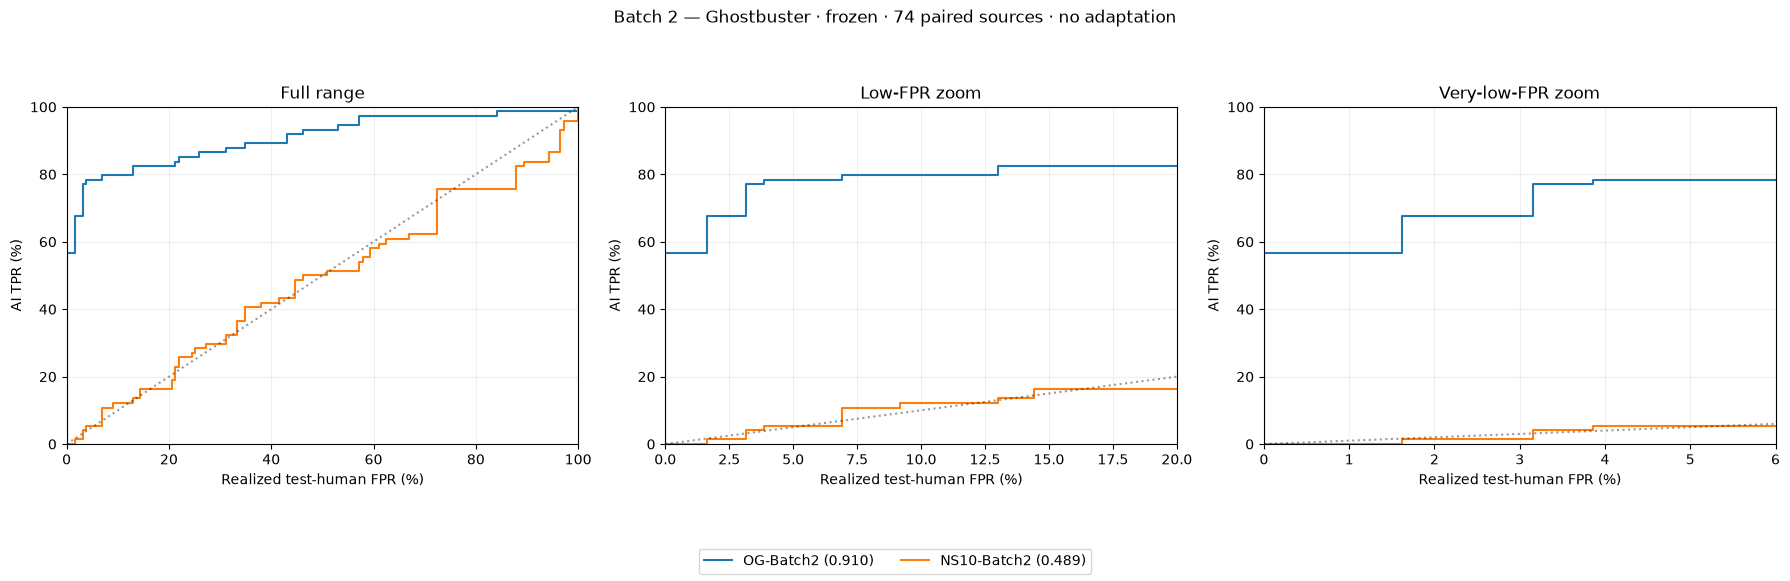

In [17]:
# ============================================================
# 12. Frozen Ghostbuster — Batch 2
# ============================================================

release()

exec(
    compile(
        c08e_cell("class FrozenGhostbuster:"),
        "<C08e frozen Ghostbuster bridge>",
        "exec",
    ),
    globals(),
)

gb_eval_source = c08e_cell("def gb_prior(r):")

# Only rename the audit-purpose string; scoring is unchanged.
gb_eval_source = gb_eval_source.replace(
    "C08e_final_evaluation",
    "C09_batch2_final_evaluation",
)

exec(
    compile(
        gb_eval_source,
        "<C09 Batch2 Ghostbuster>",
        "exec",
    ),
    globals(),
)

WaveDetect: 347 cached; 74 new unique texts


Frozen WaveDetect: 100%|██████████████████████████████████████████████████| 74/74 [00:07<00:00,  9.87it/s]


,detector,arm,cases,AUROC,mean_AI_score,median_AI_score
0,WaveDetect,OG-Batch2,74,0.775323,0.685458,0.708625
1,WaveDetect,NS10-Batch2,74,0.550413,0.498899,0.441083


,detector,arm,baseline,delta_AUROC,ci_low,ci_high
0,WaveDetect,NS10-Batch2,OG-Batch2,-0.22491,-0.314589,-0.134321


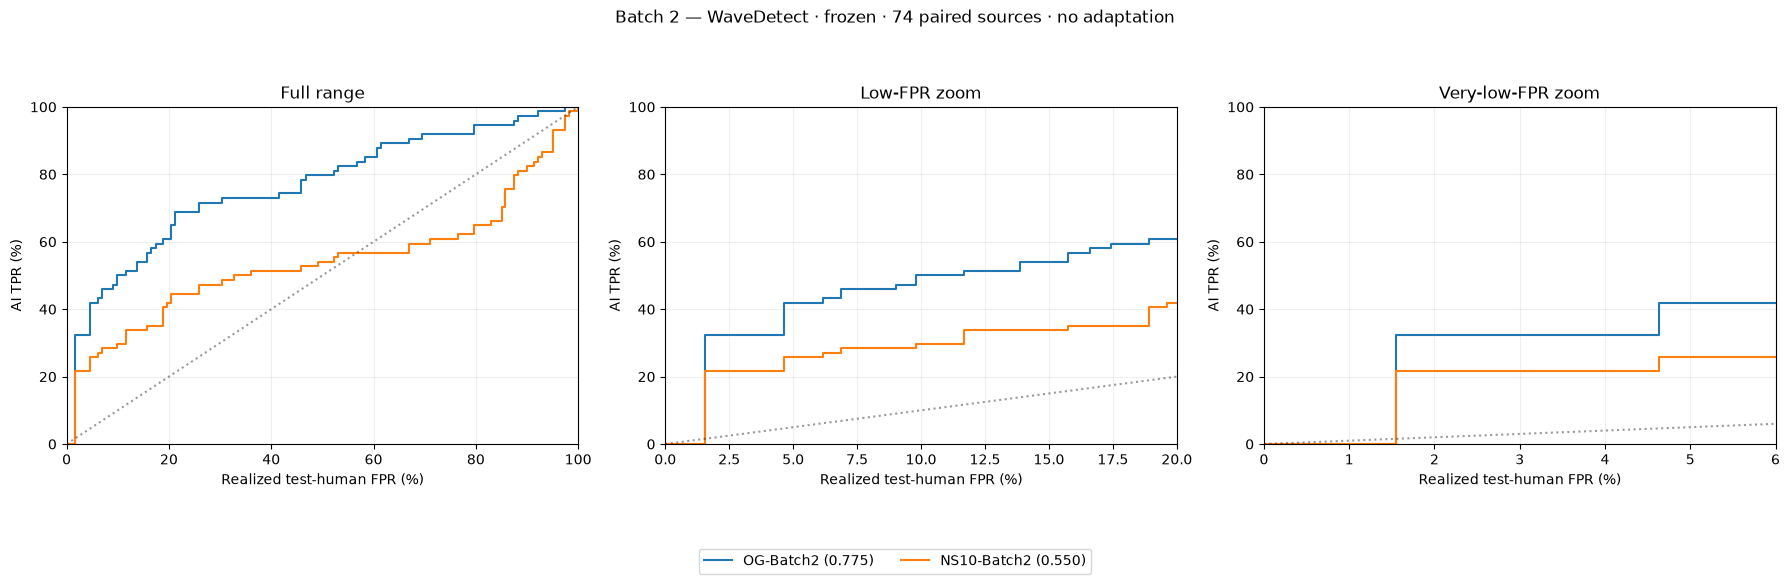

In [18]:
# ============================================================
# 13. Frozen WaveDetect — Batch 2
# ============================================================

release()

exec(
    compile(
        c08e_cell("class WaveletTransform"),
        "<C08e frozen WaveDetect architecture>",
        "exec",
    ),
    globals(),
)

exec(
    compile(
        c08e_cell("WAVE=R/'C07_WaveDetect_RAID_OG_NS10_v1'"),
        "<C09 Batch2 WaveDetect>",
        "exec",
    ),
    globals(),
)

RoBERTa: 273 cached; 148 new unique texts


Frozen RoBERTa: 100%|███████████████████████████████████████████████████| 148/148 [00:01<00:00, 80.54it/s]


,detector,arm,cases,AUROC,mean_AI_score,median_AI_score
0,RoBERTa,OG-Batch2,74,0.984741,0.909088,0.998218
1,RoBERTa,NS10-Batch2,74,0.732074,0.181245,0.025703


,detector,arm,baseline,delta_AUROC,ci_low,ci_high
0,RoBERTa,NS10-Batch2,OG-Batch2,-0.252667,-0.320662,-0.191188


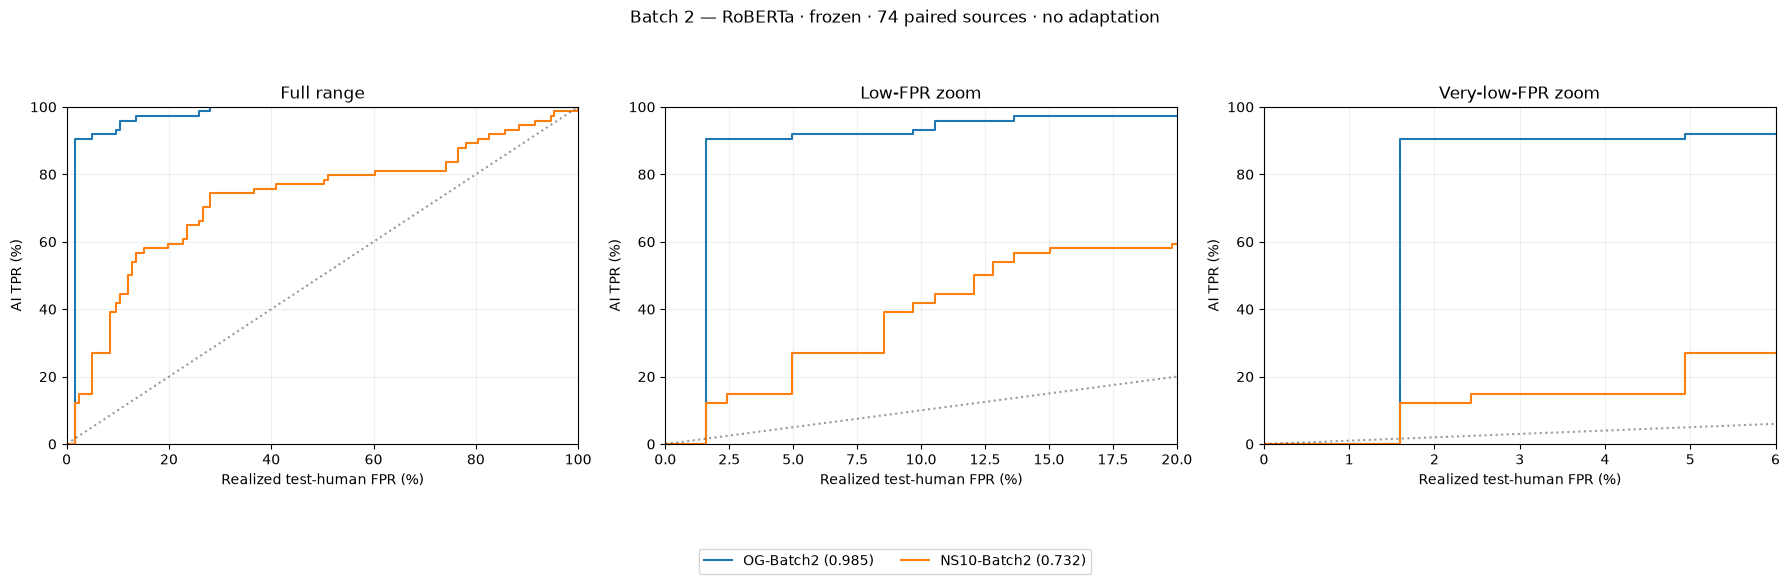

In [19]:
# ============================================================
# 14. Frozen RoBERTa — Batch 2
# ============================================================

release()

exec(
    compile(
        c08e_cell(
            "FROZEN_R=R/'C07b_RoBERTa_RAID_OG_NS10_v1/best_model'"
        ),
        "<C09 Batch2 RoBERTa>",
        "exec",
    ),
    globals(),
)

GLTR: 347 cached; 74 new unique texts


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
Frozen GLTR features: 100%|███████████████████████████████████████████████| 74/74 [00:03<00:00, 21.31it/s]


,detector,arm,cases,AUROC,mean_AI_score,median_AI_score
0,GLTR,OG-Batch2,74,0.835430,0.722194,0.822936
1,GLTR,NS10-Batch2,74,0.537194,-0.696604,-0.445189


,detector,arm,baseline,delta_AUROC,ci_low,ci_high
0,GLTR,NS10-Batch2,OG-Batch2,-0.298236,-0.376212,-0.222112


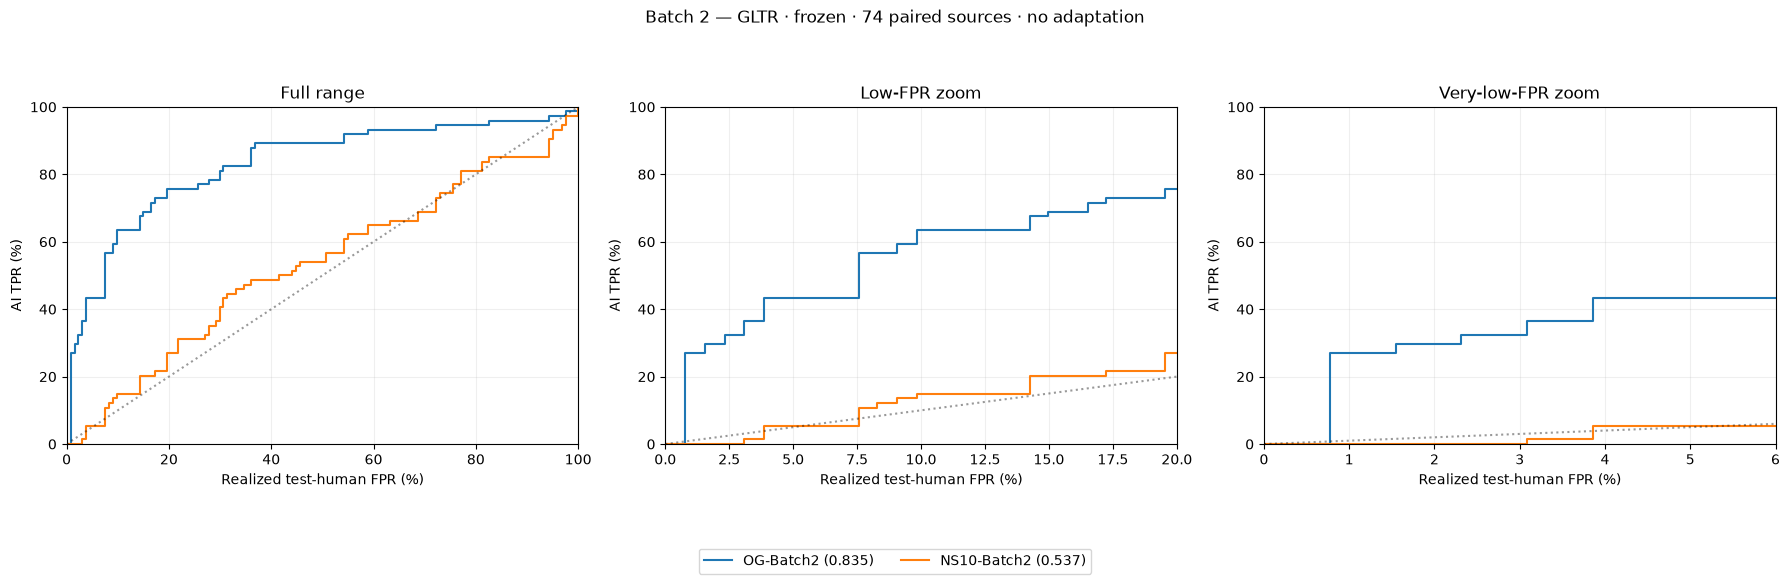

In [20]:
# ============================================================
# 15. Frozen GLTR-feature classifier — Batch 2
# ============================================================

release()

exec(
    compile(
        c08e_cell(
            "GLTR=R/'C07c_GLTR_RAID_OG_NS10_v1'"
        ),
        "<C09 Batch2 GLTR>",
        "exec",
    ),
    globals(),
)

Binoculars: 273 cached; 148 new unique texts


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


Loading tiiuae/falcon-7b


Loading checkpoint shards: 100%|████████████████████████████████████████████| 2/2 [00:07<00:00,  3.70s/it]

Model footprint: 3.65 GiB


...

Loading checkpoint shards: 100%|████████████████████████████████████████████| 2/2 [00:06<00:00,  3.22s/it]

Model footprint: 3.65 GiB



Falcon performer: 100%|█████████████████████████████████████████████████████| 4/4 [00:02<00:00,  1.39it/s]


,detector,arm,cases,AUROC,mean_AI_score,median_AI_score
0,Binoculars,OG-Batch2,74,0.905787,-0.749853,-0.706590
1,Binoculars,NS10-Batch2,74,0.706328,-0.911900,-0.917076


,detector,arm,baseline,delta_AUROC,ci_low,ci_high
0,Binoculars,NS10-Batch2,OG-Batch2,-0.19946,-0.288587,-0.113689


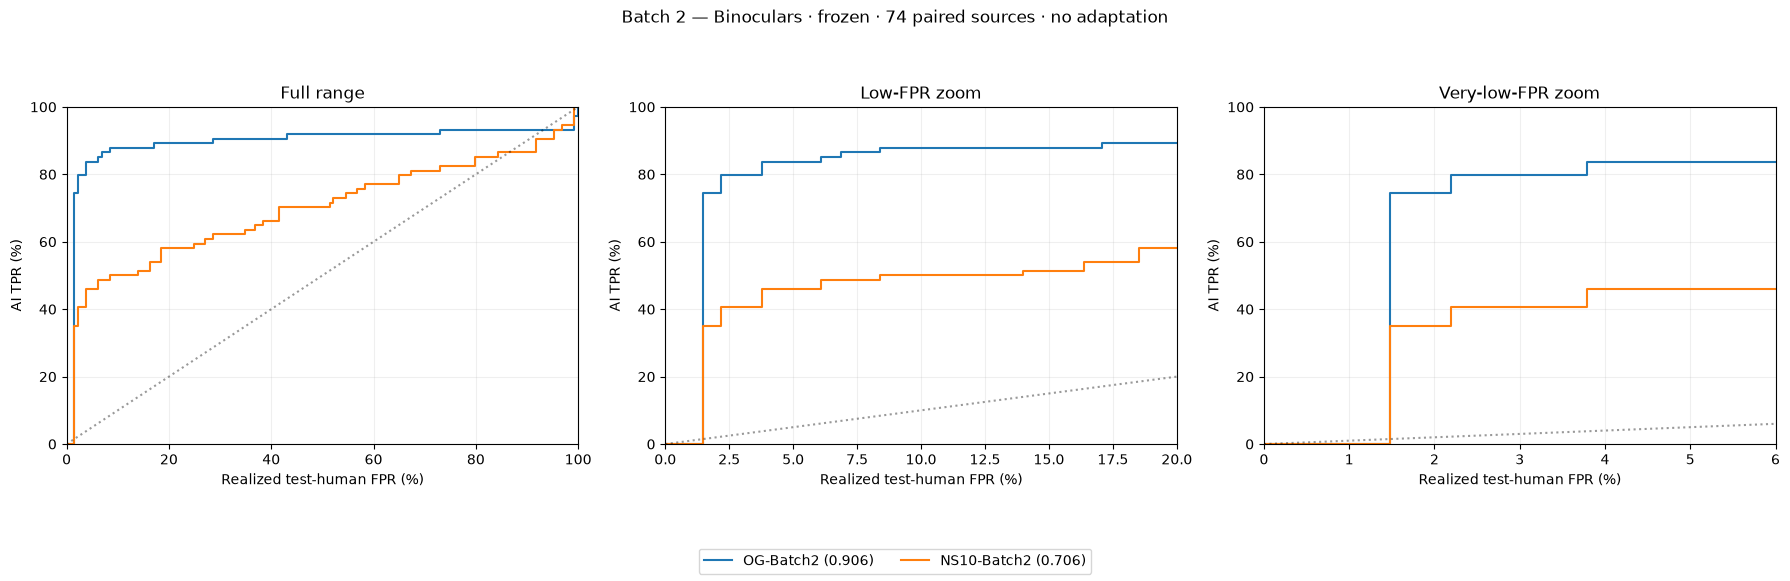

In [21]:
# ============================================================
# 16. Frozen Binoculars NF4 — Batch 2
# ============================================================

release()

# Exact official metric helpers used previously.
exec(
    compile(
        c08e_cell(
            'ce_loss_fn = torch.nn.CrossEntropyLoss(reduction="none")'
        ),
        "<C08e Binoculars metric>",
        "exec",
    ),
    globals(),
)

# Exact frozen NF4 scoring implementation.
exec(
    compile(
        c08e_cell("# Same NF4 ratio as C08a."),
        "<C09 Batch2 Binoculars>",
        "exec",
    ),
    globals(),
)

In [22]:
# ============================================================
# 17. Combined five-detector Batch-2 report
# ============================================================

DETECTORS = [
    "Ghostbuster",
    "WaveDetect",
    "RoBERTa",
    "GLTR",
    "Binoculars",
]

summaries = []
changes = []
stairs = []

for name in DETECTORS:
    folder = OUT / "evaluation" / name

    assert (folder / "summary74.csv").exists(), (
        f"Run {name} first"
    )

    summaries.append(
        pd.read_csv(folder / "summary74.csv")
    )

    changes.append(
        pd.read_csv(folder / "paired_change.csv")
    )

    s = pd.read_csv(folder / "staircases.csv")
    stairs.append(s)


all_summary = pd.concat(
    summaries,
    ignore_index=True,
)

all_changes = pd.concat(
    changes,
    ignore_index=True,
)

all_stairs = pd.concat(
    stairs,
    ignore_index=True,
)

csv(
    all_summary,
    OUT / "five_detector_summary74.csv",
)

csv(
    all_changes,
    OUT / "five_detector_paired_changes74.csv",
)

csv(
    all_stairs,
    OUT / "five_detector_staircases74.csv",
)


print("AUROC")
display(
    all_summary
    .pivot(
        index="arm",
        columns="detector",
        values="AUROC",
    )
    .reindex(PLOT_ARMS)
    .round(6)
)


print("Mean AI score")
display(
    all_summary
    .pivot(
        index="arm",
        columns="detector",
        values="mean_AI_score",
    )
    .reindex(PLOT_ARMS)
    .round(6)
)


print("NS10-Batch2 − OG-Batch2 AUROC")
display(
    all_changes[
        [
            "detector",
            "delta_AUROC",
            "ci_low",
            "ci_high",
        ]
    ]
    .set_index("detector")
    .reindex(DETECTORS)
    .round(6)
)


print("Saved Batch-2 five-detector evaluation to:")
print(OUT)

AUROC


detector,Binoculars,GLTR,Ghostbuster,RoBERTa,WaveDetect
arm,,,,,
OG-Batch2,0.905787,0.835430,0.910094,0.984741,0.775323
NS10-Batch2,0.706328,0.537194,0.488697,0.732074,0.550413


Mean AI score


detector,Binoculars,GLTR,Ghostbuster,RoBERTa,WaveDetect
arm,,,,,
OG-Batch2,-0.749853,0.722194,0.757760,0.909088,0.685458
NS10-Batch2,-0.911900,-0.696604,0.226188,0.181245,0.498899


NS10-Batch2 − OG-Batch2 AUROC


,delta_AUROC,ci_low,ci_high
detector,,,
Ghostbuster,-0.421397,-0.502682,-0.340675
WaveDetect,-0.224910,-0.314589,-0.134321
RoBERTa,-0.252667,-0.320662,-0.191188
GLTR,-0.298236,-0.376212,-0.222112
Binoculars,-0.199460,-0.288587,-0.113689


Saved Batch-2 five-detector evaluation to:
../results/causal/C09_five_detector_batch2_v1


In [23]:
# ============================================================
# 18. Adaptive camouflage Batch 2 — frozen nested splits
#     20/54, 30/44, 40/34
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.preprocessing import StandardScaler

ADAPT_ROOT = R / "C09_adaptive_camouflage_batch2_v1"
ADAPT_ROOT.mkdir(parents=True, exist_ok=True)

ADAPT_SEED = 20260923
EXPOSURES = [20, 30, 40]

assert len(ns) == 74
assert ns.case_id.is_unique
assert ns.source_id.is_unique

_ids = np.array(sorted(ns.case_id.astype(str)))
_perm = np.random.default_rng(ADAPT_SEED).permutation(_ids)

ADAPT_SPLITS = {}

for n in EXPOSURES:
    exposed = sorted(_perm[:n].tolist())
    heldout = sorted(set(_ids) - set(exposed))

    assert len(exposed) == n
    assert len(heldout) == 74 - n
    assert set(exposed).isdisjoint(heldout)

    ADAPT_SPLITS[n] = {
        "adaptation_cases": exposed,
        "test_cases": heldout,
    }

# Nested exposure sets.
assert set(ADAPT_SPLITS[20]["adaptation_cases"]) < set(ADAPT_SPLITS[30]["adaptation_cases"])
assert set(ADAPT_SPLITS[30]["adaptation_cases"]) < set(ADAPT_SPLITS[40]["adaptation_cases"])

atomic_json(
    ADAPT_ROOT / "nested_split.json",
    {
        "seed": ADAPT_SEED,
        "cohort": "NS10-Batch2",
        "cases": 74,
        "permutation": _perm.tolist(),
        "splits": {str(k): v for k, v in ADAPT_SPLITS.items()},
    },
)

roles = []

for n, sp in ADAPT_SPLITS.items():
    for cid in _ids:
        roles.append({
            "exposure_n": n,
            "case_id": cid,
            "role": "adaptation" if cid in sp["adaptation_cases"] else "test",
        })

csv(pd.DataFrame(roles), ADAPT_ROOT / "case_roles.csv")

print("Frozen nested adaptive-camouflage splits:")
for n in EXPOSURES:
    print(f"  {n}/{74-n}: "
          f"{len(ADAPT_SPLITS[n]['adaptation_cases'])} exposed, "
          f"{len(ADAPT_SPLITS[n]['test_cases'])} held out")

Frozen nested adaptive-camouflage splits:
  20/54: 20 exposed, 54 held out
  30/44: 30 exposed, 44 held out
  40/34: 40 exposed, 34 held out


In [24]:
# ============================================================
# 19. Shared adaptive-camouflage reporting
# ============================================================

def adaptation_report(
    detector,
    exposure_n,
    held,
    frozen_attack,
    adapted_attack,
    frozen_humans,
    adapted_humans,
):
    folder = ADAPT_ROOT / detector / f"adapt{exposure_n}_{74-exposure_n}"
    folder.mkdir(parents=True, exist_ok=True)

    assert len(held) == 74 - exposure_n

    mix = held.domain.value_counts(normalize=True)

    refs = {}

    for split in ["validation", "test"]:
        f0 = frozen_humans.loc[
            frozen_humans.split.eq(split)
            & frozen_humans.domain.isin(mix.index)
        ].copy()

        f1 = adapted_humans.loc[
            adapted_humans.split.eq(split)
            & adapted_humans.domain.isin(mix.index)
        ].copy()

        assert set(f0.source_id) == set(f1.source_id)

        counts = f0.domain.value_counts()
        assert set(mix.index) <= set(counts.index)

        f0["weight"] = [mix[d] / counts[d] for d in f0.domain]
        f1["weight"] = [
            f0.set_index("source_id").loc[s, "weight"]
            for s in f1.source_id
        ]

        refs[split] = (f0, f1)

    v0, v1 = refs["validation"]
    h0, h1 = refs["test"]

    frozen_attack = np.asarray(frozen_attack, float)
    adapted_attack = np.asarray(adapted_attack, float)

    assert len(frozen_attack) == len(adapted_attack) == len(held)

    rows = []
    stairs = []
    contributions = {}

    for name, attack, val, human in [
        ("Frozen", frozen_attack, v0, h0),
        ("Adapted", adapted_attack, v1, h1),
    ]:
        hs = human.AI_score.to_numpy()
        hw = human.weight.to_numpy()
        vs = val.AI_score.to_numpy()
        vw = val.weight.to_numpy()

        per_case = (
            (attack[:, None] > hs)
            + 0.5 * (attack[:, None] == hs)
        ) @ hw

        contributions[name] = per_case

        rows.append({
            "detector": detector,
            "exposure": exposure_n,
            "heldout": len(held),
            "model": name,
            "AUROC": float(per_case.mean()),
            "mean_AI_score": float(attack.mean()),
            "median_AI_score": float(np.median(attack)),
        })

        cuts = np.r_[np.inf, np.unique(vs)[::-1], -np.inf]

        st = pd.DataFrame({
            "detector": detector,
            "exposure": exposure_n,
            "model": name,
            "threshold": cuts,
            "calibration_FPR": [vw[vs > x].sum() for x in cuts],
            "test_FPR": [hw[hs > x].sum() for x in cuts],
            "TPR": [(attack > x).mean() for x in cuts],
        })

        stairs.append(st)

    summary = pd.DataFrame(rows)
    staircase = pd.concat(stairs, ignore_index=True)

    delta = contributions["Adapted"] - contributions["Frozen"]

    rng = np.random.default_rng(ADAPT_SEED)
    ix = rng.integers(0, len(delta), (10000, len(delta)))
    boot = delta[ix].mean(1)

    lo, hi = np.quantile(boot, [.025, .975])

    rebound = pd.DataFrame([{
        "detector": detector,
        "exposure": exposure_n,
        "heldout": len(held),
        "comparison": "Adapted_minus_Frozen",
        "delta_AUROC": float(delta.mean()),
        "ci_low": float(lo),
        "ci_high": float(hi),
    }])

    csv(summary, folder / "summary.csv")
    csv(staircase, folder / "TPR_staircase.csv")
    csv(rebound, folder / "paired_AUROC_rebound.csv")

    display(summary.round(6))
    display(rebound.round(6))

    fig, axes = plt.subplots(1, 3, figsize=(18, 5.8))

    for ax, limit, title in zip(
        axes,
        [100, 20, 6],
        ["Full range", "Low-FPR zoom", "Very-low-FPR zoom"],
    ):
        for model_name in ["Frozen", "Adapted"]:
            q = staircase.loc[staircase.model.eq(model_name)]
            auc = summary.loc[
                summary.model.eq(model_name), "AUROC"
            ].iloc[0]

            ax.step(
                100 * q.test_FPR,
                100 * q.TPR,
                where="post",
                label=f"{model_name} ({auc:.3f})",
            )

        ax.plot([0, limit], [0, limit], "k:", alpha=.4)

        ax.set(
            xlim=(0, limit),
            ylim=(0, 100),
            title=title,
            xlabel="Realized test-human FPR (%)",
            ylabel="NS10-Batch2 TPR (%)",
        )

        ax.grid(alpha=.2)

    axes[0].legend()

    fig.suptitle(
        f"{detector} adaptive camouflage — "
        f"{exposure_n} exposed / {74-exposure_n} held out"
    )

    fig.tight_layout()

    for ext in ["png", "pdf"]:
        fig.savefig(
            folder / f"{detector}_adapt{exposure_n}_{74-exposure_n}.{ext}",
            dpi=240,
            bbox_inches="tight",
        )

    plt.show()
    plt.close(fig)

    return summary, rebound


GHOSTBUSTER ADAPTATION 20/54


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  w

,detector,exposure,heldout,model,AUROC,mean_AI_score,median_AI_score
0,Ghostbuster,20,54,Frozen,0.452172,0.204669,0.127288
1,Ghostbuster,20,54,Adapted,0.491035,0.249392,0.174786


,detector,exposure,heldout,comparison,delta_AUROC,ci_low,ci_high
0,Ghostbuster,20,54,Adapted_minus_Frozen,0.038863,0.029373,0.04883


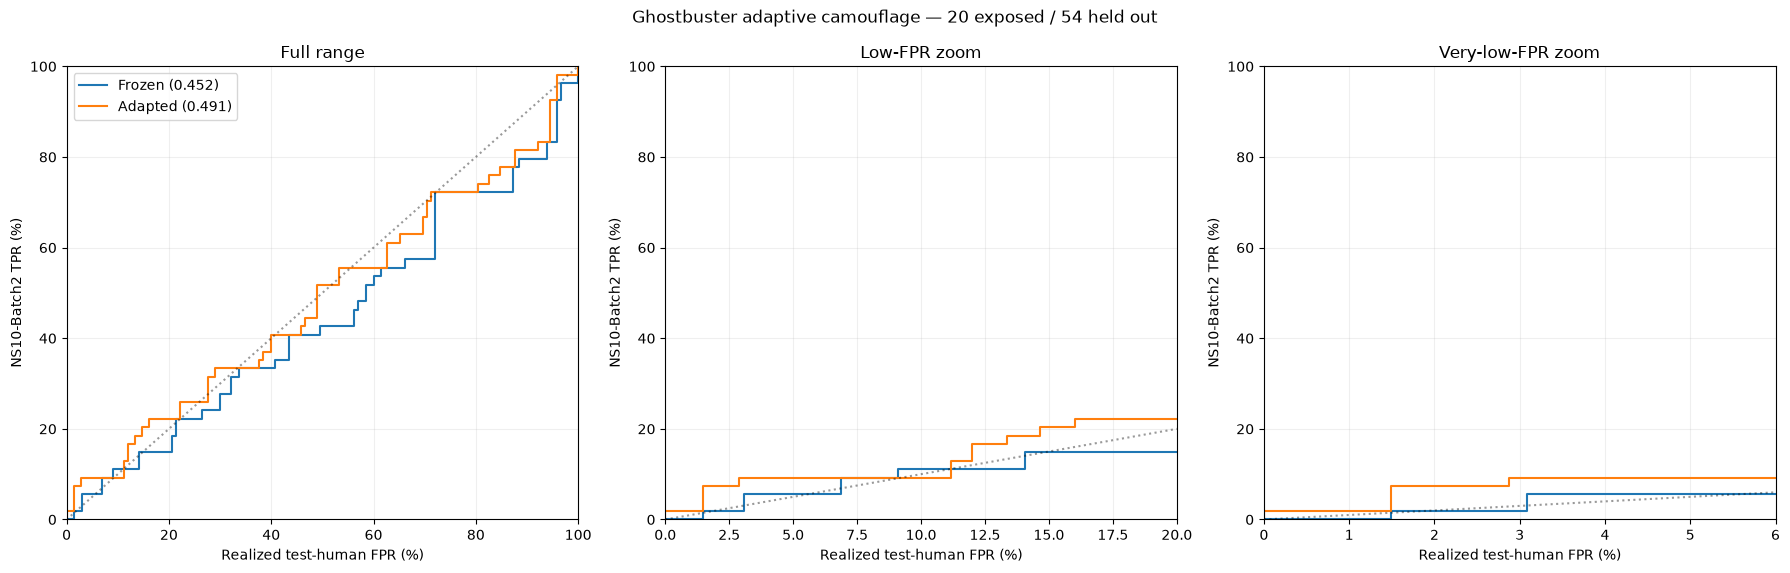


GHOSTBUSTER ADAPTATION 30/44


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  w

,detector,exposure,heldout,model,AUROC,mean_AI_score,median_AI_score
0,Ghostbuster,30,44,Frozen,0.437597,0.200493,0.127288
1,Ghostbuster,30,44,Adapted,0.520283,0.285956,0.205903


,detector,exposure,heldout,comparison,delta_AUROC,ci_low,ci_high
0,Ghostbuster,30,44,Adapted_minus_Frozen,0.082686,0.063956,0.101781


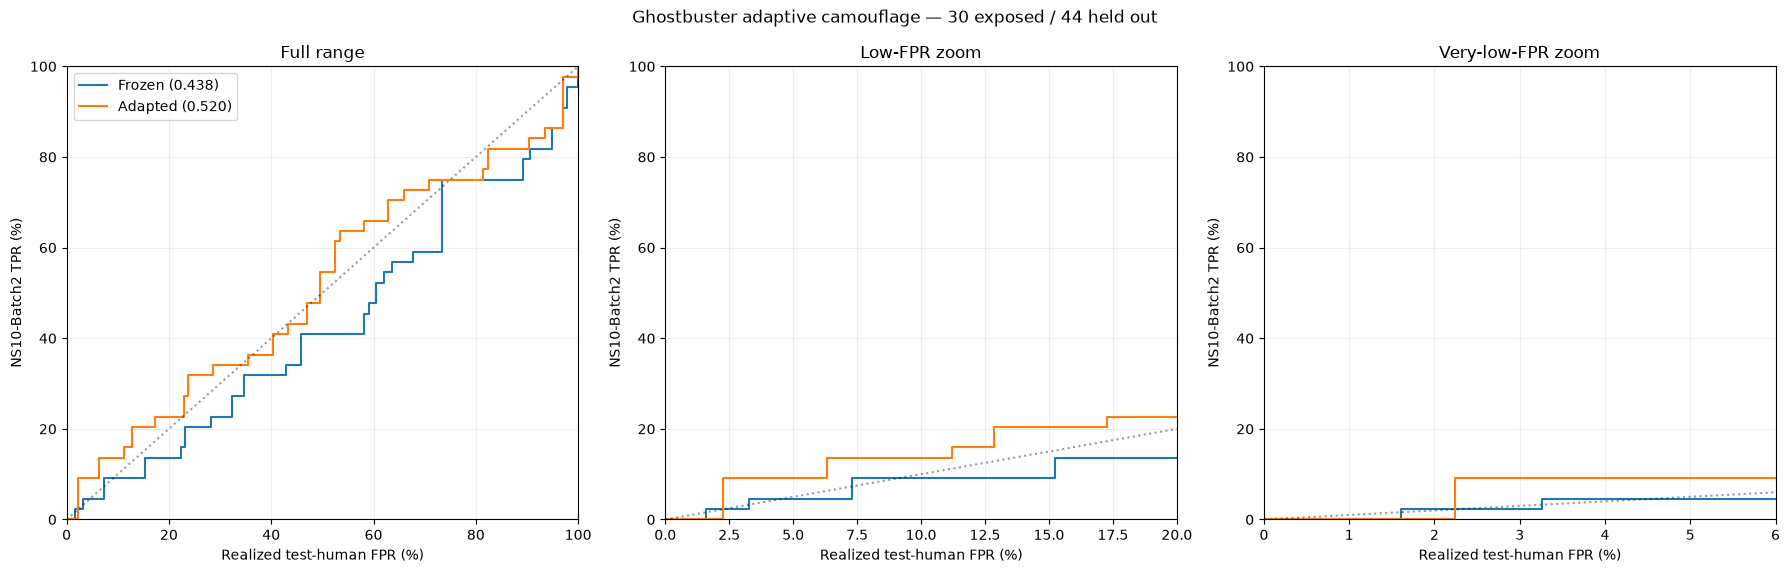


GHOSTBUSTER ADAPTATION 40/34


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  w

,detector,exposure,heldout,model,AUROC,mean_AI_score,median_AI_score
0,Ghostbuster,40,34,Frozen,0.457487,0.209222,0.128140
1,Ghostbuster,40,34,Adapted,0.581859,0.331959,0.253887


,detector,exposure,heldout,comparison,delta_AUROC,ci_low,ci_high
0,Ghostbuster,40,34,Adapted_minus_Frozen,0.124373,0.097221,0.152388


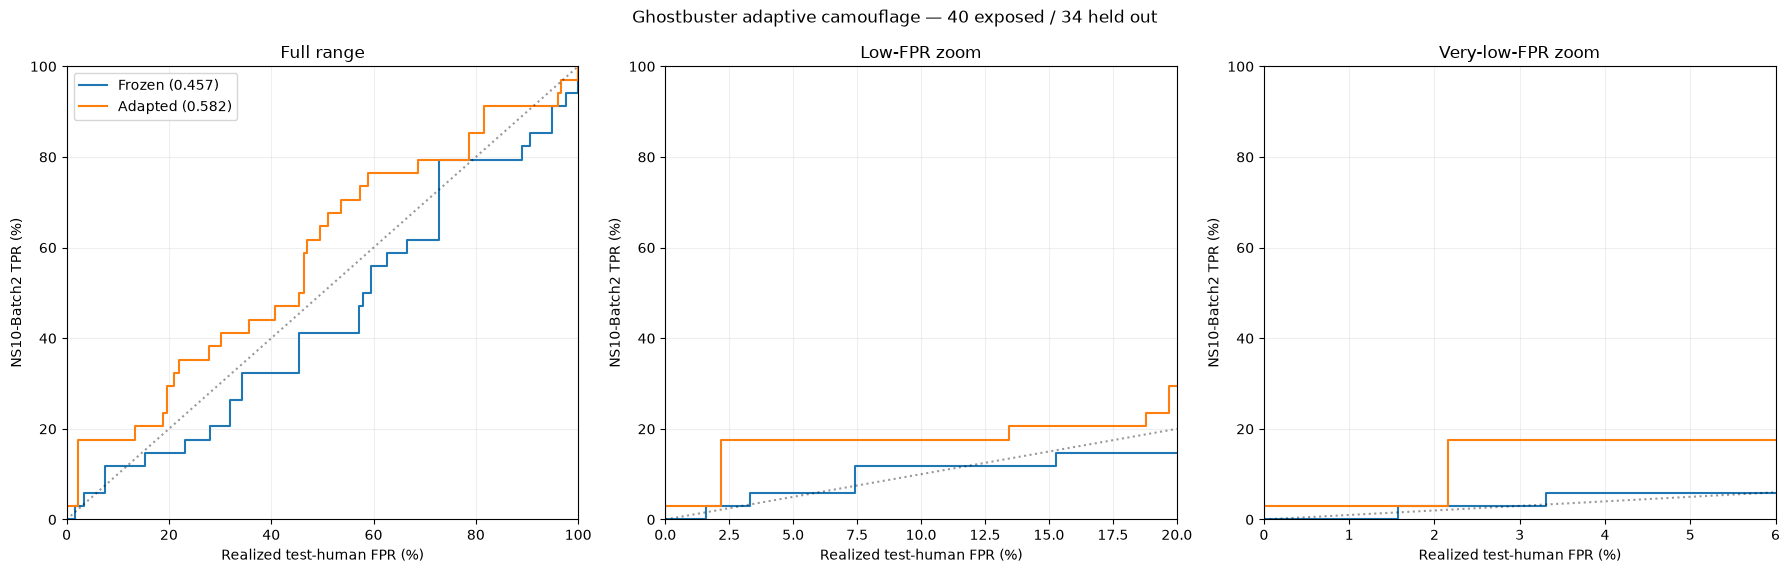

In [25]:
# ============================================================
# 20. Ghostbuster adaptation — 20/54, 30/44, 40/34
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV

# Ensure all new NS10 features have been cached by the frozen evaluation.
_ = GB.score(ns.text.tolist(), purpose="C09_batch2_adaptation_features")

train_meta = raid.loc[raid.split.eq("train")].copy()

X_raid_raw = GB.rf.loc[
    ["raid::" + x for x in train_meta.source_id.astype(str)],
    GB.names,
].to_numpy(float)

X_raid = GB.normalize(
    X_raid_raw,
    mu=GB.mu,
    sigma=GB.sigma,
)

y_raid = train_meta.label.astype(int).to_numpy()


def gb_ns_features(frame):
    values = []

    for r in frame.itertuples(index=False):
        z = read_json(GB.path(r.text, "features"))
        assert z is not None, r.case_id
        values.append(z["features"])

    return GB.normalize(
        np.asarray(values, float),
        mu=GB.mu,
        sigma=GB.sigma,
    )


gb_human = raid.loc[
    raid.label.eq(0)
    & raid.split.isin(["validation", "test"])
].copy()

X_human_raw = GB.rf.loc[
    ["raid::" + x for x in gb_human.source_id.astype(str)],
    GB.names,
].to_numpy(float)

X_human = GB.normalize(
    X_human_raw,
    mu=GB.mu,
    sigma=GB.sigma,
)

frozen_all = EVAL["Ghostbuster"]

for n in EXPOSURES:
    print("\n", "=" * 90)
    print(f"GHOSTBUSTER ADAPTATION {n}/{74-n}")
    print("=" * 90)

    sp = ADAPT_SPLITS[n]

    exposed = ns.loc[
        ns.case_id.astype(str).isin(sp["adaptation_cases"])
    ].copy()

    held = ns.loc[
        ns.case_id.astype(str).isin(sp["test_cases"])
    ].sort_values("case_id").copy()

    X_exp = gb_ns_features(exposed)
    X_held = gb_ns_features(held)

    X_fit = np.vstack([X_raid, X_exp])
    y_fit = np.r_[y_raid, np.ones(len(exposed), dtype=int)]

    base = LogisticRegression(
        C=1.0,
        penalty="l2",
        max_iter=2000,
        random_state=ADAPT_SEED,
    )

    adapted = CalibratedClassifierCV(
        base,
        cv=5,
        method="sigmoid",
    )

    adapted.fit(X_fit, y_fit)

    adapted_attack = adapted.predict_proba(X_held)[:, 1]

    ah = gb_human.copy()
    ah["AI_score"] = adapted.predict_proba(X_human)[:, 1]

    frozen_attack = (
        frozen_all.loc[
            frozen_all.arm.eq("NS10-Batch2")
        ]
        .set_index("case_id")
        .loc[held.case_id, "AI_score"]
        .to_numpy()
    )

    frozen_h = frozen_all.loc[
        frozen_all.arm.eq("Human")
    ].copy()

    adaptation_report(
        "Ghostbuster",
        n,
        held,
        frozen_attack,
        adapted_attack,
        frozen_h,
        ah,
    )


GLTR ADAPTATION 20/54


,detector,exposure,heldout,model,AUROC,mean_AI_score,median_AI_score
0,GLTR,20,54,Frozen,0.517751,-0.811302,-0.630804
1,GLTR,20,54,Adapted,0.519004,-0.754721,-0.587514


,detector,exposure,heldout,comparison,delta_AUROC,ci_low,ci_high
0,GLTR,20,54,Adapted_minus_Frozen,0.001253,-0.000431,0.003103


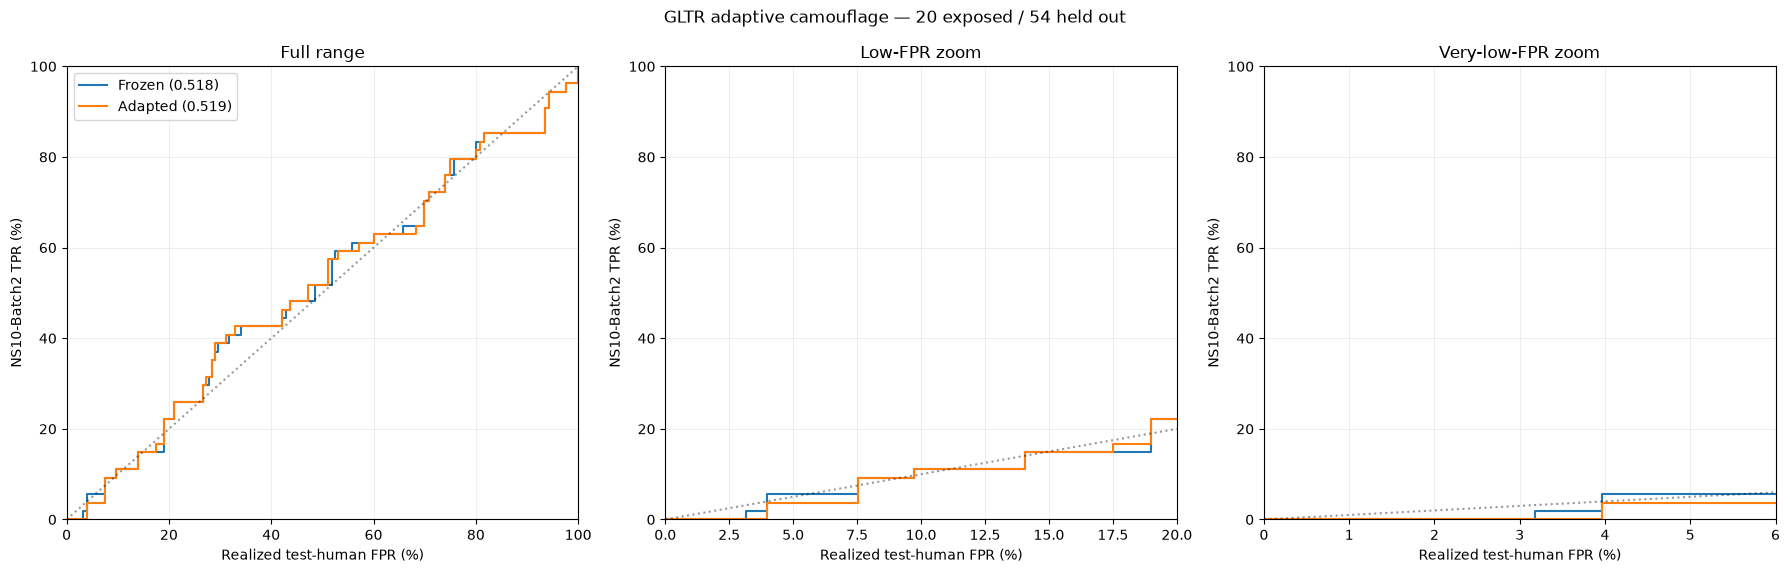


GLTR ADAPTATION 30/44


,detector,exposure,heldout,model,AUROC,mean_AI_score,median_AI_score
0,GLTR,30,44,Frozen,0.519806,-0.780270,-0.630804
1,GLTR,30,44,Adapted,0.520728,-0.679825,-0.557446


,detector,exposure,heldout,comparison,delta_AUROC,ci_low,ci_high
0,GLTR,30,44,Adapted_minus_Frozen,0.000921,-0.001681,0.003726


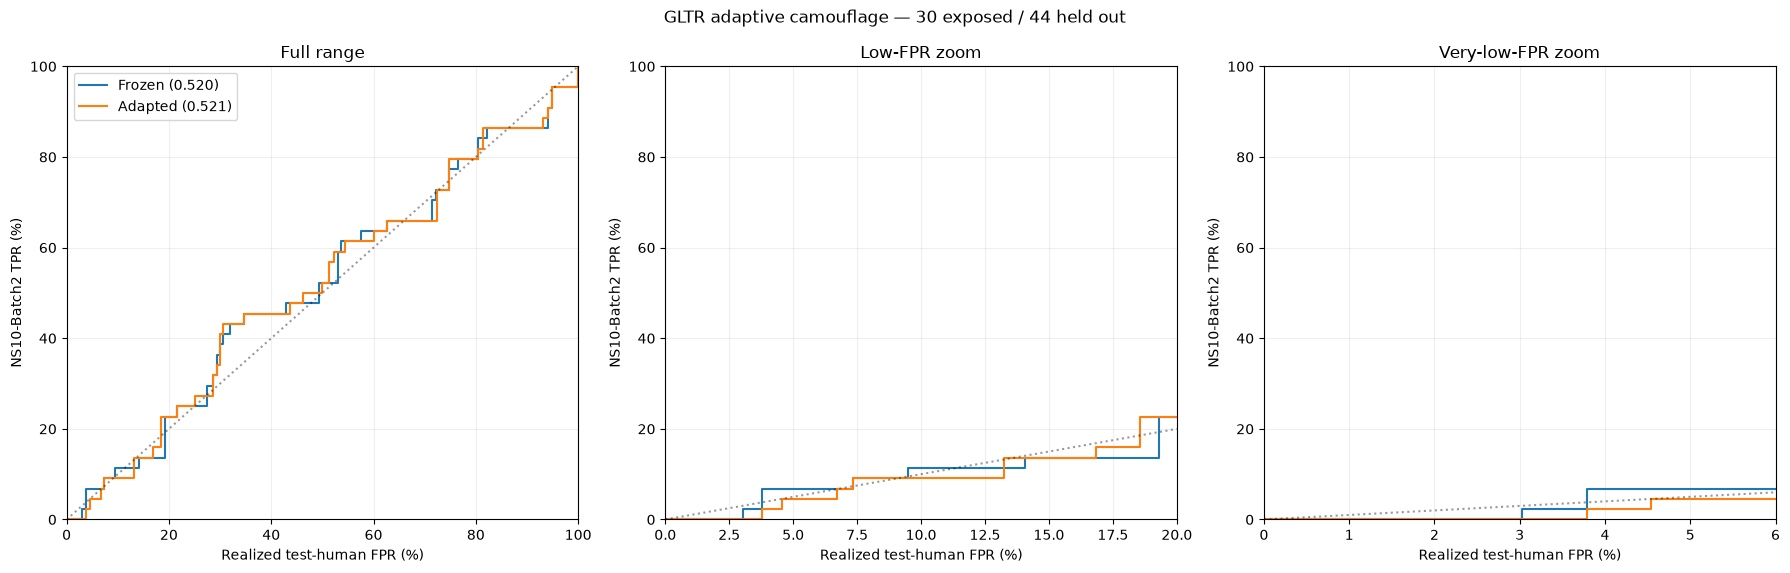


GLTR ADAPTATION 40/34


,detector,exposure,heldout,model,AUROC,mean_AI_score,median_AI_score
0,GLTR,40,34,Frozen,0.53328,-0.691854,-0.184066
1,GLTR,40,34,Adapted,0.53490,-0.556877,-0.112125


,detector,exposure,heldout,comparison,delta_AUROC,ci_low,ci_high
0,GLTR,40,34,Adapted_minus_Frozen,0.00162,-0.002786,0.005864


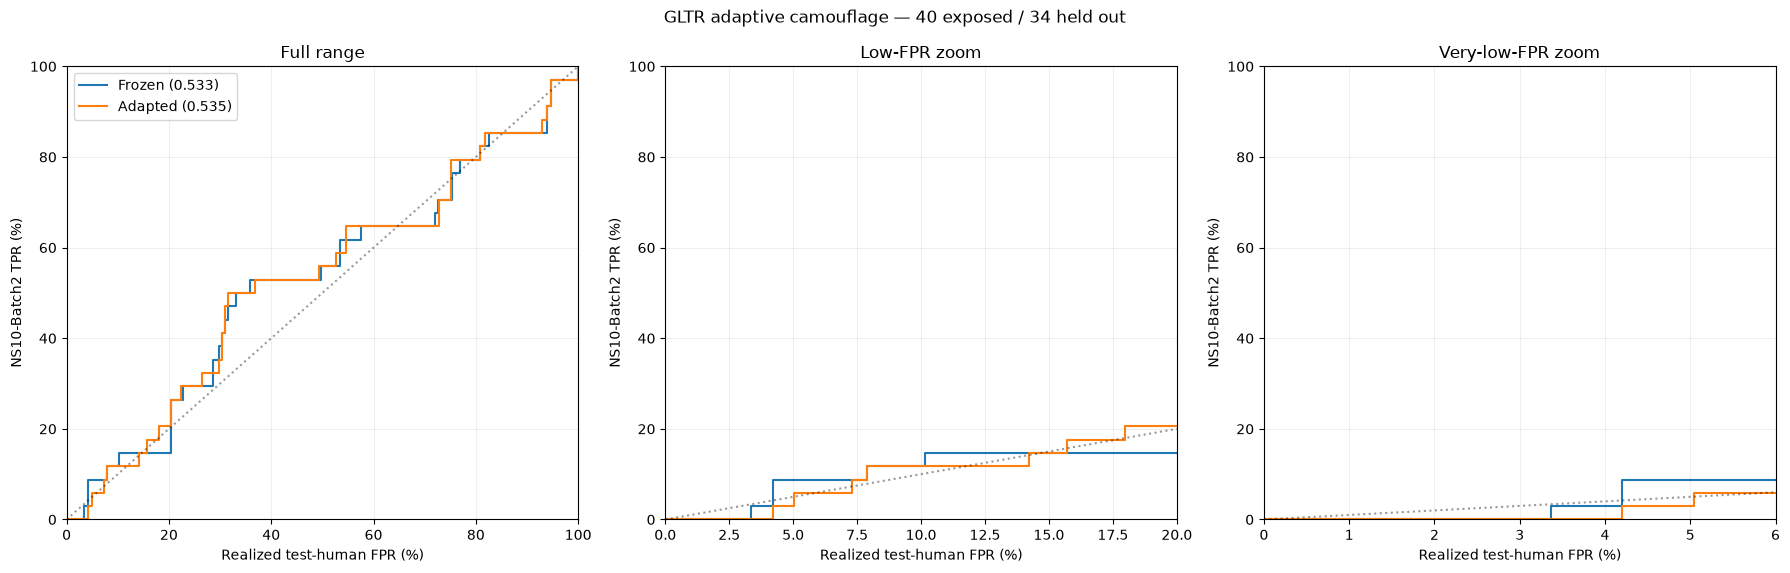

In [26]:
# ============================================================
# 21. GLTR adaptation — 20/54, 30/44, 40/34
# ============================================================

from sklearn.linear_model import LogisticRegression

GLTR_FEATURES = ["rank_1_10", "rank_11_100", "rank_101_1000", "rank_gt_1000"]


# Current Batch-2 scoring cache contains the 74 new feature vectors.
_gltr_cache = {}

for p in (OUT / "evaluation" / "GLTR").glob("*/*.json"):
    z = read_json(p)
    if z and all(k in z for k in GLTR_FEATURES):
        _gltr_cache[z["text_sha"]] = z


def gltr_features(frame):
    rows = []

    for r in frame.itertuples(index=False):
        h = sha(r.text)

        z = _gltr_cache.get(h)

        if z is None:
            z = g_feature(r.text)

        assert z is not None, h

        rows.append([float(z[k]) for k in GLTR_FEATURES])

    return np.asarray(rows)


# Original RAID training features already exist from C07c.
raid_train = raid.loc[raid.split.eq("train")].copy()

Xtr = gltr_features(raid_train)
ytr = raid_train.label.astype(int).to_numpy()

# Preserve the original frozen scaler contract.
scaler = StandardScaler().fit(Xtr)

gltr_human = raid.loc[
    raid.label.eq(0)
    & raid.split.isin(["validation", "test"])
].copy()

Xhuman = gltr_features(gltr_human)

frozen_all = EVAL["GLTR"]

for n in EXPOSURES:
    print("\n", "=" * 90)
    print(f"GLTR ADAPTATION {n}/{74-n}")
    print("=" * 90)

    sp = ADAPT_SPLITS[n]

    exposed = ns.loc[
        ns.case_id.astype(str).isin(sp["adaptation_cases"])
    ].copy()

    held = ns.loc[
        ns.case_id.astype(str).isin(sp["test_cases"])
    ].sort_values("case_id").copy()

    Xexp = gltr_features(exposed)
    Xheld = gltr_features(held)

    Xfit = np.vstack([Xtr, Xexp])
    yfit = np.r_[ytr, np.ones(len(exposed), dtype=int)]

    head = LogisticRegression(
        C=1.0,
        class_weight="balanced",
        solver="lbfgs",
        max_iter=5000,
        random_state=ADAPT_SEED,
    )

    head.fit(scaler.transform(Xfit), yfit)

    adapted_attack = head.decision_function(
        scaler.transform(Xheld)
    )

    ah = gltr_human.copy()
    ah["AI_score"] = head.decision_function(
        scaler.transform(Xhuman)
    )

    frozen_attack = (
        frozen_all.loc[frozen_all.arm.eq("NS10-Batch2")]
        .set_index("case_id")
        .loc[held.case_id, "AI_score"]
        .to_numpy()
    )

    frozen_h = frozen_all.loc[
        frozen_all.arm.eq("Human")
    ].copy()

    adaptation_report(
        "GLTR",
        n,
        held,
        frozen_attack,
        adapted_attack,
        frozen_h,
        ah,
    )


BINOCULARS ADAPTATION 20/54


,detector,exposure,heldout,model,AUROC,mean_AI_score,median_AI_score
0,Binoculars,20,54,Frozen,0.693556,-0.506332,-0.492227
1,Binoculars,20,54,Adapted,0.697962,-0.444527,-0.443494


,detector,exposure,heldout,comparison,delta_AUROC,ci_low,ci_high
0,Binoculars,20,54,Adapted_minus_Frozen,0.004407,0.002251,0.006758


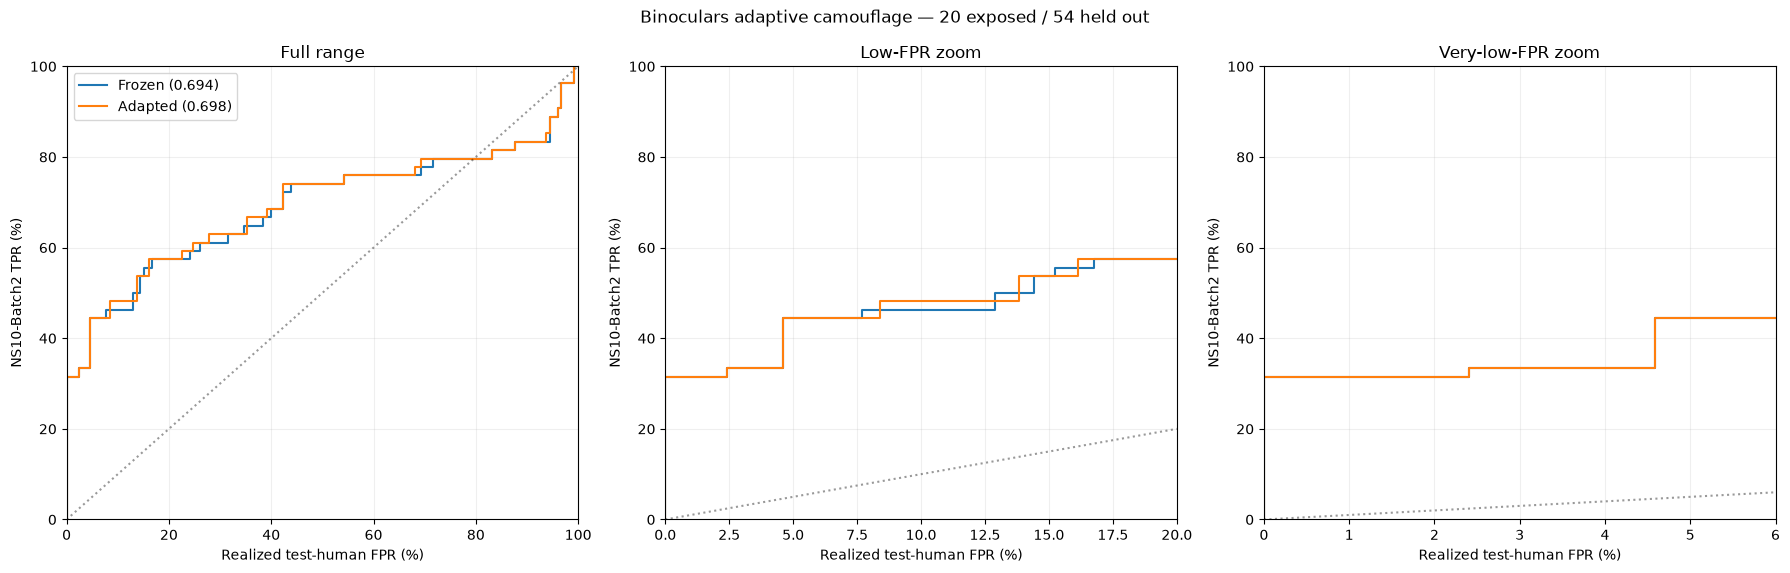


BINOCULARS ADAPTATION 30/44


,detector,exposure,heldout,model,AUROC,mean_AI_score,median_AI_score
0,Binoculars,30,44,Frozen,0.672009,-0.651856,-0.668826
1,Binoculars,30,44,Adapted,0.680761,-0.557434,-0.605683


,detector,exposure,heldout,comparison,delta_AUROC,ci_low,ci_high
0,Binoculars,30,44,Adapted_minus_Frozen,0.008751,0.004897,0.01302


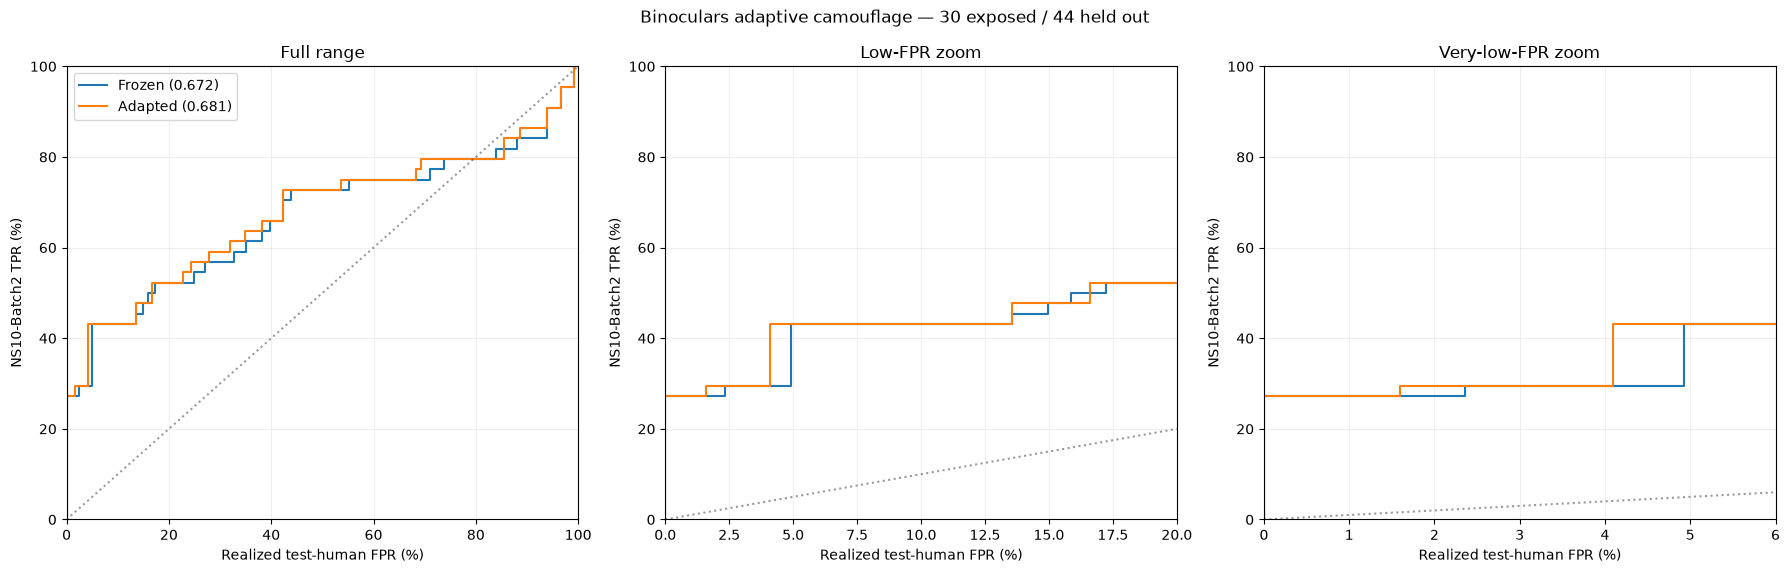


BINOCULARS ADAPTATION 40/34


,detector,exposure,heldout,model,AUROC,mean_AI_score,median_AI_score
0,Binoculars,40,34,Frozen,0.661294,-0.627349,-0.668826
1,Binoculars,40,34,Adapted,0.673970,-0.499182,-0.578753


,detector,exposure,heldout,comparison,delta_AUROC,ci_low,ci_high
0,Binoculars,40,34,Adapted_minus_Frozen,0.012675,0.005888,0.02028


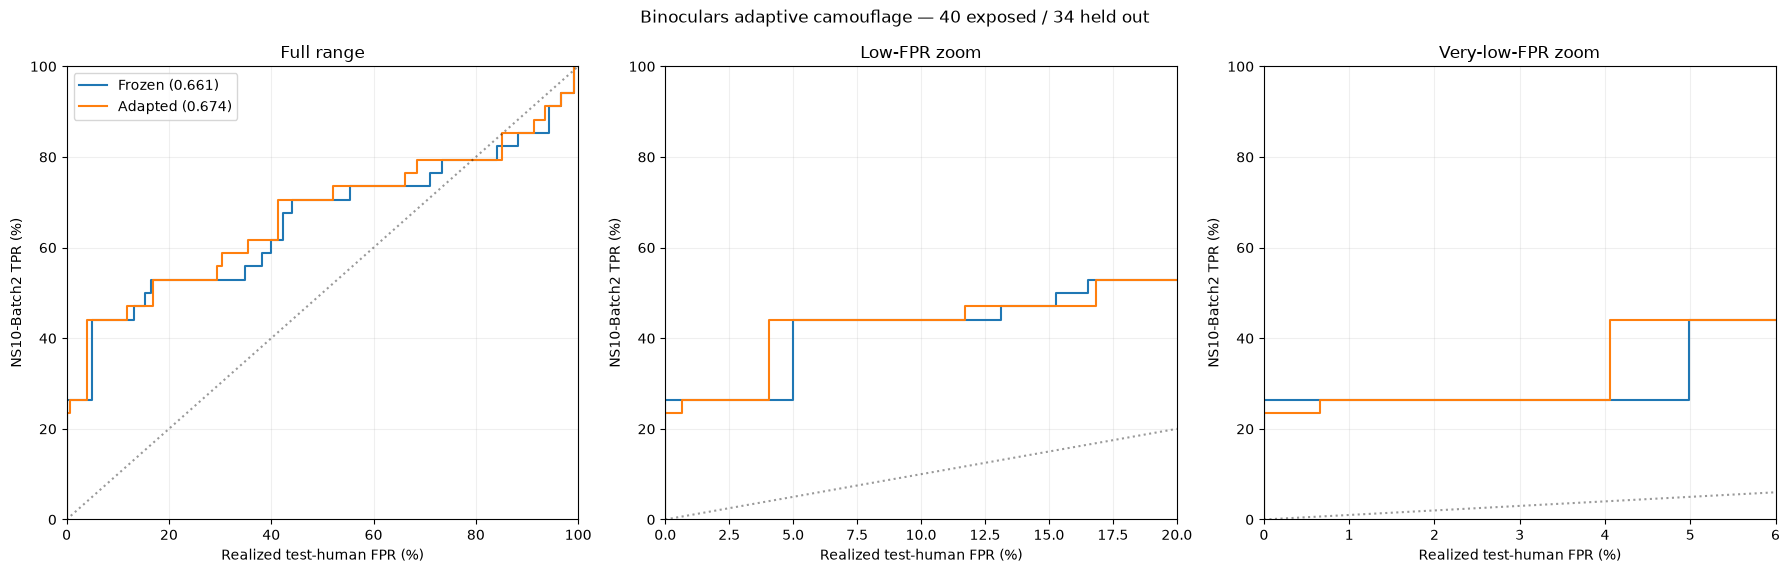

In [27]:
# ============================================================
# 22. Binoculars adaptive readout — 20/54, 30/44, 40/34
# ============================================================

BINO_FEATURES = ["mean_nll", "cross_entropy"]

# Gather already-computed Batch-2 Binoculars records.
_bino_cache = {}

for p in (OUT / "evaluation" / "Binoculars").glob("*/*.json"):
    z = read_json(p)
    if z and all(k in z for k in BINO_FEATURES):
        _bino_cache[z["text_sha"]] = z


def bino_feature_rows(frame):
    rows = []

    for r in frame.itertuples(index=False):
        h = sha(r.text)

        z = _bino_cache.get(h)

        if z is None and "bino_prior" in globals():
            z = bino_prior(
                type("R", (), {"text_sha": h})()
            )

        assert z is not None, f"Missing Binoculars features: {h}"

        rows.append([
            float(z["mean_nll"]),
            float(z["cross_entropy"]),
        ])

    return np.asarray(rows)


raid_train = raid.loc[raid.split.eq("train")].copy()
Xtr = bino_feature_rows(raid_train)
ytr = raid_train.label.astype(int).to_numpy()

scaler = StandardScaler().fit(Xtr)

bino_human = raid.loc[
    raid.label.eq(0)
    & raid.split.isin(["validation", "test"])
].copy()

Xhuman = bino_feature_rows(bino_human)

frozen_all = EVAL["Binoculars"]

for n in EXPOSURES:
    print("\n", "=" * 90)
    print(f"BINOCULARS ADAPTATION {n}/{74-n}")
    print("=" * 90)

    sp = ADAPT_SPLITS[n]

    exposed = ns.loc[
        ns.case_id.astype(str).isin(sp["adaptation_cases"])
    ].copy()

    held = ns.loc[
        ns.case_id.astype(str).isin(sp["test_cases"])
    ].sort_values("case_id").copy()

    Xexp = bino_feature_rows(exposed)
    Xheld = bino_feature_rows(held)

    Xfit = np.vstack([Xtr, Xexp])
    yfit = np.r_[ytr, np.ones(len(exposed), dtype=int)]

    head = LogisticRegression(
        C=1.0,
        class_weight="balanced",
        solver="lbfgs",
        max_iter=5000,
        random_state=ADAPT_SEED,
    )

    head.fit(scaler.transform(Xfit), yfit)

    adapted_attack = head.decision_function(
        scaler.transform(Xheld)
    )

    ah = bino_human.copy()
    ah["AI_score"] = head.decision_function(
        scaler.transform(Xhuman)
    )

    # The comparison baseline here is the RAID-only Binoculars
    # readout, not the raw -ratio. Fit it once using RAID train.
    raid_head = LogisticRegression(
        C=1.0,
        class_weight="balanced",
        solver="lbfgs",
        max_iter=5000,
        random_state=ADAPT_SEED,
    )
    raid_head.fit(scaler.transform(Xtr), ytr)

    frozen_attack = raid_head.decision_function(
        scaler.transform(Xheld)
    )

    fh = bino_human.copy()
    fh["AI_score"] = raid_head.decision_function(
        scaler.transform(Xhuman)
    )

    adaptation_report(
        "Binoculars",
        n,
        held,
        frozen_attack,
        adapted_attack,
        fh,
        ah,
    )


ROBERTA ADAPTATION 20/54


Step,Training Loss,Validation Loss
25,0.069800,0.160274
50,0.130700,0.174623
75,0.158300,0.169099
100,0.125500,0.170848
125,0.081700,0.144482
150,0.025800,0.171038
175,0.065600,0.336243
200,0.027600,0.361213
225,0.084200,0.278191


RoBERTa humans: 100%|██████████████████████████████████████████████████| 273/273 [00:02<00:00, 121.59it/s]


,detector,exposure,heldout,model,AUROC,mean_AI_score,median_AI_score
0,RoBERTa,20,54,Frozen,0.739896,0.146274,0.023510
1,RoBERTa,20,54,Adapted,0.906894,0.745277,0.996461


,detector,exposure,heldout,comparison,delta_AUROC,ci_low,ci_high
0,RoBERTa,20,54,Adapted_minus_Frozen,0.166998,0.117351,0.22384


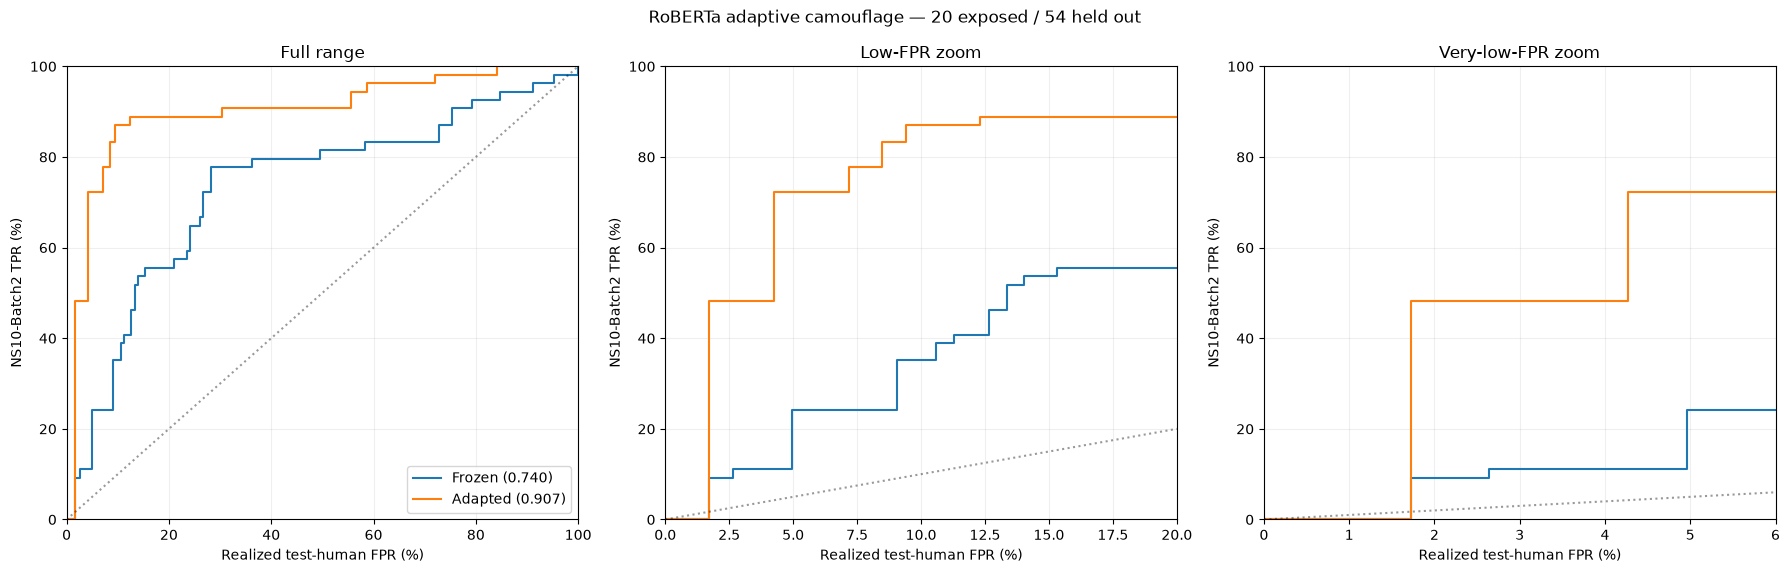


ROBERTA ADAPTATION 30/44


Step,Training Loss,Validation Loss
25,0.130700,0.141255
50,0.194400,0.210990
75,0.123900,0.217788
100,0.135800,0.203852
125,0.105600,0.245058
150,0.087400,0.177491
175,0.124800,0.229744
200,0.126900,0.236299
225,0.006700,0.238902


RoBERTa humans: 100%|██████████████████████████████████████████████████| 273/273 [00:02<00:00, 114.38it/s]


,detector,exposure,heldout,model,AUROC,mean_AI_score,median_AI_score
0,RoBERTa,30,44,Frozen,0.742044,0.147262,0.020133
1,RoBERTa,30,44,Adapted,0.744376,0.282739,0.018355


,detector,exposure,heldout,comparison,delta_AUROC,ci_low,ci_high
0,RoBERTa,30,44,Adapted_minus_Frozen,0.002333,-0.024304,0.032117


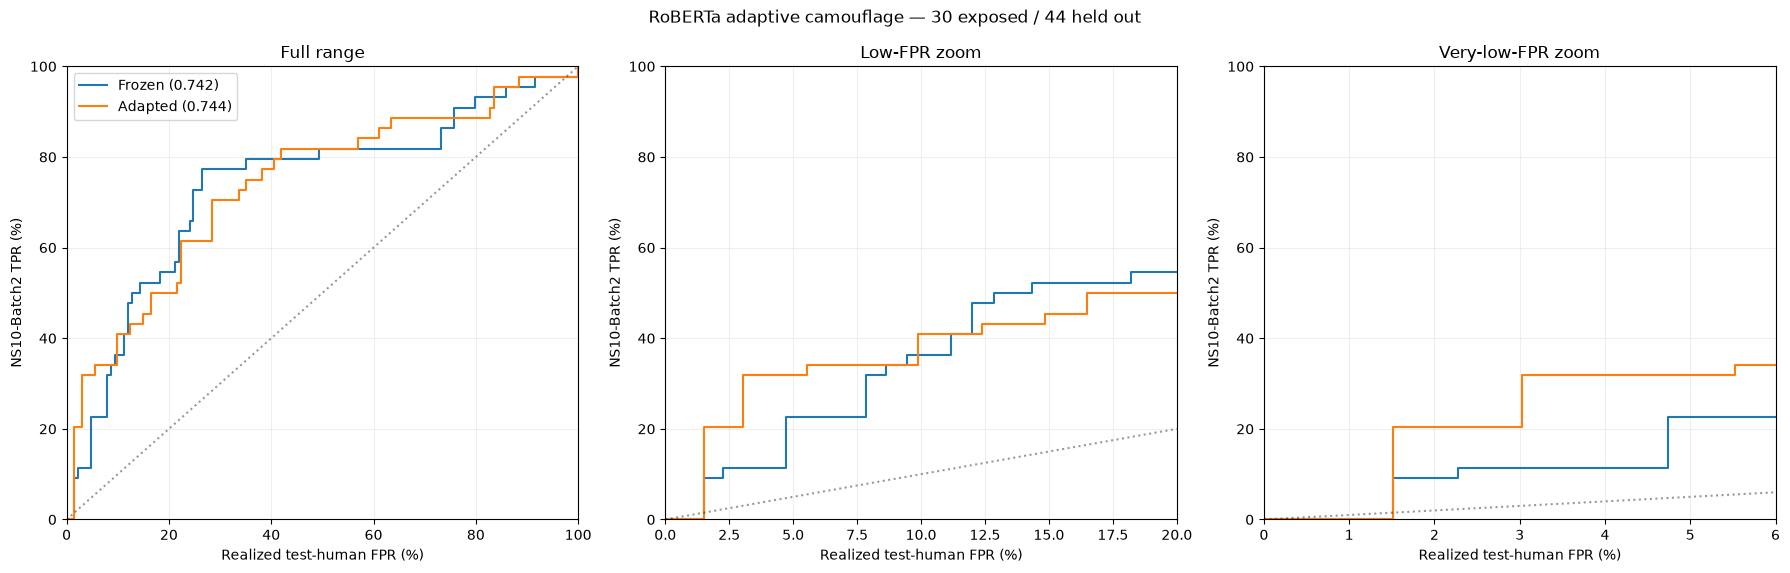


ROBERTA ADAPTATION 40/34


Step,Training Loss,Validation Loss
25,0.137900,0.156442
50,0.180600,0.237688
75,0.135200,0.155009
100,0.096400,0.488999
125,0.133300,0.180627
150,0.286300,0.341680
175,0.132200,0.212200
200,0.102700,0.276189
225,0.031700,0.297709


RoBERTa humans: 100%|██████████████████████████████████████████████████| 273/273 [00:02<00:00, 124.30it/s]


,detector,exposure,heldout,model,AUROC,mean_AI_score,median_AI_score
0,RoBERTa,40,34,Frozen,0.767038,0.153593,0.022309
1,RoBERTa,40,34,Adapted,0.940348,0.743844,0.979863


,detector,exposure,heldout,comparison,delta_AUROC,ci_low,ci_high
0,RoBERTa,40,34,Adapted_minus_Frozen,0.17331,0.098247,0.25771


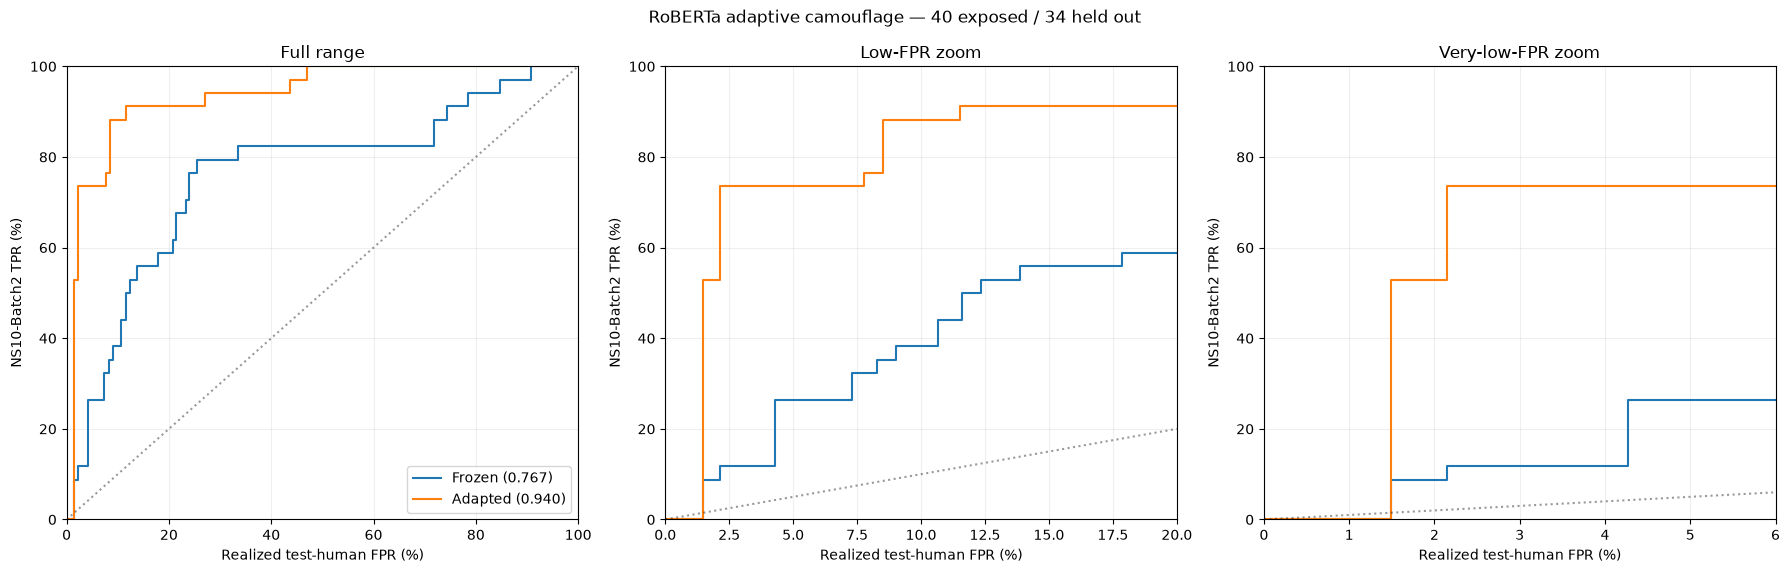

In [28]:
# ============================================================
# 23. RoBERTa full-model adaptation
#     20/54, 30/44, 40/34
# ============================================================

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

FROZEN_R = R / "C07b_RoBERTa_RAID_OG_NS10_v1/best_model"

rtok = AutoTokenizer.from_pretrained(FROZEN_R)
rtok.truncation_side = "right"

R_MAX = 512
R_EPOCHS = 3
R_LR = 1e-5


class RDataset(torch.utils.data.Dataset):
    def __init__(self, frame):
        self.enc = rtok(
            frame.text.astype(str).tolist(),
            truncation=True,
            max_length=R_MAX,
        )
        self.labels = frame.label.astype(int).tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return {
            **{k: v[i] for k, v in self.enc.items()},
            "labels": self.labels[i],
        }


rtrain = raid.loc[raid.split.eq("train")].copy()
rval = raid.loc[raid.split.eq("validation")].copy()

rhum = raid.loc[
    raid.label.eq(0)
    & raid.split.isin(["validation", "test"])
].copy()

frozen_all = EVAL["RoBERTa"]


def rscore(model, frame, desc):
    scores = []

    model.eval()

    for t in tqdm(frame.text, desc=desc):
        x = rtok(
            t,
            return_tensors="pt",
            truncation=True,
            max_length=R_MAX,
        ).to("cuda")

        with torch.inference_mode(), torch.autocast(
            "cuda", dtype=torch.bfloat16
        ):
            z = model(**x).logits.float()

        scores.append(float(z.softmax(-1)[0, 1].cpu()))

    return np.asarray(scores)


for n in EXPOSURES:
    release()

    print("\n", "=" * 90)
    print(f"ROBERTA ADAPTATION {n}/{74-n}")
    print("=" * 90)

    sp = ADAPT_SPLITS[n]

    exposed = ns.loc[
        ns.case_id.astype(str).isin(sp["adaptation_cases"])
    ].copy()

    exposed["label"] = 1

    held = ns.loc[
        ns.case_id.astype(str).isin(sp["test_cases"])
    ].sort_values("case_id").copy()

    fit = pd.concat(
        [
            rtrain[["text", "label"]],
            exposed[["text", "label"]],
        ],
        ignore_index=True,
    )

    ad = ADAPT_ROOT / "RoBERTa" / f"adapt{n}_{74-n}"
    ad.mkdir(parents=True, exist_ok=True)

    best = ad / "best_model"
    done = ad / "training_complete.json"

    if done.exists():
        model = AutoModelForSequenceClassification.from_pretrained(
            best,
            attn_implementation="eager",
        ).to("cuda")
    else:
        set_seed(ADAPT_SEED)

        model = AutoModelForSequenceClassification.from_pretrained(
            FROZEN_R,
            attn_implementation="eager",
        )

        for p in model.parameters():
            p.requires_grad_(True)

        args = TrainingArguments(
            output_dir=str(ad / "training"),
            num_train_epochs=R_EPOCHS,
            per_device_train_batch_size=1,
            per_device_eval_batch_size=2,
            gradient_accumulation_steps=16,
            learning_rate=R_LR,
            weight_decay=.01,
            warmup_ratio=.1,
            lr_scheduler_type="linear",
            optim="adamw_torch",
            max_grad_norm=1.,
            bf16=True,
            fp16=False,
            gradient_checkpointing=True,
            gradient_checkpointing_kwargs={"use_reentrant": False},
            eval_strategy="steps",
            eval_steps=25,
            save_strategy="steps",
            save_steps=25,
            save_total_limit=2,
            load_best_model_at_end=True,
            metric_for_best_model="eval_loss",
            greater_is_better=False,
            logging_steps=10,
            report_to=[],
            seed=ADAPT_SEED,
            data_seed=ADAPT_SEED,
            dataloader_num_workers=0,
            dataloader_pin_memory=False,
            eval_accumulation_steps=16,
            save_safetensors=True,
        )

        trainer = Trainer(
            model=model,
            args=args,
            train_dataset=RDataset(fit),
            eval_dataset=RDataset(rval),
            data_collator=DataCollatorWithPadding(
                rtok,
                pad_to_multiple_of=8,
            ),
            tokenizer=rtok,
        )

        trainer.train()

        trainer.save_model(best)
        rtok.save_pretrained(best)

        atomic_json(
            done,
            {
                "seed": ADAPT_SEED,
                "exposure": n,
                "heldout": 74 - n,
                "epochs": R_EPOCHS,
                "lr": R_LR,
            },
        )

        model = trainer.model
        del trainer

    adapted_attack = rscore(
        model,
        held,
        f"RoBERTa heldout {74-n}",
    )

    ah = rhum.copy()
    ah["AI_score"] = rscore(
        model,
        rhum,
        "RoBERTa humans",
    )

    frozen_attack = (
        frozen_all.loc[frozen_all.arm.eq("NS10-Batch2")]
        .set_index("case_id")
        .loc[held.case_id, "AI_score"]
        .to_numpy()
    )

    frozen_h = frozen_all.loc[
        frozen_all.arm.eq("Human")
    ].copy()

    adaptation_report(
        "RoBERTa",
        n,
        held,
        frozen_attack,
        adapted_attack,
        frozen_h,
        ah,
    )

    model.to("cpu")
    del model
    release()

Fetching 10 files: 100%|████████████████████████████████████████████████| 10/10 [00:00<00:00, 3492.34it/s]



WAVEDETECT ADAPTIVE CAMOUFLAGE 20/54


WaveDetect 20/54 epoch 1/3: 100%|███████████████| 162/162 [10:00<00:00,  3.71s/it, loss=0.217, lr=6.7e-06]


   epoch  training_loss  validation_loss
0      1       0.818333         0.485111
New best validation loss: 0.485110543860464


WaveDetect 20/54 epoch 2/3: 100%|███████████████| 162/162 [09:43<00:00,  3.60s/it, loss=0.185, lr=3.3e-06]


...

WaveDetect 20/54 epoch 3/3: 100%|████████████████████| 162/162 [09:40<00:00,  3.58s/it, loss=0.0959, lr=0]


   epoch  training_loss  validation_loss
2      3       0.344716         0.504652


WaveDetect adapted humans 20: 100%|█████████████████████████████████████| 273/273 [00:25<00:00, 10.57it/s]


,detector,exposure,heldout,model,AUROC,mean_AI_score,median_AI_score
0,WaveDetect,20,54,Frozen,0.513173,0.463309,0.379628
1,WaveDetect,20,54,Adapted,0.413523,0.535203,0.486454


,detector,exposure,heldout,comparison,delta_AUROC,ci_low,ci_high
0,WaveDetect,20,54,Adapted_minus_Frozen,-0.09965,-0.165267,-0.031467


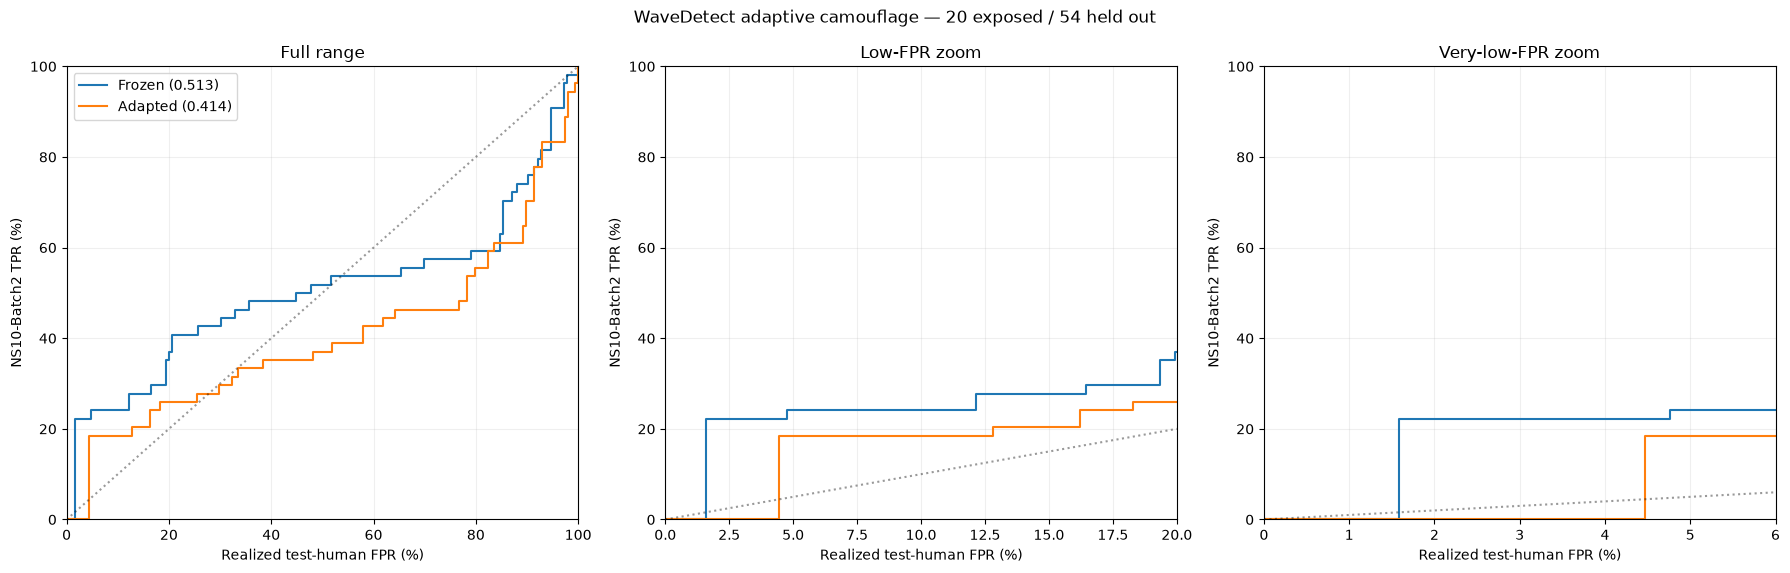

Finished WaveDetect 20/54

WAVEDETECT ADAPTIVE CAMOUFLAGE 30/44


WaveDetect 30/44 epoch 1/3: 100%|███████████████| 163/163 [09:46<00:00,  3.60s/it, loss=0.405, lr=6.7e-06]


   epoch  training_loss  validation_loss
0      1       0.737579         0.487877
New best validation loss: 0.4878766790579836


WaveDetect 30/44 epoch 2/3: 100%|███████████████| 163/163 [09:47<00:00,  3.60s/it, loss=0.168, lr=3.3e-06]


   epoch  training_loss  validation_loss
1      2       0.592196          0.57737


WaveDetect 30/44 epoch 3/3: 100%|█████████████████████| 163/163 [29:54<00:00, 11.01s/it, loss=0.117, lr=0]


   epoch  training_loss  validation_loss
2      3       0.428535           0.4714
New best validation loss: 0.471399502643722


WaveDetect adapted humans 30: 100%|█████████████████████████████████████| 273/273 [00:25<00:00, 10.60it/s]


,detector,exposure,heldout,model,AUROC,mean_AI_score,median_AI_score
0,WaveDetect,30,44,Frozen,0.508124,0.464872,0.379628
1,WaveDetect,30,44,Adapted,0.455724,0.503116,0.488165


,detector,exposure,heldout,comparison,delta_AUROC,ci_low,ci_high
0,WaveDetect,30,44,Adapted_minus_Frozen,-0.052399,-0.096459,-0.012655


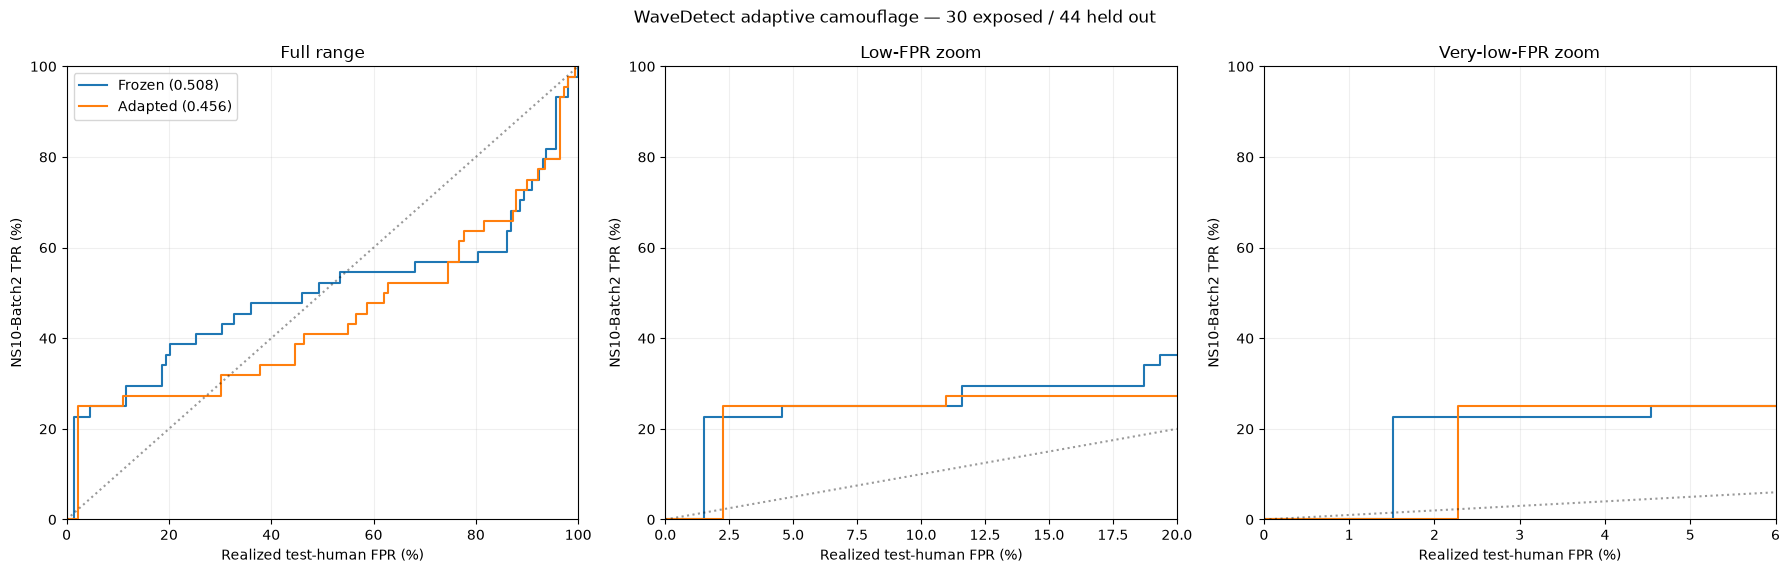

Finished WaveDetect 30/44

WAVEDETECT ADAPTIVE CAMOUFLAGE 40/34


WaveDetect 40/34 epoch 1/3: 100%|███████████████| 164/164 [09:58<00:00,  3.65s/it, loss=0.383, lr=6.7e-06]


   epoch  training_loss  validation_loss
0      1       0.776373         0.453198
New best validation loss: 0.4531975260550998


WaveDetect 40/34 epoch 2/3: 100%|███████████████| 164/164 [09:58<00:00,  3.65s/it, loss=0.271, lr=3.3e-06]


   epoch  training_loss  validation_loss
1      2       0.526657         0.561521


WaveDetect 40/34 epoch 3/3: 100%|█████████████████████| 164/164 [10:00<00:00,  3.66s/it, loss=0.175, lr=0]


   epoch  training_loss  validation_loss
2      3       0.411386         0.528733


WaveDetect adapted humans 40: 100%|█████████████████████████████████████| 273/273 [00:25<00:00, 10.54it/s]


,detector,exposure,heldout,model,AUROC,mean_AI_score,median_AI_score
0,WaveDetect,40,34,Frozen,0.485528,0.456312,0.330304
1,WaveDetect,40,34,Adapted,0.399211,0.493611,0.390482


,detector,exposure,heldout,comparison,delta_AUROC,ci_low,ci_high
0,WaveDetect,40,34,Adapted_minus_Frozen,-0.086317,-0.182624,0.006156


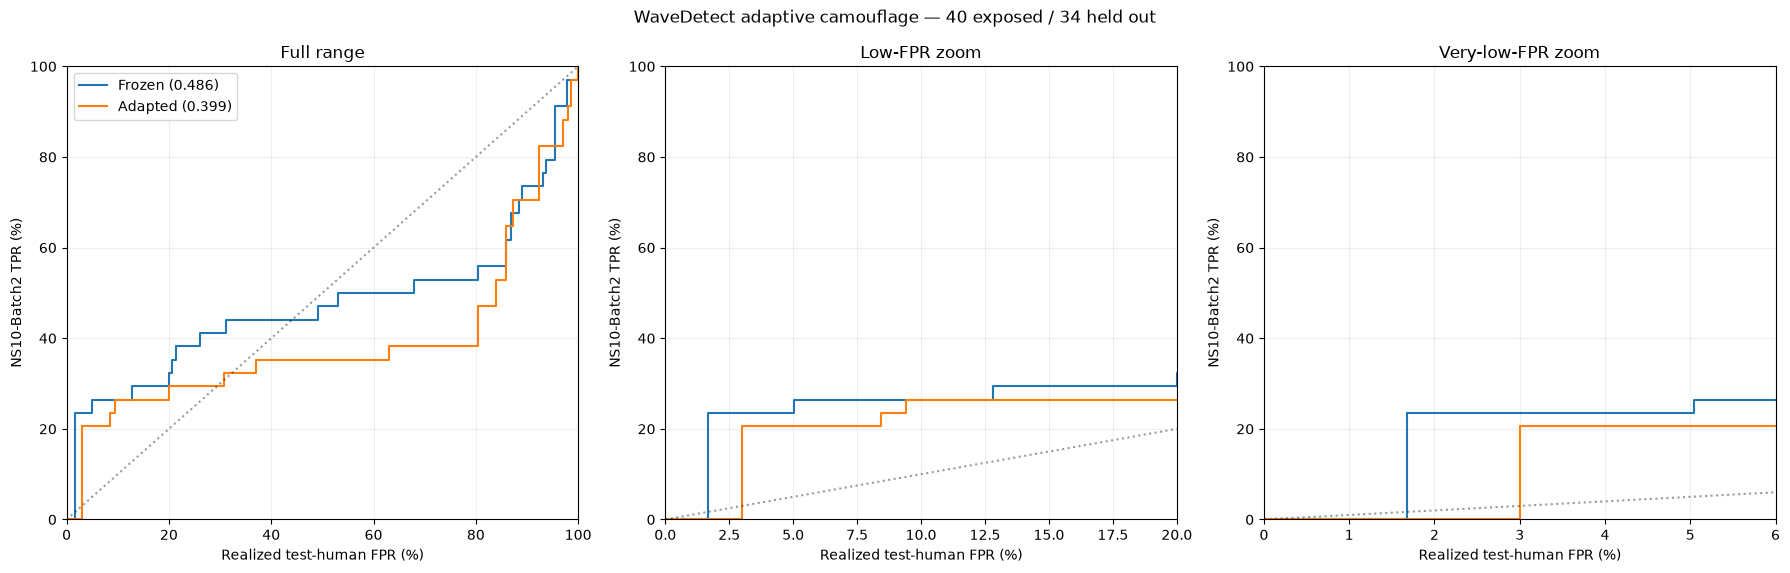

Finished WaveDetect 40/34


In [30]:
# ============================================================
# 24. WaveDetect full-model adaptive camouflage
#     20/54, 30/44, 40/34 — nested Batch-2 splits
#
# Exact C07 adaptation protocol:
#   frozen RAID-trained WaveDetect -> full stage-2 adaptation
#   RAID train + exposed NS10
#   3 epochs, lr=1e-5
#   original RAID validation selects checkpoint
# ============================================================

import os
import gc
import math
import json
import random
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from tqdm.auto import tqdm
from huggingface_hub import snapshot_download


# ------------------------------------------------------------
# Exact frozen WaveDetect checkpoint / base revision
# ------------------------------------------------------------

WAVE = R / "C07_WaveDetect_RAID_OG_NS10_v1"
W_CP = WAVE / "wavedetect_raid_best.pt"

assert W_CP.exists()

w_contract = read_json(WAVE / "contract.json")
w_revision = read_json(WAVE / "base_revision.json")["revision"]

w_contract_sha = sha(
    json.dumps(w_contract, sort_keys=True)
)

w_frozen_sha = file_sha(W_CP)

snapshot = Path(
    snapshot_download(
        "Qwen/Qwen2.5-0.5B",
        revision=w_revision,
    )
)


# If this kernel no longer contains the exact WaveDetect architecture,
# reload the definition from the accepted C08e evaluation notebook.
if "RaidWaveDetect" not in globals():
    exec(
        compile(
            c08e_cell("class WaveletTransform"),
            "<C08e exact WaveDetect architecture>",
            "exec",
        ),
        globals(),
    )


# ------------------------------------------------------------
# Fixed WaveDetect tokenization
# ------------------------------------------------------------

wtok = AutoTokenizer.from_pretrained(snapshot)

if wtok.pad_token_id is None:
    wtok.pad_token = wtok.eos_token

wtok.padding_side = "right"

W_MAX = 1024
W_BATCH = 8
W_MICROBATCH = 1
W_EPOCHS = 3
W_LR = 1e-5
W_SAVE_EVERY = 10

W_TOKEN_CACHE = ADAPT_ROOT / "WaveDetect" / "tokens"
W_TOKEN_CACHE.mkdir(parents=True, exist_ok=True)

W_TOKEN_CONTRACT = sha(
    json.dumps(
        {
            "base_revision": w_revision,
            "max_length": W_MAX,
            "padding": "fixed_1024",
        },
        sort_keys=True,
    )
)


def wave_save_torch(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    fd, tmp = tempfile.mkstemp(
        dir=path.parent,
        suffix=".tmp",
    )
    os.close(fd)

    try:
        torch.save(obj, tmp)

        with open(tmp, "rb") as f:
            os.fsync(f.fileno())

        os.replace(tmp, path)

    finally:
        if os.path.exists(tmp):
            os.unlink(tmp)


def wave_encode(text):
    text = str(text)
    text_hash = sha(text)

    p = (
        W_TOKEN_CACHE
        / (
            sha(W_TOKEN_CONTRACT + text_hash)
            + ".pt"
        )
    )

    if p.exists():
        z = torch.load(
            p,
            map_location="cpu",
            weights_only=True,
        )

        assert z["contract"] == W_TOKEN_CONTRACT
        assert z["text_sha"] == text_hash

        return z

    full = wtok(
        text,
        add_special_tokens=True,
    )["input_ids"]

    assert len(full) >= 2

    ids = full[:W_MAX]
    n = len(ids)

    z = {
        "contract": W_TOKEN_CONTRACT,
        "text_sha": text_hash,
        "input_ids": torch.tensor(
            ids
            + [wtok.pad_token_id] * (W_MAX - n),
            dtype=torch.long,
        ),
        "attention_mask": torch.tensor(
            [1] * n + [0] * (W_MAX - n),
            dtype=torch.long,
        ),
        "tokens_total": len(full),
        "tokens_used": n,
        "truncated": len(full) > W_MAX,
    }

    wave_save_torch(z, p)

    return z


def wave_batch_inputs(frame):
    recs = [
        wave_encode(t)
        for t in frame.text
    ]

    return {
        k: torch.stack(
            [r[k] for r in recs]
        ).to("cuda")
        for k in [
            "input_ids",
            "attention_mask",
        ]
    }


# Exact C07/WaveDetect class-weighted logical-batch loss.
def wave_loss_coeff(labels):
    labels = np.asarray(labels, dtype=int)

    n = len(labels)

    counts = np.bincount(
        labels,
        minlength=2,
    )

    return np.asarray(
        [
            n / (
                2 * counts[int(y)] ** 2
            )
            for y in labels
        ],
        dtype=np.float32,
    )


# ------------------------------------------------------------
# RNG/checkpoint helpers
# ------------------------------------------------------------

def wave_seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def wave_rng_state():
    return {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "cpu": torch.get_rng_state(),
        "cuda": torch.cuda.get_rng_state_all(),
    }


def wave_restore_rng(state):
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["cpu"])
    torch.cuda.set_rng_state_all(
        state["cuda"]
    )


def wave_cpu_state(model):
    return {
        k: v.detach().cpu().clone()
        for k, v in model.state_dict().items()
    }


def wave_freeze(path, obj):
    path = Path(path)

    if path.exists():
        assert read_json(path) == obj, (
            f"WaveDetect adaptation protocol changed: {path}"
        )
    else:
        atomic_json(path, obj)


# ------------------------------------------------------------
# Original RAID train / validation
# ------------------------------------------------------------

wave_train = (
    raid.loc[raid.split.eq("train")]
    .sort_values("source_id")
    .reset_index(drop=True)
)

wave_val = (
    raid.loc[raid.split.eq("validation")]
    .sort_values("source_id")
    .reset_index(drop=True)
)

assert set(wave_train.label) == {0, 1}
assert set(wave_val.label) == {0, 1}


# Adapted-human evaluation set.
wave_humans = raid.loc[
    raid.label.eq(0)
    & raid.split.isin(["validation", "test"])
].copy()

frozen_wave = EVAL["WaveDetect"]


# ------------------------------------------------------------
# Cached adapted scoring
# ------------------------------------------------------------

def score_wave_frame(
    model,
    frame,
    cache_dir,
    model_signature,
    desc,
):
    cache_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    values = []

    model.eval()

    for r in tqdm(
        frame.itertuples(index=False),
        total=len(frame),
        desc=desc,
    ):
        h = sha(r.text)

        p = (
            cache_dir
            / (
                sha(model_signature + h)
                + ".json"
            )
        )

        z = read_json(p)

        if z is not None:
            assert z["text_sha"] == h
            assert z["model_signature"] == model_signature

            values.append(
                float(z["AI_score"])
            )
            continue

        rec = wave_encode(r.text)

        x = {
            "input_ids":
                rec["input_ids"]
                .unsqueeze(0)
                .to("cuda"),

            "attention_mask":
                rec["attention_mask"]
                .unsqueeze(0)
                .to("cuda"),
        }

        with (
            torch.inference_mode(),
            torch.autocast(
                "cuda",
                dtype=torch.bfloat16,
            )
        ):
            logits = model(**x).float()

        score = float(
            logits.softmax(-1)[0, 1].cpu()
        )

        assert np.isfinite(score)

        atomic_json(
            p,
            {
                "model_signature":
                    model_signature,

                "text_sha":
                    h,

                "AI_score":
                    score,
            },
        )

        values.append(score)

    return np.asarray(values)


# ============================================================
# Run all three nested exposure sizes
# ============================================================

for exposure_n in EXPOSURES:

    print("\n" + "=" * 100)
    print(
        f"WAVEDETECT ADAPTIVE CAMOUFLAGE "
        f"{exposure_n}/{74-exposure_n}"
    )
    print("=" * 100)

    release()

    split = ADAPT_SPLITS[exposure_n]

    exposed = ns.loc[
        ns.case_id.astype(str).isin(
            split["adaptation_cases"]
        )
    ].copy()

    exposed["label"] = 1

    held = (
        ns.loc[
            ns.case_id.astype(str).isin(
                split["test_cases"]
            )
        ]
        .sort_values("case_id")
        .reset_index(drop=True)
    )

    assert len(exposed) == exposure_n
    assert len(held) == 74 - exposure_n

    assert set(exposed.case_id).isdisjoint(
        set(held.case_id)
    )

    # Original RAID train + exposed attack examples.
    fit = pd.concat(
        [
            wave_train[
                [
                    "source_id",
                    "domain",
                    "text",
                    "label",
                ]
            ].assign(
                origin="RAID_train"
            ),

            exposed[
                [
                    "source_id",
                    "domain",
                    "text",
                    "label",
                ]
            ].assign(
                origin="NS10_Batch2_exposure"
            ),
        ],
        ignore_index=True,
    )

    # Held-out attack text is never fitted.
    assert set(fit.text.map(sha)).isdisjoint(
        set(held.text.map(sha))
    )

    folder = (
        ADAPT_ROOT
        / "WaveDetect"
        / f"adapt{exposure_n}_{74-exposure_n}"
    )

    folder.mkdir(
        parents=True,
        exist_ok=True,
    )

    score_cache = folder / "scores"
    score_cache.mkdir(exist_ok=True)

    latest_path = folder / "latest.pt"
    best_path = folder / "adapted_best.pt"
    done_path = folder / "training_complete.json"


    # --------------------------------------------------------
    # Frozen protocol
    # --------------------------------------------------------

    protocol = {
        "version":
            "C09_WaveDetect_adaptive_batch2_v1",

        "frozen_checkpoint_sha":
            w_frozen_sha,

        "frozen_contract":
            w_contract,

        "base_revision":
            w_revision,

        "seed":
            ADAPT_SEED,

        "exposure":
            exposure_n,

        "heldout":
            74 - exposure_n,

        "adaptation_cases":
            split["adaptation_cases"],

        "test_cases":
            split["test_cases"],

        "training":
            "original RAID train + exposed NS10-Batch2",

        "stage":
            2,

        "all_parameters_trainable":
            True,

        "epochs":
            W_EPOCHS,

        "learning_rate":
            W_LR,

        "logical_batch":
            W_BATCH,

        "microbatch":
            W_MICROBATCH,

        "optimizer":
            "AdamW",

        "weight_decay":
            0.01,

        "scheduler":
            "linear",

        "selection":
            "minimum original RAID validation loss",

        "max_length":
            W_MAX,
    }

    wave_freeze(
        folder / "protocol.json",
        protocol,
    )

    protocol_signature = sha(
        json.dumps(
            protocol,
            sort_keys=True,
        )
    )


    # --------------------------------------------------------
    # Build model from exact frozen C07 checkpoint
    # --------------------------------------------------------

    wave_seed_all(ADAPT_SEED)

    net = RaidWaveDetect().to("cuda")

    frozen_obj = torch.load(
        W_CP,
        map_location="cpu",
        weights_only=False,
    )

    assert (
        frozen_obj["contract"]
        == w_contract_sha
    )

    net.load_state_dict(
        frozen_obj["model"]
    )

    del frozen_obj

    net.set_stage(2)

    for p in net.parameters():
        p.requires_grad_(True)


    # --------------------------------------------------------
    # Validation loss — untouched RAID validation
    # --------------------------------------------------------

    @torch.no_grad()
    def wave_validation_loss():
        net.eval()

        values = []

        for start in range(
            0,
            len(wave_val),
            W_BATCH,
        ):
            group = wave_val.iloc[
                start:start + W_BATCH
            ]

            coeff = wave_loss_coeff(
                group.label.to_numpy()
            )

            total = 0.0

            for j in range(
                0,
                len(group),
                W_MICROBATCH,
            ):
                part = group.iloc[
                    j:j + W_MICROBATCH
                ]

                with torch.autocast(
                    "cuda",
                    dtype=torch.bfloat16,
                ):
                    logits = net(
                        **wave_batch_inputs(part)
                    )

                labels = torch.tensor(
                    part.label.to_numpy(),
                    device="cuda",
                    dtype=torch.long,
                )

                ce = (
                    torch.nn.functional
                    .cross_entropy(
                        logits.float(),
                        labels,
                        reduction="none",
                    )
                )

                total += float(
                    (
                        ce
                        * torch.tensor(
                            coeff[
                                j:j + len(part)
                            ],
                            device="cuda",
                        )
                    ).sum()
                )

            values.append(total)

        return float(np.mean(values))


    # --------------------------------------------------------
    # Train / resume
    # --------------------------------------------------------

    if done_path.exists():

        done = read_json(done_path)

        assert (
            done["contract"]
            == protocol_signature
        )

        saved = torch.load(
            best_path,
            map_location="cpu",
            weights_only=False,
        )

        assert (
            saved["contract"]
            == protocol_signature
        )

        net.load_state_dict(
            saved["model"]
        )

        best_loss = float(
            saved["best_validation_loss"]
        )

        del saved

        print(
            "Loaded completed adapted checkpoint.",
            "best validation loss =",
            best_loss,
        )

    else:

        optimizer = torch.optim.AdamW(
            net.parameters(),
            lr=W_LR,
            eps=1e-8,
            weight_decay=.01,
            foreach=False,
        )

        steps_per_epoch = math.ceil(
            len(fit) / W_BATCH
        )

        total_steps = (
            steps_per_epoch
            * W_EPOCHS
        )

        scheduler = (
            torch.optim.lr_scheduler
            .LambdaLR(
                optimizer,
                lambda s:
                    max(
                        0.0,
                        1 - s / total_steps,
                    ),
            )
        )

        epoch0 = 0
        cursor0 = 0
        updates = 0
        best_loss = float("inf")
        history = []


        # ------------------------------------
        # Resume an interrupted adaptation
        # ------------------------------------

        if latest_path.exists():

            saved = torch.load(
                latest_path,
                map_location="cpu",
                weights_only=False,
            )

            assert (
                saved["contract"]
                == protocol_signature
            )

            net.load_state_dict(
                saved["model"]
            )

            optimizer.load_state_dict(
                saved["optimizer"]
            )

            scheduler.load_state_dict(
                saved["scheduler"]
            )

            epoch0 = saved["epoch"]
            cursor0 = saved["cursor"]
            updates = saved["updates"]
            best_loss = saved["best_loss"]
            history = saved["history"]

            wave_restore_rng(
                saved["rng"]
            )

            del saved

            print(
                f"Resuming epoch {epoch0+1}, "
                f"row offset {cursor0}"
            )


        def checkpoint_wave(
            epoch,
            cursor,
        ):
            wave_save_torch(
                {
                    "contract":
                        protocol_signature,

                    "model":
                        net.state_dict(),

                    "optimizer":
                        optimizer.state_dict(),

                    "scheduler":
                        scheduler.state_dict(),

                    "epoch":
                        epoch,

                    "cursor":
                        cursor,

                    "updates":
                        updates,

                    "best_loss":
                        best_loss,

                    "history":
                        history,

                    "rng":
                        wave_rng_state(),
                },
                latest_path,
            )


        # ------------------------------------
        # Adaptation epochs
        # ------------------------------------

        for epoch in range(
            epoch0,
            W_EPOCHS,
        ):

            order = (
                np.random.default_rng(
                    ADAPT_SEED + epoch
                )
                .permutation(len(fit))
            )

            begin = (
                cursor0
                if epoch == epoch0
                else 0
            )

            net.train()

            optimizer.zero_grad(
                set_to_none=True
            )

            running = 0.0
            seen = 0

            bar = tqdm(
                range(
                    begin,
                    len(fit),
                    W_BATCH,
                ),
                desc=(
                    f"WaveDetect "
                    f"{exposure_n}/{74-exposure_n} "
                    f"epoch {epoch+1}/{W_EPOCHS}"
                ),
            )

            for pos in bar:

                group = fit.iloc[
                    order[
                        pos:pos + W_BATCH
                    ]
                ]

                coeff = wave_loss_coeff(
                    group.label.to_numpy()
                )

                batch_loss = 0.0


                # Logical batch = 8,
                # GPU microbatch remains 1.
                for j in range(
                    0,
                    len(group),
                    W_MICROBATCH,
                ):

                    part = group.iloc[
                        j:j + W_MICROBATCH
                    ]

                    with torch.autocast(
                        "cuda",
                        dtype=torch.bfloat16,
                    ):
                        logits = net(
                            **wave_batch_inputs(part)
                        )

                    labels = torch.tensor(
                        part.label.to_numpy(),
                        device="cuda",
                        dtype=torch.long,
                    )

                    ce = (
                        torch.nn.functional
                        .cross_entropy(
                            logits.float(),
                            labels,
                            reduction="none",
                        )
                    )

                    loss = (
                        ce
                        * torch.tensor(
                            coeff[
                                j:j + len(part)
                            ],
                            device="cuda",
                        )
                    ).sum()

                    assert torch.isfinite(
                        loss
                    )

                    loss.backward()

                    batch_loss += float(
                        loss.detach()
                    )


                torch.nn.utils.clip_grad_norm_(
                    net.parameters(),
                    1.0,
                    error_if_nonfinite=True,
                )

                optimizer.step()
                scheduler.step()

                optimizer.zero_grad(
                    set_to_none=True
                )

                updates += 1
                running += batch_loss
                seen += 1


                if (
                    updates
                    % W_SAVE_EVERY
                    == 0
                ):
                    checkpoint_wave(
                        epoch,
                        min(
                            pos + W_BATCH,
                            len(fit),
                        ),
                    )


                bar.set_postfix(
                    loss=round(
                        batch_loss,
                        4,
                    ),
                    lr=(
                        f"{scheduler.get_last_lr()[0]:.2g}"
                    ),
                )


            # --------------------------------
            # Original RAID validation only
            # --------------------------------

            val_loss = (
                wave_validation_loss()
            )

            assert np.isfinite(
                val_loss
            )

            history.append(
                {
                    "epoch":
                        epoch + 1,

                    "training_loss":
                        running
                        / max(1, seen),

                    "validation_loss":
                        val_loss,
                }
            )


            print(
                pd.DataFrame(
                    history
                ).tail(1)
            )


            # --------------------------------
            # Save best selected checkpoint
            # --------------------------------

            if val_loss < best_loss:

                best_loss = val_loss

                wave_save_torch(
                    {
                        "contract":
                            protocol_signature,

                        "model":
                            wave_cpu_state(net),

                        "best_validation_loss":
                            best_loss,

                        "history":
                            history,
                    },
                    best_path,
                )

                print(
                    "New best validation loss:",
                    best_loss,
                )


            checkpoint_wave(
                epoch + 1,
                0,
            )

            cursor0 = 0


        assert best_path.exists()

        saved = torch.load(
            best_path,
            map_location="cpu",
            weights_only=False,
        )

        assert (
            saved["contract"]
            == protocol_signature
        )

        net.load_state_dict(
            saved["model"]
        )

        best_loss = float(
            saved["best_validation_loss"]
        )

        del saved


        atomic_json(
            done_path,
            {
                "contract":
                    protocol_signature,

                "best_validation_loss":
                    best_loss,

                "epochs":
                    W_EPOCHS,
            },
        )

        del optimizer
        del scheduler

        release()


    # --------------------------------------------------------
    # Evaluate adapted detector
    # --------------------------------------------------------

    net.eval()

    adapted_model_signature = sha(
        protocol_signature
        + str(best_loss)
    )

    adapted_attack = score_wave_frame(
        net,
        held,
        score_cache,
        adapted_model_signature,
        (
            f"WaveDetect adapted "
            f"heldout {74-exposure_n}"
        ),
    )

    adapted_h = (
        wave_humans[
            [
                "source_id",
                "split",
                "domain",
                "text",
            ]
        ]
        .copy()
    )

    adapted_h["AI_score"] = (
        score_wave_frame(
            net,
            adapted_h,
            score_cache,
            adapted_model_signature,
            (
                f"WaveDetect adapted humans "
                f"{exposure_n}"
            ),
        )
    )


    # --------------------------------------------------------
    # Frozen scores on EXACT SAME heldout subset
    # --------------------------------------------------------

    frozen_attack = (
        frozen_wave.loc[
            frozen_wave.arm.eq(
                "NS10-Batch2"
            )
        ]
        .set_index("case_id")
        .loc[
            held.case_id,
            "AI_score",
        ]
        .to_numpy()
    )

    frozen_h = frozen_wave.loc[
        frozen_wave.arm.eq("Human")
    ].copy()


    # Save raw heldout scores too.
    held_scores = held[
        [
            "case_id",
            "source_id",
            "domain",
        ]
    ].copy()

    held_scores["Frozen"] = (
        frozen_attack
    )

    held_scores["Adapted"] = (
        adapted_attack
    )

    csv(
        held_scores,
        folder / "heldout_scores.csv",
    )


    # --------------------------------------------------------
    # Same reporting protocol as all other detectors
    # --------------------------------------------------------

    adaptation_report(
        "WaveDetect",
        exposure_n,
        held,
        frozen_attack,
        adapted_attack,
        frozen_h,
        adapted_h,
    )


    # --------------------------------------------------------
    # Release before next exposure level
    # --------------------------------------------------------

    net.to("cpu")
    del net

    release()

    print(
        f"Finished WaveDetect "
        f"{exposure_n}/{74-exposure_n}"
    )

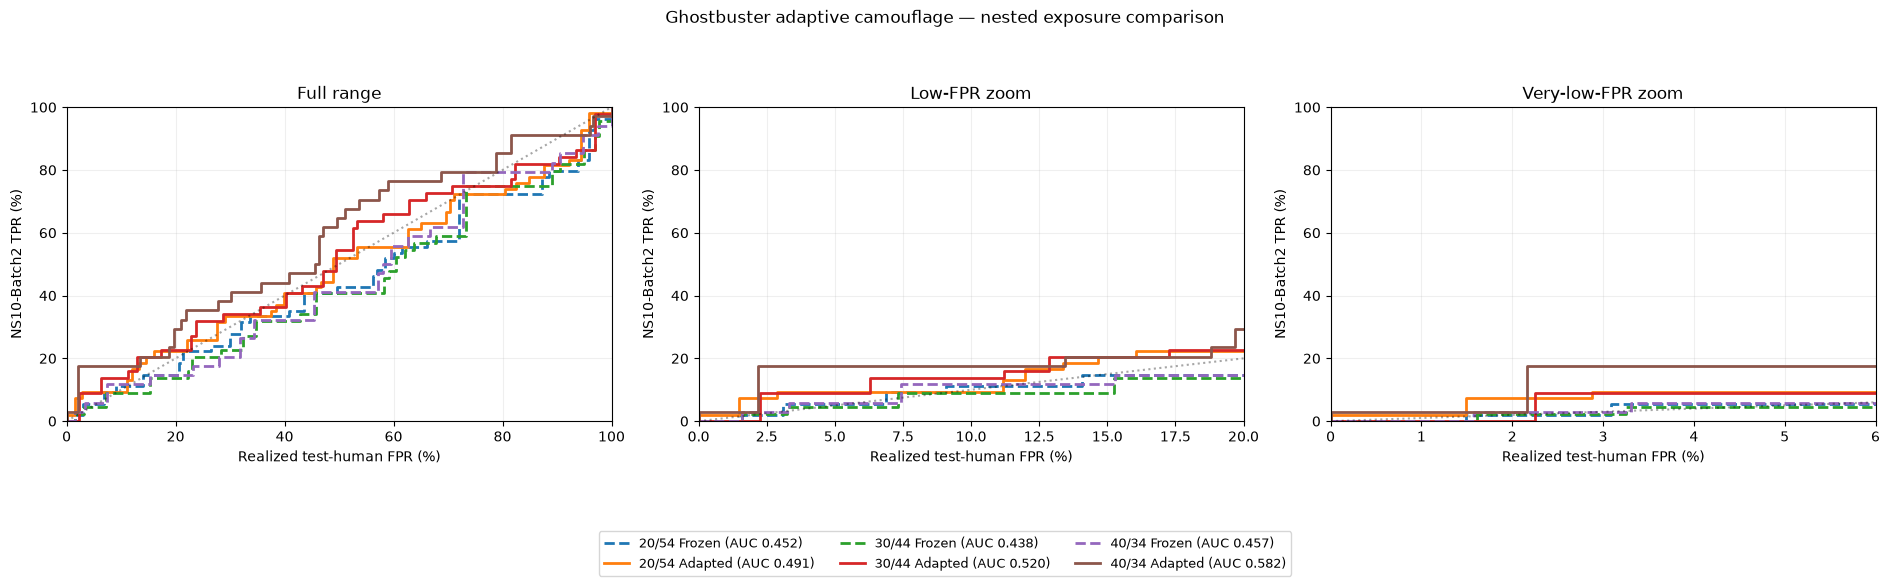

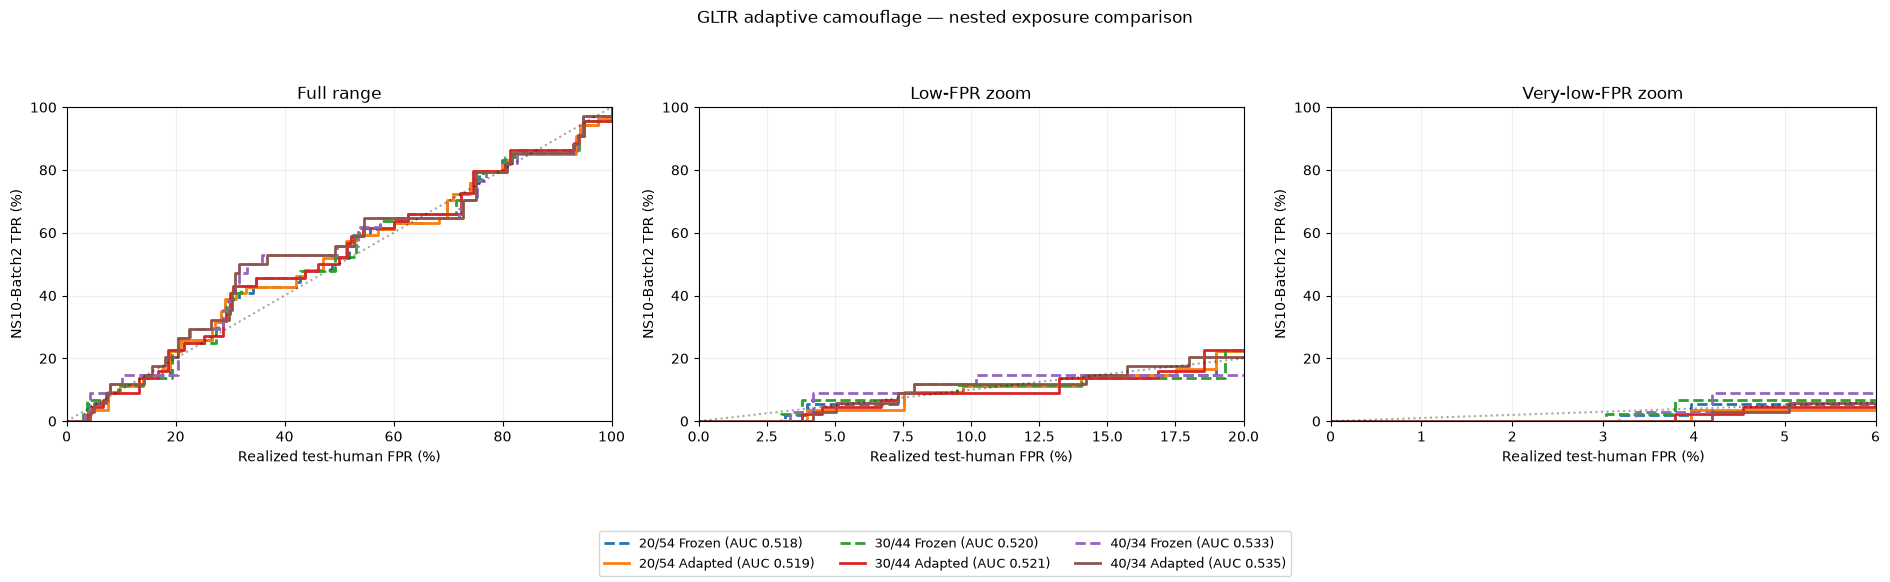

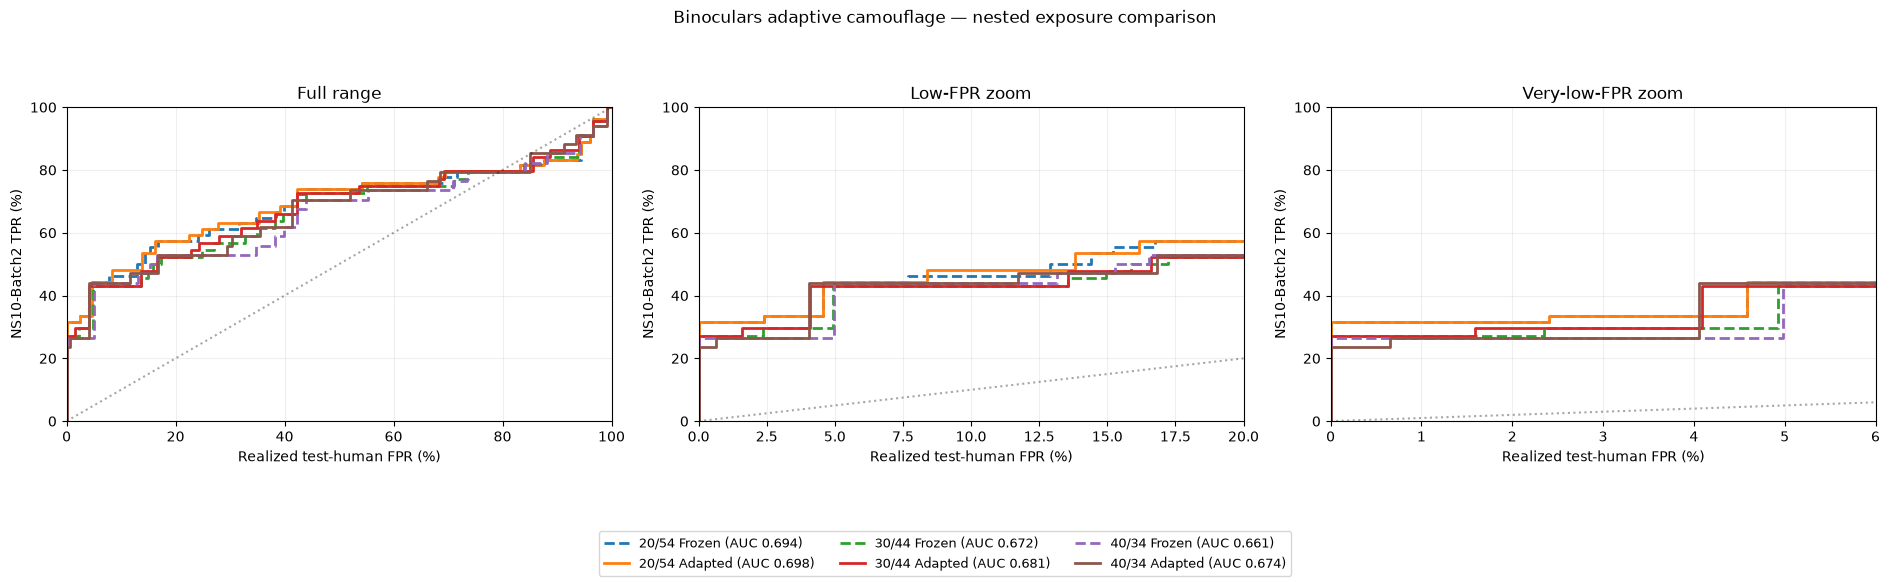

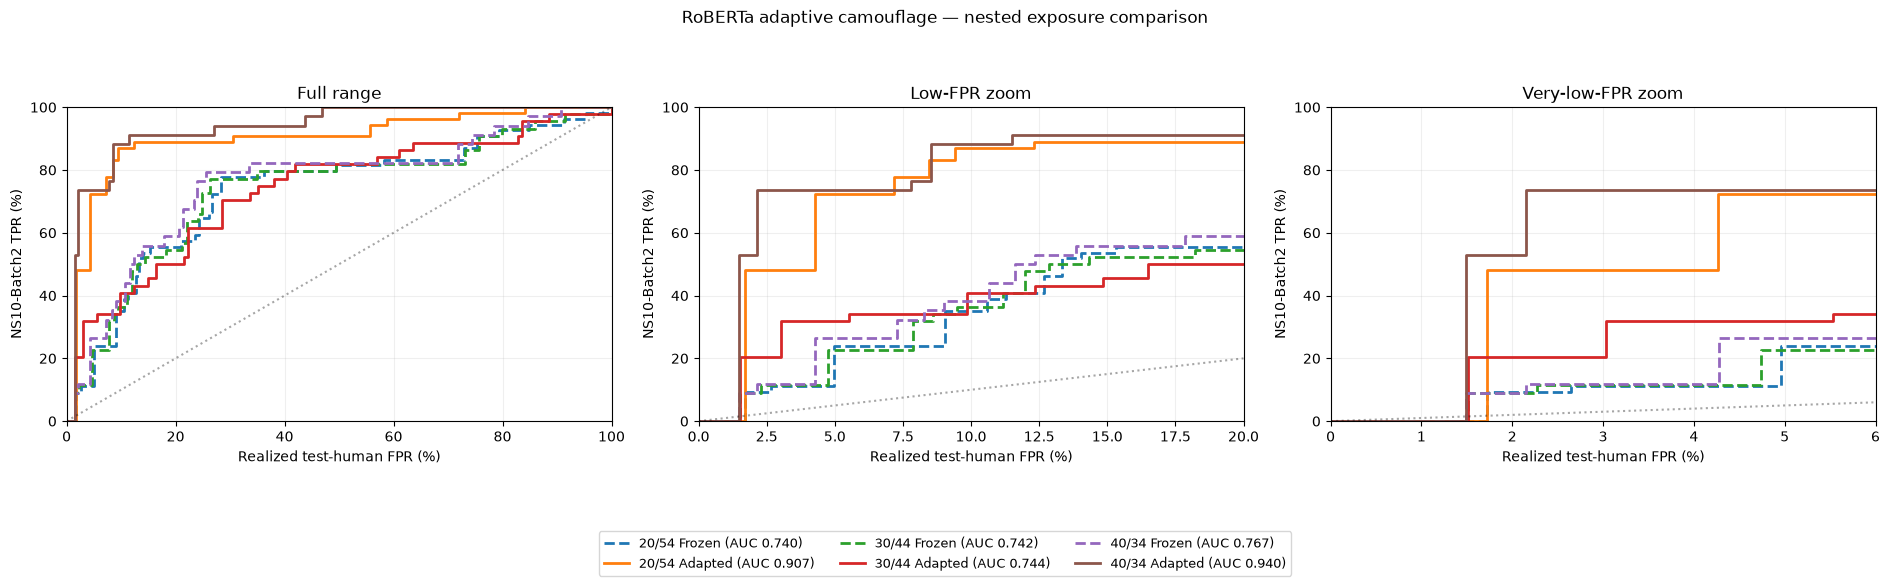

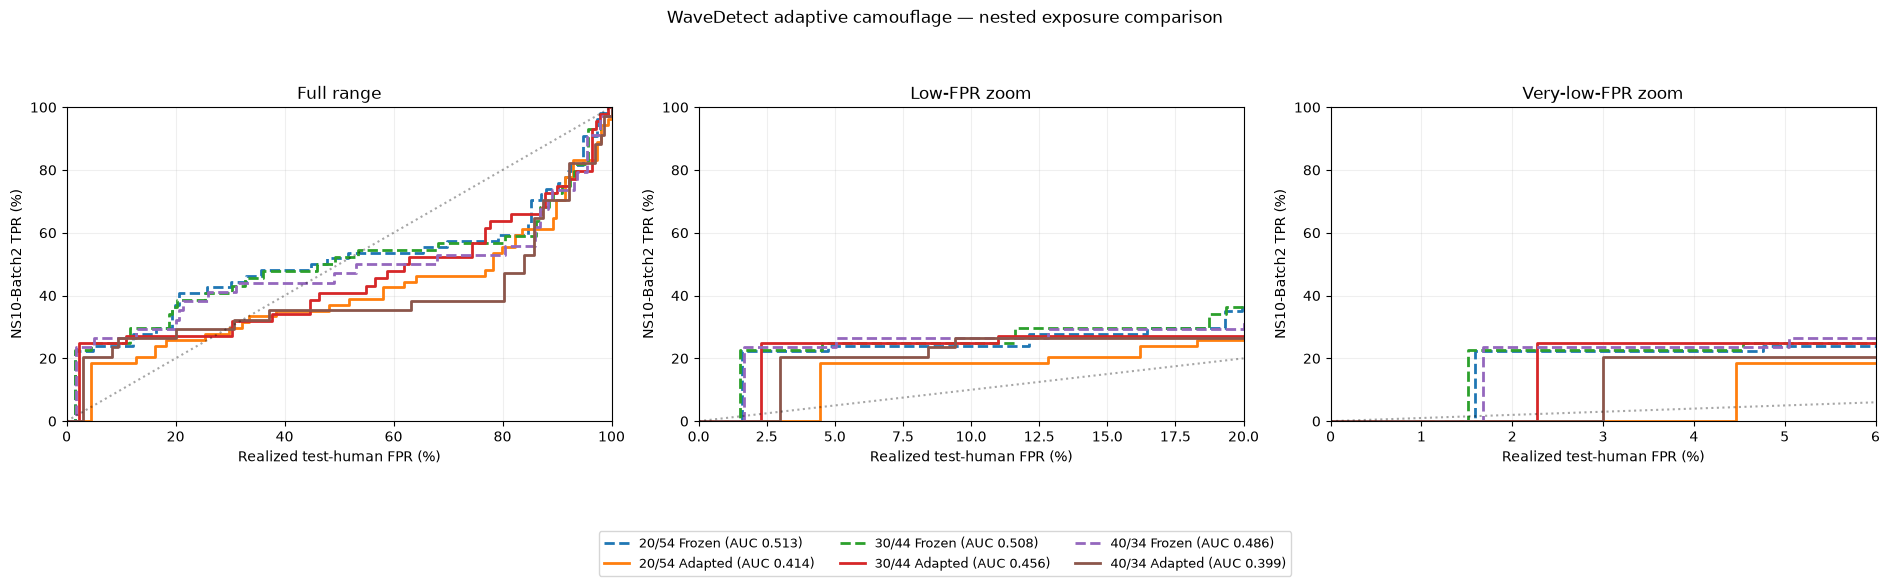

In [31]:
# ============================================================
# Combined adaptive-camouflage staircase
# 20/54 + 30/44 + 40/34 on the SAME graph
# ============================================================

DETECTORS = [
    "Ghostbuster",
    "GLTR",
    "Binoculars",
    "RoBERTa",
    "WaveDetect",
]

EXPOSURES = [20, 30, 40]

for detector in DETECTORS:

    summaries = {}
    stairs = {}

    for n in EXPOSURES:
        folder = (
            ADAPT_ROOT
            / detector
            / f"adapt{n}_{74-n}"
        )

        summary_path = folder / "summary.csv"
        staircase_path = folder / "TPR_staircase.csv"

        assert summary_path.exists(), summary_path
        assert staircase_path.exists(), staircase_path

        summaries[n] = pd.read_csv(summary_path)
        stairs[n] = pd.read_csv(staircase_path)

    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(19, 5.8),
    )

    views = [
        (100, "Full range"),
        (20, "Low-FPR zoom"),
        (6, "Very-low-FPR zoom"),
    ]

    # Different line styles distinguish frozen/adapted.
    styles = {
        "Frozen": "--",
        "Adapted": "-",
    }

    for ax, (limit, title) in zip(axes, views):

        for n in EXPOSURES:

            summary = summaries[n]
            staircase = stairs[n]

            for model_name in ["Frozen", "Adapted"]:

                q = staircase.loc[
                    staircase.model.eq(model_name)
                ]

                auc = summary.loc[
                    summary.model.eq(model_name),
                    "AUROC",
                ].iloc[0]

                ax.step(
                    100 * q.test_FPR,
                    100 * q.TPR,
                    where="post",
                    linestyle=styles[model_name],
                    linewidth=2,
                    label=(
                        f"{n}/{74-n} {model_name} "
                        f"(AUC {auc:.3f})"
                    ),
                )

        ax.plot(
            [0, limit],
            [0, limit],
            "k:",
            alpha=.35,
        )

        ax.set(
            xlim=(0, limit),
            ylim=(0, 100),
            title=title,
            xlabel="Realized test-human FPR (%)",
            ylabel="NS10-Batch2 TPR (%)",
        )

        ax.grid(alpha=.2)

    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=3,
        fontsize=9,
    )

    fig.suptitle(
        f"{detector} adaptive camouflage — "
        "nested exposure comparison"
    )

    fig.tight_layout(
        rect=[0, .17, 1, .93]
    )

    combined_dir = ADAPT_ROOT / "combined_figures"
    combined_dir.mkdir(exist_ok=True)

    for ext in ["png", "pdf"]:
        fig.savefig(
            combined_dir
            / f"{detector}_adaptive_20_30_40.{ext}",
            dpi=240,
            bbox_inches="tight",
        )

    plt.show()
    plt.close(fig)


GHOSTBUSTER — POOLED 128


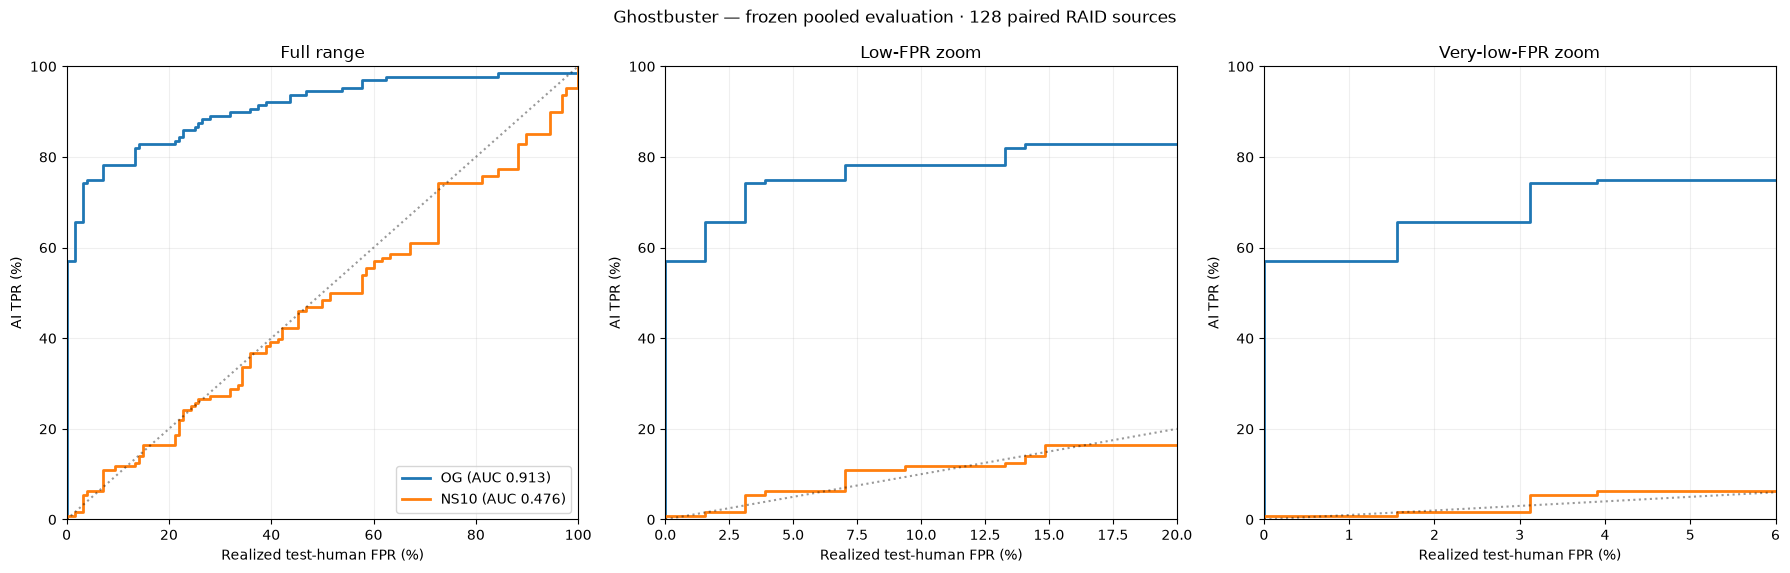


WAVEDETECT — POOLED 128


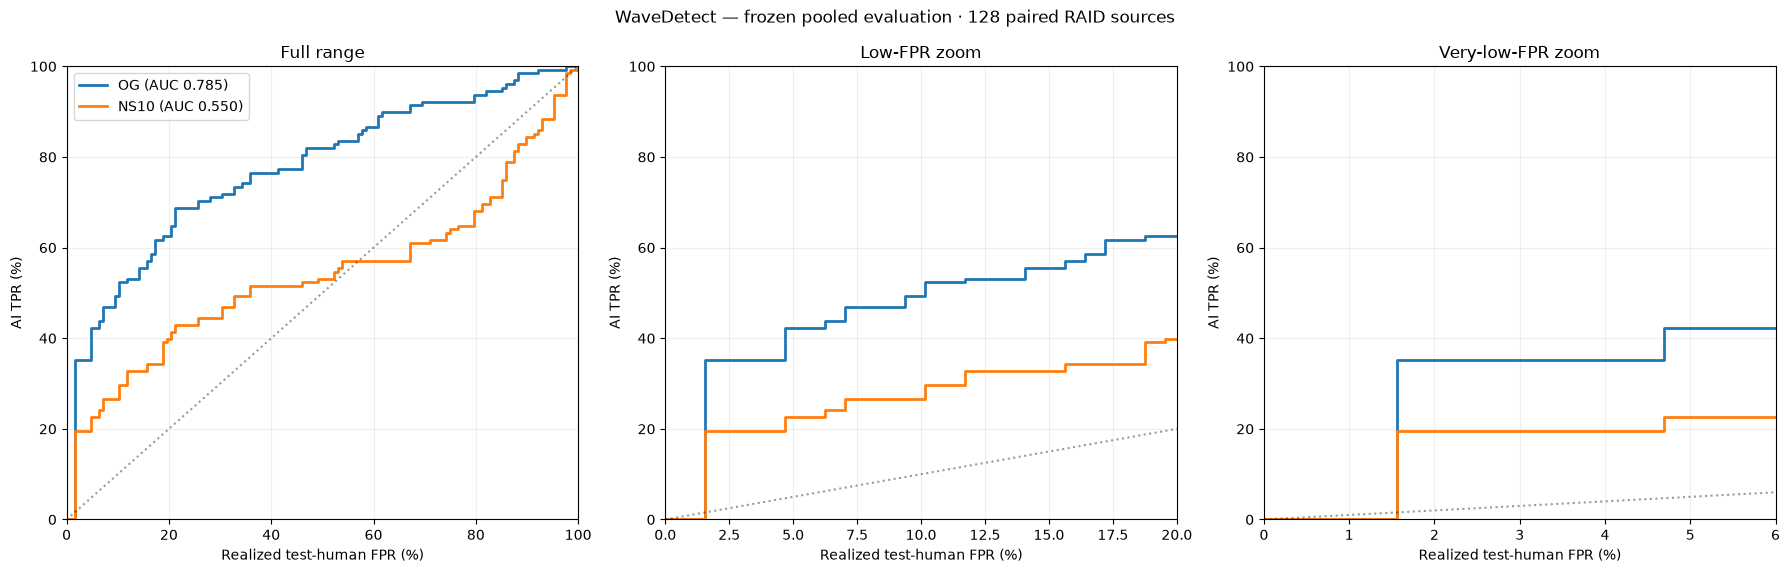


ROBERTA — POOLED 128


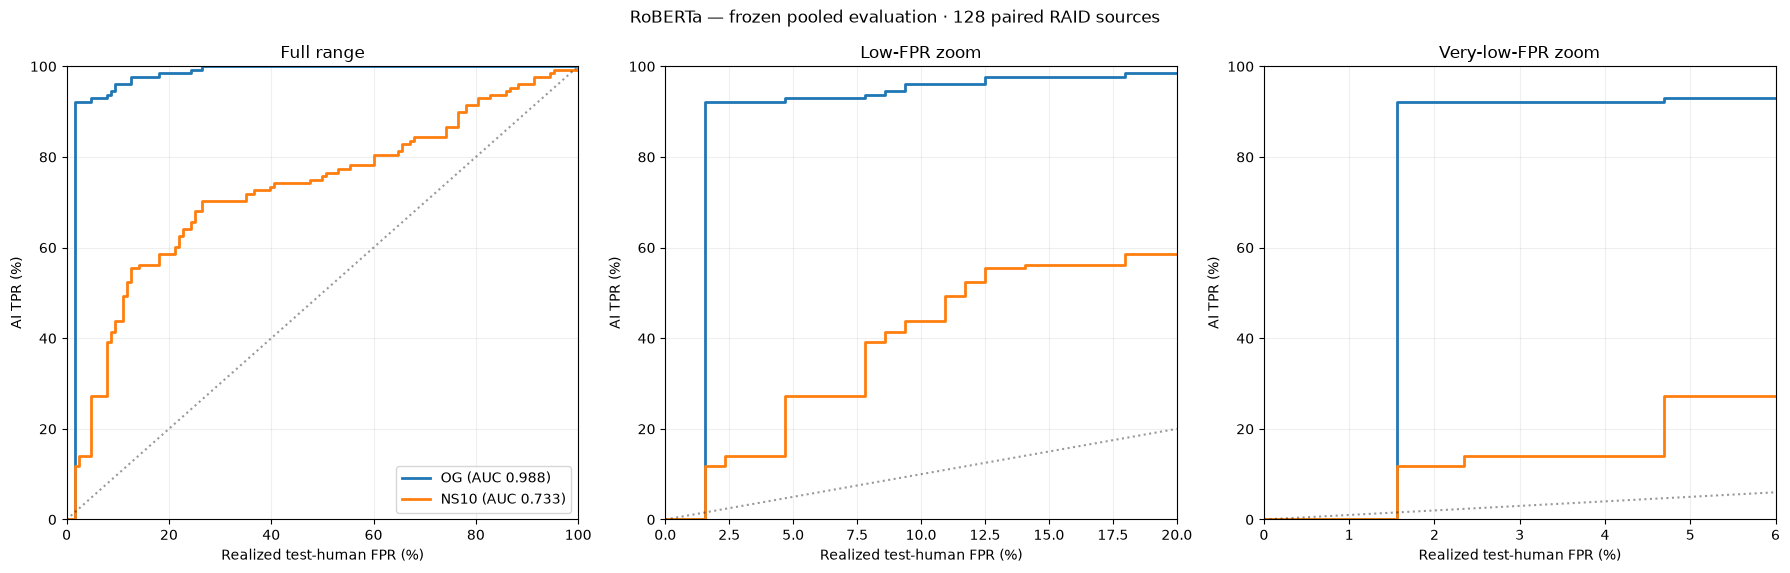


GLTR — POOLED 128


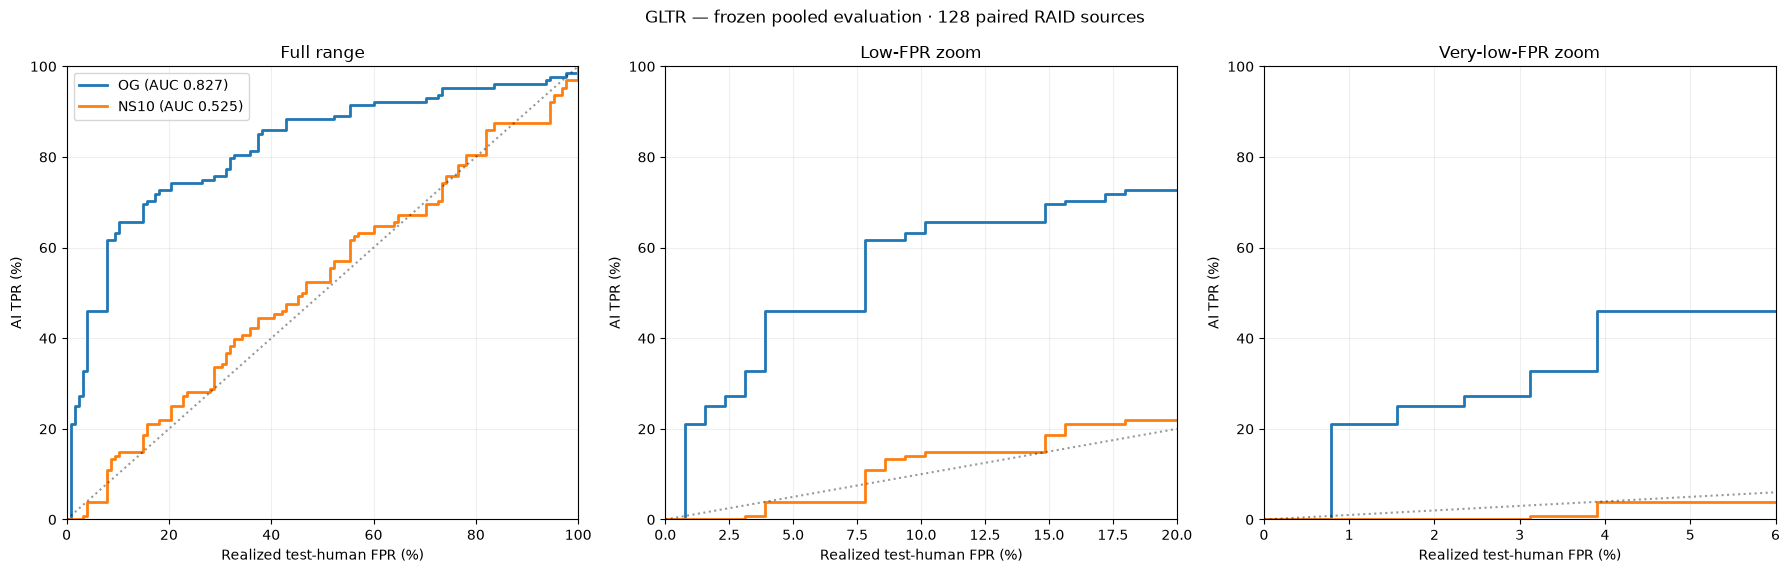


BINOCULARS — POOLED 128


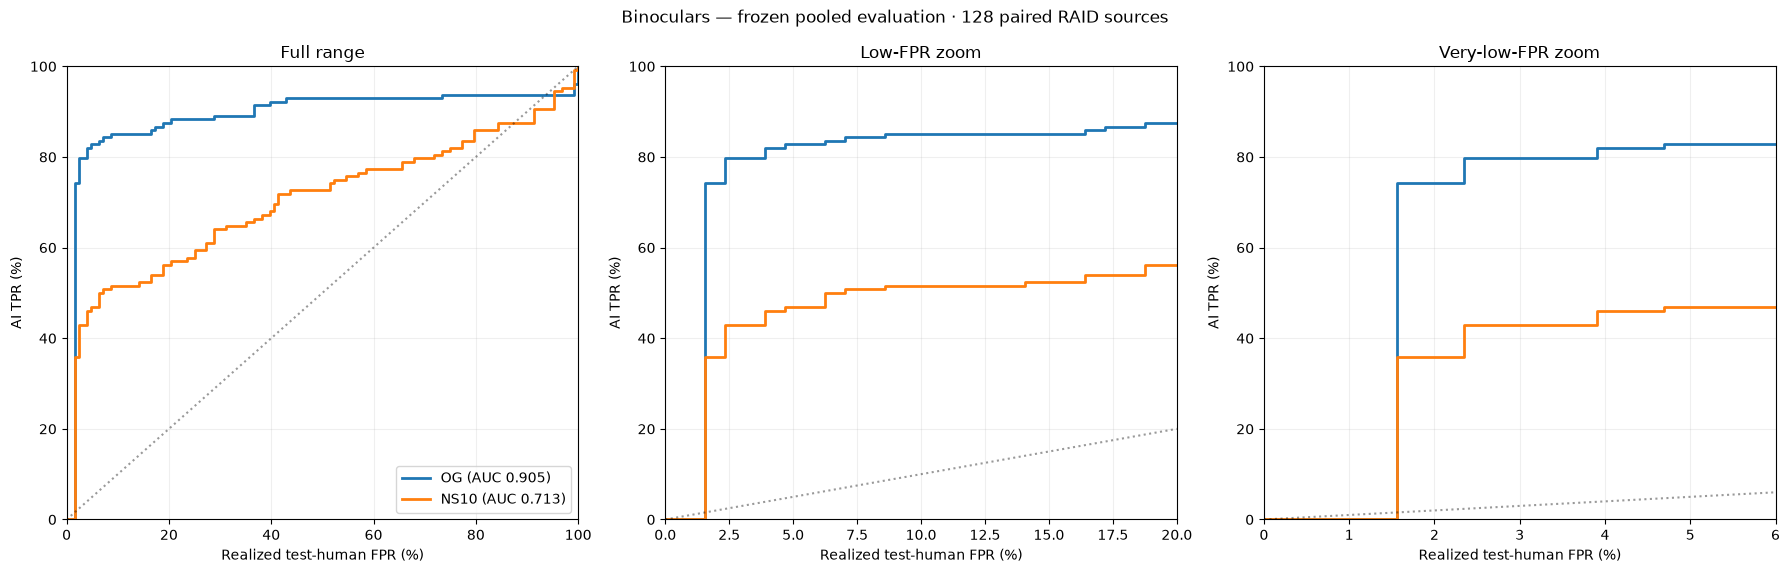


HEADLINE FROZEN AUROC — POOLED 128


detector,Binoculars,GLTR,Ghostbuster,RoBERTa,WaveDetect
arm,,,,,
OG,0.905487,0.827271,0.913208,0.987915,0.784546
NS10,0.712769,0.524658,0.476074,0.732727,0.549805



MEAN AI SCORE — POOLED 128


detector,Binoculars,GLTR,Ghostbuster,RoBERTa,WaveDetect
arm,,,,,
OG,-0.756249,0.69193,0.749575,0.923520,0.694219
NS10,-0.914999,-0.69670,0.222108,0.178507,0.494059



PAIRED OG -> NS10 AUROC CHANGE — POOLED 128


,delta_AUROC,ci_low,ci_high
detector,,,
Ghostbuster,-0.437134,-0.497620,-0.375853
WaveDetect,-0.234741,-0.302766,-0.167144
RoBERTa,-0.255188,-0.303650,-0.207121
GLTR,-0.302612,-0.355959,-0.250916
Binoculars,-0.192719,-0.257538,-0.129543


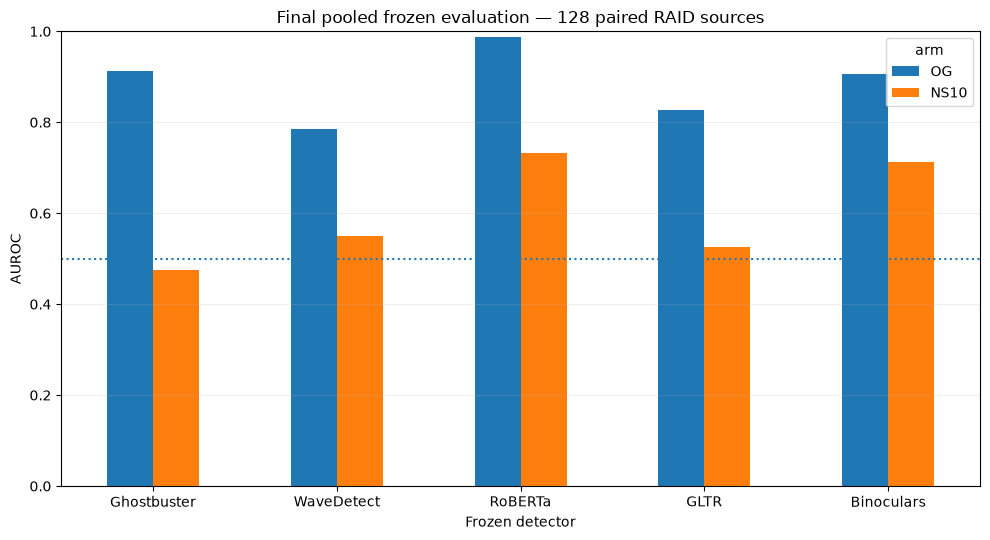


Saved final pooled headline results to:
../results/causal/C09_five_detector_pooled128_v1


In [32]:
# ============================================================
# FINAL HEADLINE FROZEN RESULT
# Pool Batch 1 (54) + Batch 2 (74) = 128 paired sources
#
# No detector inference / no adaptation.
# Reuses saved frozen scores and recomputes:
#   - genre-weighted AUROC on the pooled 128
#   - mean / median AI score
#   - paired OG -> NS10 AUROC change + bootstrap CI
#   - validation-human calibrated TPR staircases
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

B1 = R / "C08e_StealthRL_RAFT_RoBERTaGuide_v1"
B2 = R / "C09_five_detector_batch2_v1"

POOL_OUT = R / "C09_five_detector_pooled128_v1"
(POOL_OUT / "figures").mkdir(parents=True, exist_ok=True)

DETECTORS = [
    "Ghostbuster",
    "WaveDetect",
    "RoBERTa",
    "GLTR",
    "Binoculars",
]

SEED = 20260930

all_summary = []
all_changes = []
all_stairs = []
all_ops = []


def pooled_human_reference(humans, mix, split):
    q = humans.loc[
        humans.split.eq(split)
        & humans.domain.isin(mix.index)
    ].copy()

    counts = q.domain.value_counts()
    assert set(mix.index) <= set(counts.index)

    q["weight"] = [
        mix[d] / counts[d]
        for d in q.domain
    ]

    assert np.isclose(q.weight.sum(), 1)

    return q


for detector in DETECTORS:

    print("\n" + "=" * 100)
    print(detector.upper(), "— POOLED 128")
    print("=" * 100)

    p1 = B1 / "evaluation" / detector / "all_scores.csv"
    p2 = B2 / "evaluation" / detector / "all_scores.csv"

    assert p1.exists(), p1
    assert p2.exists(), p2

    s1 = pd.read_csv(p1, keep_default_na=False)
    s2 = pd.read_csv(p2, keep_default_na=False)

    # --------------------------------------------------------
    # Verify the frozen human references are identical between
    # the two evaluations.
    # --------------------------------------------------------

    h1 = (
        s1.loc[s1.arm.eq("Human")]
        .sort_values("source_id")
        .reset_index(drop=True)
    )

    h2 = (
        s2.loc[s2.arm.eq("Human")]
        .sort_values("source_id")
        .reset_index(drop=True)
    )

    assert h1.source_id.tolist() == h2.source_id.tolist()
    assert h1.split.tolist() == h2.split.tolist()
    assert h1.domain.tolist() == h2.domain.tolist()

    np.testing.assert_allclose(
        h1.AI_score.to_numpy(float),
        h2.AI_score.to_numpy(float),
        rtol=1e-7,
        atol=1e-9,
    )

    humans = h1.copy()

    # --------------------------------------------------------
    # Extract the two disjoint AI cohorts.
    # --------------------------------------------------------

    b1_og = s1.loc[s1.arm.eq("OG")].copy()
    b1_ns = s1.loc[s1.arm.eq("NS10")].copy()

    b2_og = s2.loc[s2.arm.eq("OG-Batch2")].copy()
    b2_ns = s2.loc[s2.arm.eq("NS10-Batch2")].copy()

    assert len(b1_og) == len(b1_ns) == 54
    assert len(b2_og) == len(b2_ns) == 74

    assert b1_og.source_id.is_unique
    assert b1_ns.source_id.is_unique
    assert b2_og.source_id.is_unique
    assert b2_ns.source_id.is_unique

    assert set(b1_og.source_id) == set(b1_ns.source_id)
    assert set(b2_og.source_id) == set(b2_ns.source_id)

    # The cohorts must be disjoint.
    assert set(b1_og.source_id).isdisjoint(
        set(b2_og.source_id)
    )

    assert len(
        set(b1_og.source_id)
        | set(b2_og.source_id)
    ) == 128

    # Standardize arm names.
    b1_og["arm"] = "OG"
    b1_ns["arm"] = "NS10"
    b2_og["arm"] = "OG"
    b2_ns["arm"] = "NS10"

    og128 = pd.concat(
        [b1_og, b2_og],
        ignore_index=True,
    )

    ns128 = pd.concat(
        [b1_ns, b2_ns],
        ignore_index=True,
    )

    assert len(og128) == len(ns128) == 128
    assert og128.source_id.is_unique
    assert ns128.source_id.is_unique

    # Align the exact same 128 sources.
    order = sorted(ns128.source_id.astype(str))

    og128 = (
        og128.set_index("source_id")
        .loc[order]
        .reset_index()
    )

    ns128 = (
        ns128.set_index("source_id")
        .loc[order]
        .reset_index()
    )

    assert (
        og128.source_id.tolist()
        == ns128.source_id.tolist()
    )

    assert (
        og128.domain.tolist()
        == ns128.domain.tolist()
    )

    # --------------------------------------------------------
    # Pooled 128 genre mixture.
    # --------------------------------------------------------

    mix = ns128.domain.value_counts(normalize=True)

    validation_h = pooled_human_reference(
        humans,
        mix,
        "validation",
    )

    test_h = pooled_human_reference(
        humans,
        mix,
        "test",
    )

    hs = test_h.AI_score.to_numpy(float)
    hw = test_h.weight.to_numpy(float)

    vs = validation_h.AI_score.to_numpy(float)
    vw = validation_h.weight.to_numpy(float)

    contributions = {}
    detector_stairs = []

    # --------------------------------------------------------
    # OG and NS10 pooled metrics.
    # --------------------------------------------------------

    for arm, frame in [
        ("OG", og128),
        ("NS10", ns128),
    ]:

        a = frame.AI_score.to_numpy(float)

        assert len(a) == 128
        assert np.isfinite(a).all()

        # Per-case weighted Mann-Whitney contribution.
        per_case = (
            (a[:, None] > hs)
            + 0.5 * (a[:, None] == hs)
        ) @ hw

        contributions[arm] = per_case

        all_summary.append({
            "detector": detector,
            "arm": arm,
            "cases": 128,
            "AUROC": float(per_case.mean()),
            "mean_AI_score": float(a.mean()),
            "median_AI_score": float(np.median(a)),
        })

        # Validation-human calibrated thresholds.
        cuts = np.r_[
            np.inf,
            np.unique(vs)[::-1],
            -np.inf,
        ]

        st = pd.DataFrame({
            "detector": detector,
            "arm": arm,
            "threshold": cuts,
            "calibration_FPR": [
                vw[vs > c].sum()
                for c in cuts
            ],
            "test_FPR": [
                hw[hs > c].sum()
                for c in cuts
            ],
            "TPR": [
                (a > c).mean()
                for c in cuts
            ],
        })

        detector_stairs.append(st)
        all_stairs.append(st)

        for target in [
            0,
            .001,
            .005,
            .01,
            .02,
            .05,
            .10,
            .20,
            .50,
            1.0,
        ]:
            q = st.loc[
                st.calibration_FPR
                <= target + 1e-12
            ]

            row = q.iloc[-1].to_dict()
            row["target_FPR"] = target

            all_ops.append(row)

    # --------------------------------------------------------
    # Paired OG -> NS10 AUROC reduction, 128 source bootstrap.
    # --------------------------------------------------------

    delta = (
        contributions["NS10"]
        - contributions["OG"]
    )

    rng = np.random.default_rng(SEED)

    ix = rng.integers(
        0,
        128,
        size=(10000, 128),
    )

    boot = delta[ix].mean(axis=1)

    lo, hi = np.quantile(
        boot,
        [.025, .975],
    )

    change = {
        "detector": detector,
        "comparison": "NS10_minus_OG",
        "cases": 128,
        "delta_AUROC": float(delta.mean()),
        "ci_low": float(lo),
        "ci_high": float(hi),
    }

    all_changes.append(change)

    # --------------------------------------------------------
    # Pooled staircase figure for this detector.
    # --------------------------------------------------------

    detector_summary = pd.DataFrame(
        [
            x for x in all_summary
            if x["detector"] == detector
        ]
    )

    aucs = (
        detector_summary
        .set_index("arm")
        .AUROC
    )

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(18, 5.8),
    )

    for ax, limit, title in zip(
        axes,
        [100, 20, 6],
        [
            "Full range",
            "Low-FPR zoom",
            "Very-low-FPR zoom",
        ],
    ):
        for arm in ["OG", "NS10"]:

            q = next(
                x for x in detector_stairs
                if x.arm.iloc[0] == arm
            )

            ax.step(
                100 * q.test_FPR,
                100 * q.TPR,
                where="post",
                linewidth=2,
                label=(
                    f"{arm} "
                    f"(AUC {aucs[arm]:.3f})"
                ),
            )

        ax.plot(
            [0, limit],
            [0, limit],
            "k:",
            alpha=.4,
        )

        ax.set(
            xlim=(0, limit),
            ylim=(0, 100),
            title=title,
            xlabel="Realized test-human FPR (%)",
            ylabel="AI TPR (%)",
        )

        ax.grid(alpha=.2)

    axes[0].legend()

    fig.suptitle(
        f"{detector} — frozen pooled evaluation · "
        "128 paired RAID sources"
    )

    fig.tight_layout()

    for ext in ["png", "pdf"]:
        fig.savefig(
            POOL_OUT
            / "figures"
            / f"{detector}_pooled128.{ext}",
            dpi=240,
            bbox_inches="tight",
        )

    plt.show()
    plt.close(fig)


# ============================================================
# Final headline tables
# ============================================================

summary128 = pd.DataFrame(all_summary)
changes128 = pd.DataFrame(all_changes)
stairs128 = pd.concat(all_stairs, ignore_index=True)
ops128 = pd.DataFrame(all_ops)

csv(
    summary128,
    POOL_OUT / "five_detector_summary128.csv",
)

csv(
    changes128,
    POOL_OUT / "five_detector_paired_changes128.csv",
)

csv(
    stairs128,
    POOL_OUT / "five_detector_staircases128.csv",
)

csv(
    ops128,
    POOL_OUT / "five_detector_operating_points128.csv",
)


print("\n" + "=" * 100)
print("HEADLINE FROZEN AUROC — POOLED 128")
print("=" * 100)

display(
    summary128
    .pivot(
        index="arm",
        columns="detector",
        values="AUROC",
    )
    .reindex(["OG", "NS10"])
    .round(6)
)


print("\nMEAN AI SCORE — POOLED 128")

display(
    summary128
    .pivot(
        index="arm",
        columns="detector",
        values="mean_AI_score",
    )
    .reindex(["OG", "NS10"])
    .round(6)
)


print("\nPAIRED OG -> NS10 AUROC CHANGE — POOLED 128")

display(
    changes128[
        [
            "detector",
            "delta_AUROC",
            "ci_low",
            "ci_high",
        ]
    ]
    .set_index("detector")
    .reindex(DETECTORS)
    .round(6)
)


# ============================================================
# One compact headline figure: pooled frozen AUROC
# ============================================================

pivot = (
    summary128
    .pivot(
        index="detector",
        columns="arm",
        values="AUROC",
    )
    .reindex(DETECTORS)
)

ax = pivot[["OG", "NS10"]].plot.bar(
    figsize=(10, 5.5),
    rot=0,
)

ax.axhline(
    .5,
    linestyle=":",
    linewidth=1.5,
)

ax.set(
    ylim=(0, 1),
    ylabel="AUROC",
    xlabel="Frozen detector",
    title=(
        "Final pooled frozen evaluation — "
        "128 paired RAID sources"
    ),
)

ax.grid(
    axis="y",
    alpha=.2,
)

plt.tight_layout()

for ext in ["png", "pdf"]:
    plt.savefig(
        POOL_OUT
        / "figures"
        / f"headline_frozen_AUROC_pooled128.{ext}",
        dpi=300,
        bbox_inches="tight",
    )

plt.show()
plt.close()

print("\nSaved final pooled headline results to:")
print(POOL_OUT)